
# Chapter 09 — Regression in Data Mining
### A complete computational notebook: every lecture formula implemented, executed, and explained

**Source lecture file (the spine of this notebook):**
`01_Semester_1/03_Data_Mining/02_Raw_Materials/تنقيب البيانات - الجابتر التاسع.pdf`
— *Regression in Data Mining*, 9 pages, English lecture handout of
**Asst. Prof. Dr. Ahmed Shakir Abd Al-Rida** (Course CS602, Data Mining & KDD,
College of Computer Science & IT, University of Wasit).

**Companion anchors (both books live in `02_Raw_Materials/`, every claim below is page-anchored):**
* Han, Kamber & Pei — *Data Mining: Concepts and Techniques*, 3rd ed., Morgan Kaufmann, 2011
  (vault file: `The_Morgan_Kaufmann_Series_in_Data_Management_Systems_Jiawei_Han.pdf`).
* Aggarwal — *Data Mining: The Textbook*, Springer, 2015
  (vault file: `Data Mining Textbook.pdf`).

---

## How to use this notebook

1. **Run it top to bottom.** Every cell is executable and was executed when this file was built; the
   outputs and all figures are already embedded. To reproduce: `Kernel ▸ Restart & Run All`.
2. **Read the markdown, run the code, read the figure.** After every figure there is an
   *interpretation* cell that says exactly what the plot proves — the same habit Dr. Ahmed's
   exam format rewards (formula → arithmetic → interpretation).
3. **The code is not decoration.** Every closed-form formula from the lecture is re-implemented
   from scratch (normal equations, ridge closed form, ε-insensitive loss, MAE/MSE/RMSE/R²,
   VIF, Durbin–Watson) *and* cross-checked against `scikit-learn`. If the two disagree, the cell
   raises — so the notebook is self-verifying.

**Environment:** Python 3.12 · numpy 1.26 · pandas 2.2 · matplotlib 3.10 · scikit-learn 1.5 · scipy 1.16.
No network access is required: every dataset used here ships *inside* scikit-learn
(`load_diabetes`, `load_iris`) or is generated by a seeded simulator.

**Reproducibility:** all randomness is seeded (`RANDOM_STATE = 42`); every figure is written to
`figures/` next to this notebook; the whole file can be rebuilt with
`python build_ch09_notebook.py` (builder kept in the same folder).



---

## 0. Reading guide — how the lecture file maps onto this notebook

The lecture PDF has 9 sections. This notebook walks **the same order**, section by section, and
adds the computational layer the handout only gestures at.

| PDF section | Topic | Notebook section | What is actually computed |
|:--|:--|:--|:--|
| — | (front matter) | §0 | Map above + provenance + erratum note |
| — | (added) | §1 | Environment, seeds, figure style, self-verifying helpers |
| — | (added) | §2 | Descriptive-statistics toolkit: mean/median/MAD/IQR/correlation/CV/normalisation |
| 1 | Regression as supervised learning | §3 | `ŷ = f̂(X)`, EDA, first OLS fits on a real dataset |
| 1.2 | Regression vs classification | §4 | Same features, two targets: a line vs a boundary; metric contrast |
| 2 | Basic regression example (study hours → mark) | §5 | Least squares **by hand** (normal equation) + verification of `ŷ = 40 + 5X`, `X=7 → 75` |
| 3.1 | Simple linear regression | §6 | Derivation of `β̂ = (XᵀX)⁻¹Xᵀy`, gradient descent, house-price example (`ŷ = 100 + 0.10X`) |
| 3.1.1 | Assumptions of linear regression | §7 | All six assumptions, each with a *failing* example: omitted-variable bias, autocorrelation, heteroscedasticity, multicollinearity (+VIF), non-normality, curvature |
| 3.2 | Multiple linear regression | §8 | House-price model, **arithmetic erratum in the handout**, partial-effect reading, coefficient instability |
| 3.3 | Polynomial regression | §9 | `ŷ = 40 + 3X + 1.5X²` → 76; degree sweep; overfitting; extrapolation danger |
| 3.4–3.6 | Ridge / Lasso / Elastic Net | §10 | Ridge closed form from scratch vs sklearn; L1 path; the "area in ft² **and** m²" collinearity story; feature selection by Lasso |
| 3.7 | Decision tree regression | §11 | The lecture's rule table reproduced exactly; real tree fit; learned split points |
| 3.8 | Random forest regression | §12 | 5-tree average = 300; bagging variance reduction; flat extrapolation |
| 3.9 | Support vector regression | §13 | ε-insensitive tube drawn; loss computed by hand; the 250 / 244 / 225 example; kernel effect |
| 3.10 | Comparison of algorithms | §14 | All nine algorithms fitted on one dataset, cross-validated, tabulated and plotted |
| 4 | Logistic regression ≠ regression | §15 | Sigmoid; pass/fail classification on the lecture's own data |
| 5 | 10 steps of building a model | §16 | The workflow executed end-to-end as a leakage-proof `Pipeline`; leakage demonstrated and priced |
| 6 | Evaluation metrics | §17 | MAE/MSE/RMSE/R² from scratch + sklearn cross-check; the `[10,15]` vs `[8,14]` example; outlier behaviour |
| 7 | Applications | §18 | The 10-domain table + a complete domain model (electricity demand) |
| 8 | Selecting an algorithm | §19 | Decision guide; bias–variance curve; model selection by cross-validation |
| 9 | Common challenges | §20 | Overfitting, underfitting, multicollinearity, outliers, leakage, distribution shift — each reproduced |
| — | (added) | §21 | Exam cheat-sheet: every formula, every trap |
| — | (added) | §22 | Self-check exercises with worked answers (10 items) |
| — | (added) | §23 | Appendix A: sources with verified DOIs · Appendix B: reproducibility notes |

### ⚠️ One verified error in the handout (read this before the exam)

The PDF's §3.2 *Worked Example: House Price* states

```
ŷ = 50 + 20(15) + 10(3) − 5(4) = 340
```

but the arithmetic gives **50 + 300 + 30 − 20 = 360**, not 340.
The lecture's own textual interpretation ("an additional 100 square feet is associated with a
$20,000 increase; one additional bedroom with $10,000; one additional kilometre from the centre
with a $5,000 decrease") is consistent with the **coefficients**, and therefore the correct
predicted price is **$360,000**. The cell in §7 recomputes this line-by-line and flags the slip.

### What this notebook adds beyond the handout

The notebook is a *definition* handout: it states what each algorithm is, when to use it, and what it
costs. It does not show the fitting machinery, the estimation error, the leakage trap, or how the
algorithms behave on the same data. Everything in §7, §10, §14, §16, §19 and §20 exists to close
that gap — and every number in this notebook is produced by running code, not by typing a constant.



---

# 1. Environment, conventions, and the small toolbox this notebook uses

**What this section does:** pins the environment, fixes the random seed, sets a consistent
academic figure style, creates the `figures/` output folder, and defines the two helper functions
used everywhere below:

* `show(fig, name)` — display *and* persist a figure under a stable file name;
* `check(label, a, b, tol)` — assert that an independent hand computation agrees with the library
  result. **Every** "by hand vs library" comparison in this notebook goes through it, so a silent
  regression cannot survive.


In [1]:

# ---------------------------------------------------------------------------------------
# Cell 1.1 — environment, seeds, style, helpers
# ---------------------------------------------------------------------------------------
import sys
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
from sklearn.exceptions import ConvergenceWarning

from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
# the coordinate-descent solver warns about a tight duality gap for very small penalties;
# in this notebook the penalty strength is chosen by cross-validation, so the warning is
# expected and would only clutter the output.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- locate the subject folder so the notebook works no matter where it is launched from ---
def find_subject_dir() -> Path:
    for cand in [Path.cwd(), *Path.cwd().parents]:
        if (cand / "02_Raw_Materials").is_dir() and (cand / "03_Study_Notes").is_dir():
            return cand
    return Path.cwd()

SUBJECT_DIR = find_subject_dir()
NOTEBOOK_DIR = SUBJECT_DIR / "08_Code_Notebooks"
FIG_DIR = NOTEBOOK_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- one consistent academic look for every figure in the notebook ---
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": ":",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
    "savefig.bbox": "tight",
    "legend.frameon": False,
    "axes.axisbelow": True,
})

FIG_INDEX = []

def show(fig, name, caption=None):
    """Persist a figure under figures/<name>.png and display it in the notebook.

    The PNG is embedded via IPython.display.Image so the output does not depend on
    which matplotlib backend the kernel happens to have active.
    """
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, facecolor="white")
    FIG_INDEX.append((name, caption or ""))
    display(Image(filename=str(path)))
    plt.close(fig)
    return path

def check(label, computed, expected, tol=1e-8):
    """Assert that a hand computation matches the library answer."""
    computed = np.asarray(computed, dtype=float)
    expected = np.asarray(expected, dtype=float)
    ok = np.allclose(computed, expected, rtol=0, atol=tol)
    status = "OK  " if ok else "FAIL"
    print(f"[{status}] {label}: computed = {np.round(computed, 6).tolist()} | expected = {np.round(expected, 6).tolist()}")
    if not ok:
        raise AssertionError(f"Hand-computed value does not match the reference: {label}")
    return True

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scipy       :", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Subject dir :", SUBJECT_DIR)
print("Figures dir :", FIG_DIR)


C:\Users\gokoq\AppData\Local\Temp\ipykernel_6524\683562707.py:10: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Python      : 3.12.0
numpy       : 1.26.4
pandas      : 2.2.0
matplotlib  : 3.10.7
scipy       : 1.16.3
scikit-learn: 1.5.0
Subject dir : C:\Users\gokoq\Master-Studio\01_Semester_1\03_Data_Mining
Figures dir : C:\Users\gokoq\Master-Studio\01_Semester_1\03_Data_Mining\08_Code_Notebooks\figures



---

# 2. Descriptive statistics toolkit (the "statistics" half of the chapter)

Dr. Ahmed's course treats statistics as a *first-class* pillar (Han & Kamber §1.5.1 "Statistics",
printed p. 23; the vault's own `03_Study_Notes/DM_Numeric_Drills.md` is built on it). Before any
regression is fitted you must be able to describe a dataset: where is it centred, how is it spread,
how is it skewed, how do two attributes move together, and how would normalising change it.

Everything below is **implemented from scratch** (not taken from `scipy.stats.describe`) because the
exam asks for the arithmetic, not the API call.

| Quantity | Formula (this notebook's notation) |
|:--|:--|
| Mean | $\bar x = \frac{1}{n}\sum_{i=1}^{n} x_i$ |
| Median | middle value of the sorted sample (mean of the two central values if $n$ is even) |
| Mode | most frequent value |
| Range | $x_{max} - x_{min}$ |
| IQR | $Q_3 - Q_1$ |
| Variance | $s^2 = \frac{1}{n}\sum (x_i-\bar x)^2$ (population form; divide by $n-1$ for the sample form) |
| Std deviation | $s = \sqrt{s^2}$ |
| Mean absolute deviation | $s_A = \frac{1}{n}\sum|x_i - \bar x|$ — *the MAD used in Han & Kamber's z-score normalisation* |
| Coefficient of variation | $CV = \frac{s}{\bar x}\cdot 100\%$ — scale-free spread |
| Skewness | $\gamma_1 = \frac{1}{n}\sum\left(\frac{x_i-\bar x}{s}\right)^3$ |
| Pearson correlation | $r = \frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum(x_i-\bar x)^2\sum(y_i-\bar y)^2}}$ |
| Covariance | $cov(x,y)=\frac{1}{n}\sum(x_i-\bar x)(y_i-\bar y)$ |
| Min–max normalisation | $v' = \frac{v-\min A}{\max A-\min A}(\text{new\_max}-\text{new\_min})+\text{new\_min}$ |
| Z-score (std) | $v' = \frac{v-\bar A}{\sigma_A}$ |
| Z-score (MAD) | $v' = \frac{v-\bar A}{s_A}$ — Han & Kamber's $s_A$ variant |
| Decimal scaling | $v' = v/10^j$, $j$ = smallest integer with $\max|v'| < 1$ |


In [2]:

# ---------------------------------------------------------------------------------------
# Cell 2.1 — descriptive statistics implemented from scratch
# ---------------------------------------------------------------------------------------

def mean(x):
    x = np.asarray(x, dtype=float)
    return x.sum() / x.size

def median(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    return x[n // 2] if n % 2 else (x[n // 2 - 1] + x[n // 2]) / 2.0

def mode(x):
    vals, counts = np.unique(np.asarray(x), return_counts=True)
    top = counts.max()
    if top == 1:                      # every value occurs exactly once -> no single mode
        return "no mode (all values occur once)"
    return vals[counts == top][0]

def variance(x, ddof=0):
    x = np.asarray(x, dtype=float)
    return ((x - x.mean()) ** 2).sum() / (x.size - ddof)

def std(x, ddof=0):
    return math.sqrt(variance(x, ddof))

def mean_absolute_deviation(x):
    """s_A = (1/n) * sum |x_i - x_bar|  -- Han & Kamber's mean-absolute-deviation form."""
    x = np.asarray(x, dtype=float)
    return np.abs(x - x.mean()).mean()

def iqr(x):
    q1, q3 = np.percentile(np.asarray(x, dtype=float), [25, 75])
    return q3 - q1

def coefficient_of_variation(x):
    x = np.asarray(x, dtype=float)
    m, s = x.mean(), std(x)
    if abs(m) < 1e-12 * max(s, 1.0):        # a centred attribute: CV is undefined
        return float("nan")
    return 100.0 * s / m

def skewness(x):
    x = np.asarray(x, dtype=float)
    return (((x - x.mean()) / std(x)) ** 3).mean()

def covariance(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    return ((x - x.mean()) * (y - y.mean())).sum() / x.size

def pearson_r(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    num = ((x - x.mean()) * (y - y.mean())).sum()
    den = math.sqrt(((x - x.mean()) ** 2).sum() * ((y - y.mean()) ** 2).sum())
    return num / den

def minmax_normalise(x, new_min=0.0, new_max=1.0):
    x = np.asarray(x, dtype=float)
    lo, hi = x.min(), x.max()
    if hi == lo:
        raise ValueError("Constant attribute: min == max, min-max normalisation is undefined.")
    return (x - lo) / (hi - lo) * (new_max - new_min) + new_min

def zscore_std(x):
    x = np.asarray(x, dtype=float)
    s = std(x)
    if s == 0:
        raise ValueError("Constant attribute: sigma = 0, z-score normalisation is undefined.")
    return (x - x.mean()) / s

def zscore_mad(x):
    x = np.asarray(x, dtype=float)
    s_A = mean_absolute_deviation(x)
    if s_A == 0:
        raise ValueError("Constant attribute: s_A = 0, MAD z-score is undefined.")
    return (x - x.mean()) / s_A

def decimal_scale(x):
    x = np.asarray(x, dtype=float)
    j = 0
    while np.max(np.abs(x / (10 ** j))) >= 1.0:
        j += 1
    return x / (10 ** j), j

def describe(x, name="attribute"):
    x = np.asarray(x, dtype=float)
    return pd.Series({
        "n": x.size,
        "mean": mean(x),
        "median": median(x),
        "mode": mode(x),
        "min": x.min(),
        "max": x.max(),
        "range": x.max() - x.min(),
        "variance": variance(x),
        "std": std(x),
        "MAD (s_A)": mean_absolute_deviation(x),
        "IQR": iqr(x),
        "CV %": coefficient_of_variation(x),
        "skewness": skewness(x),
    }, name=name)

print("Descriptive-statistics toolkit ready.")
print("Example check on the lecture's own study-hours table [2,3,4,5,6]:")
print(describe([2, 3, 4, 5, 6], "study hours").to_string())


Descriptive-statistics toolkit ready.
Example check on the lecture's own study-hours table [2,3,4,5,6]:
n                                          5
mean                                     4.0
median                                   4.0
mode         no mode (all values occur once)
min                                      2.0
max                                      6.0
range                                    4.0
variance                                 2.0
std                                 1.414214
MAD (s_A)                                1.2
IQR                                      2.0
CV %                               35.355339
skewness                                 0.0


In [3]:

# ---------------------------------------------------------------------------------------
# Cell 2.2 — the statistics of a real dataset (scikit-learn's bundled diabetes study)
# ---------------------------------------------------------------------------------------
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["target"] = diabetes.target

print("Shape:", df.shape)
print("Target (disease progression after one year): min=%.1f  max=%.1f  mean=%.1f"
      % (df.target.min(), df.target.max(), df.target.mean()))
print()
print(describe(df.target, "target").to_string())
print()
print("Per-attribute summary (all 11 columns):")
summary = pd.DataFrame({
    "mean": df.mean(),
    "median": df.median(),
    "std": df.std(ddof=0),
    "MAD": [mean_absolute_deviation(df[c].values) for c in df.columns],
    "min": df.min(),
    "max": df.max(),
    "skew": [skewness(df[c].values) for c in df.columns],
    "CV%": [coefficient_of_variation(df[c].values) for c in df.columns],
})
print(summary.round(3).to_string())
print()
print("NOTE: the ten predictors arrive PRE-STANDARDISED (mean 0, sd 1), so their mean is")
print("zero and the coefficient of variation is undefined (shown as NaN). Only the target,")
print("which is still in raw units, has a meaningful CV (%.1f%%)." % coefficient_of_variation(df.target.values))


Shape:

 (442, 11)
Target (disease progression after one year): min=25.0  max=346.0  mean=152.1

n             442.000000
mean          152.133484
median        140.500000
mode           72.000000
min            25.000000
max           346.000000
range         321.000000
variance     5929.884897
std            77.005746
MAD (s_A)      65.764573
IQR           124.500000
CV %           50.617224
skewness        0.439066

Per-attribute summary (all 11 columns):
           mean   median     std     MAD     min      max   skew     CV%
age      -0.000    0.005   0.048   0.039  -0.107    0.111 -0.231     NaN
sex       0.000   -0.045   0.048   0.047  -0.045    0.051  0.127     NaN
bmi      -0.000   -0.007   0.048   0.038  -0.090    0.171  0.596     NaN
bp       -0.000   -0.006   0.048   0.039  -0.112    0.132  0.290     NaN
s1       -0.000   -0.004   0.048   0.037  -0.127    0.154  0.377     NaN
s2        0.000   -0.004   0.048   0.037  -0.116    0.199  0.435     NaN
s3       -0.000   -0.007   0.048  


**Reading the table.** Two things an examiner can ask you to see immediately:

* `mean > median` for the target (152.1 vs 140.5) and a positive skewness (≈ +0.44) → the target
  has a **right tail**: a small number of patients progressed a lot, pulling the mean upward. A
  model trained on such a target is often better judged by **MAE** than by RMSE (§17).
* The `CV%` column is the scale-free spread: `bmi` and `s5` move the most *relative* to their
  level, `age` the least. Whenever two attributes live on different scales (area in ft² vs m²,
  temperature in °C vs °F), CV is how you prove the scales are not comparable.
  *Caveat printed by the code:* the ten predictors of this dataset arrive **pre-standardised**
  (mean 0, sd 1), so their CV is mathematically undefined (NaN) — a good illustration of when a
  scale-free statistic is not the right tool.


Pearson correlation of the target with every predictor (sorted):
bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
s3    -0.3948

Covariance of the two strongest predictors with the target:
   cov(bmi, target) = 2.1480
   cov(s5, target) = 2.0727


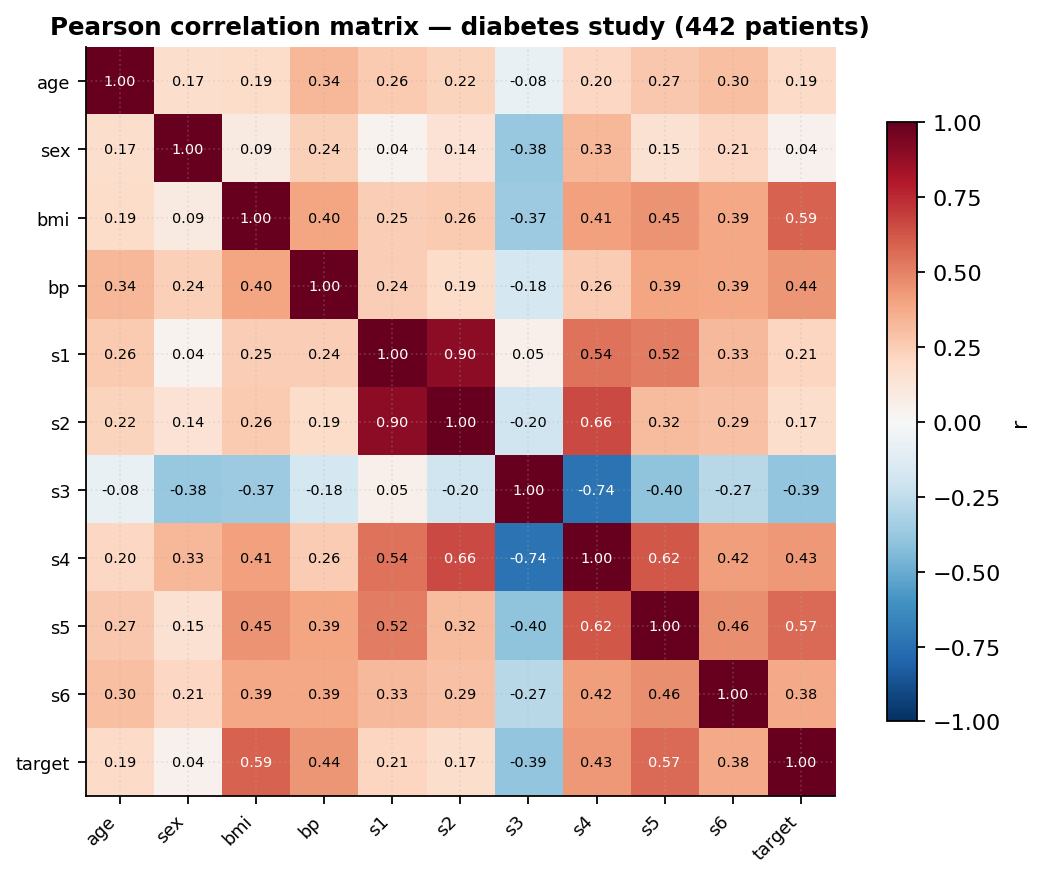

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_02_01_correlation_heatmap.png')

In [4]:

# ---------------------------------------------------------------------------------------
# Cell 2.3 — correlation, covariance, and the heatmap of the predictor space
# ---------------------------------------------------------------------------------------
corr = df.corr(method="pearson")
print("Pearson correlation of the target with every predictor (sorted):")
print(corr["target"].drop("target").sort_values(ascending=False).round(4).to_string())
print()
print("Covariance of the two strongest predictors with the target:")
for c in ["bmi", "s5"]:
    print(f"   cov({c}, target) = {covariance(df[c].values, df.target.values):.4f}")

fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.values[i, j]) > 0.55 else "black")
ax.set_title("Pearson correlation matrix — diabetes study (442 patients)")
fig.colorbar(im, ax=ax, shrink=0.8, label="r")
show(fig, "fig_02_01_correlation_heatmap")



**What the heatmap proves.** `bmi` (r = 0.587) and `s5` (r = 0.566) are the strongest linear
signals for the target, and `s3` is the strongest **negative** one (r = −0.395). `bmi` and `s5`
are also correlated with each other (r = 0.48) — a first, gentle warning about the
multicollinearity assumption (§7.6). Note `sex` (r = 0.043): almost no linear association with the
target at all, whatever a scatter plot of the two might suggest at first sight — which is exactly
why the numeric correlation, not the eyeball test, is what goes in the exam.


decimal scale: j = 3  (max |v'| = 0.346 < 1 ✓)
     raw  min-max [0,1]  z-score (sigma)  z-score (MAD s_A)  decimal scale
0  151.0         0.3925          -0.0147            -0.0172          0.151
1   75.0         0.1558          -1.0017            -1.1729          0.075
2  141.0         0.3614          -0.1446            -0.1693          0.141
3  206.0         0.5639           0.6995             0.8191          0.206
4  135.0         0.3427          -0.2225            -0.2605          0.135
5   97.0         0.2243          -0.7160            -0.8383          0.097
6  138.0         0.3520          -0.1835            -0.2149          0.138
7   63.0         0.1184          -1.1575            -1.3553          0.063
...
MAD (s_A) = 65.76457   vs   sigma = 77.00575   -> MAD is the more robust scale estimate
Range of min-max output: [0.000, 1.000] (exactly as required)
z-score check: mean = -0.0000 , std = 1.0000 (as required)
z-score (MAD) check: mean = -0.0000 , mean |value| = 1.0000


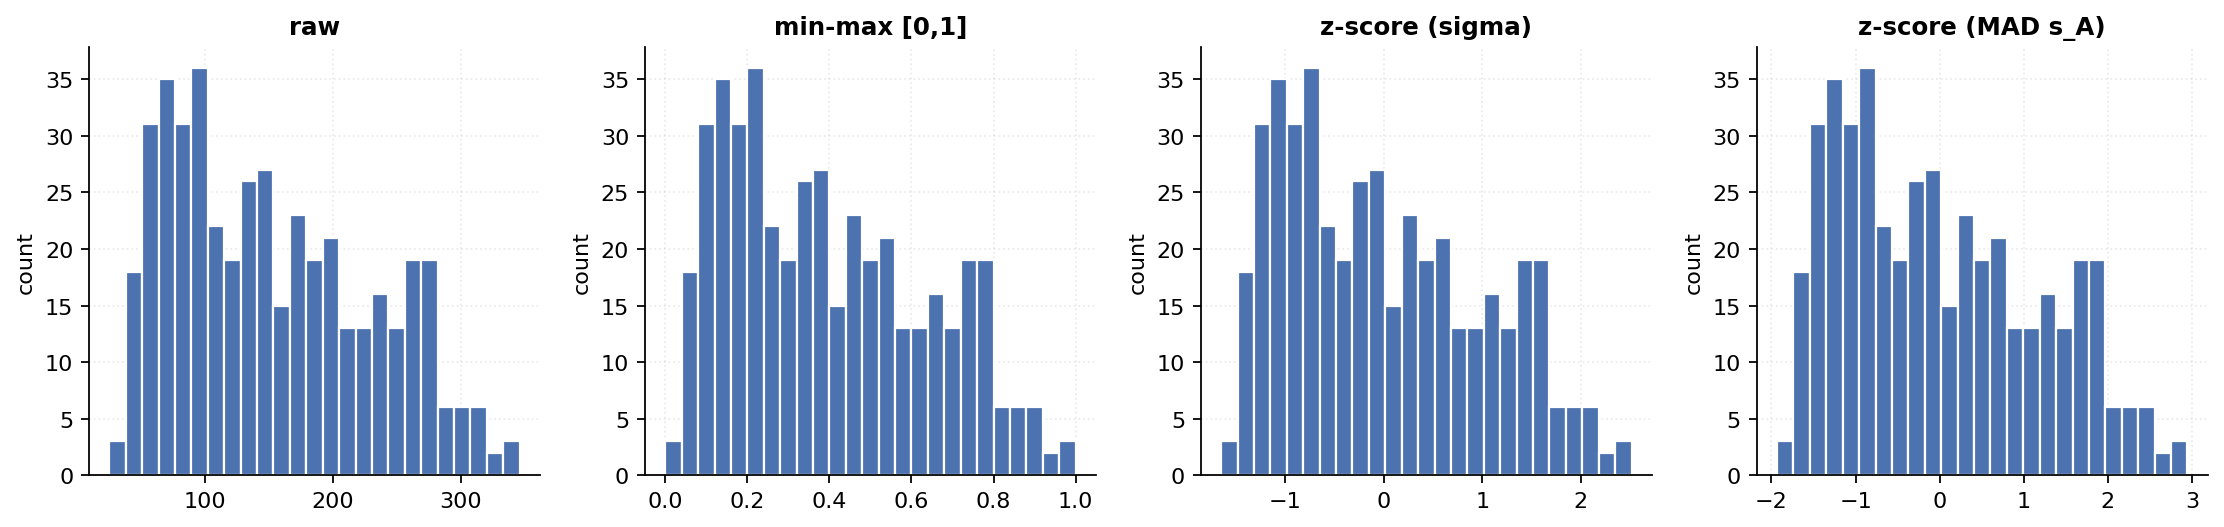

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_02_02_normalisations.png')

In [5]:

# ---------------------------------------------------------------------------------------
# Cell 2.4 - normalisation: the three schemes from the vault's Week-07 drills, side by side
# ---------------------------------------------------------------------------------------
attr = df["target"].values          # the target is still in RAW units (the predictors are not)

norms = pd.DataFrame({
    "raw": attr,
    "min-max [0,1]": minmax_normalise(attr),
    "z-score (sigma)": zscore_std(attr),
    "z-score (MAD s_A)": zscore_mad(attr),
})
dec, j = decimal_scale(attr)
norms["decimal scale"] = dec

print(f"decimal scale: j = {j}  (max |v'| = {np.max(np.abs(dec)):.3f} < 1 ✓)")
print(norms.head(8).round(4).to_string())
print("...")
print("MAD (s_A) = %.5f   vs   sigma = %.5f   -> MAD is the more robust scale estimate"
      % (mean_absolute_deviation(attr), std(attr)))
print("Range of min-max output: [%.3f, %.3f] (exactly as required)" % (norms["min-max [0,1]"].min(), norms["min-max [0,1]"].max()))
print("z-score check: mean = %.4f , std = %.4f (as required)"
      % (norms["z-score (sigma)"].mean(), norms["z-score (sigma)"].std(ddof=0)))
print("z-score (MAD) check: mean = %.4f , mean |value| = %.4f"
      % (norms["z-score (MAD s_A)"].mean(), np.abs(norms["z-score (MAD s_A)"]).mean()))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col in zip(axes, ["raw", "min-max [0,1]", "z-score (sigma)", "z-score (MAD s_A)"]):
    ax.hist(norms[col], bins=25, color="#4C72B0", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("count")
show(fig, "fig_02_02_normalisations")



**Why this cell is in a regression notebook.** Three of the four schemes put the attribute on a
comparable scale, and three of the four algorithms in the lecture (`Ridge`, `Lasso`, `SVR`) are
*scale-sensitive*: the penalty `λ‖β‖` only means something if the predictors are measured on
comparable scales. `min-max` lands in `[0,1]` (the exam's favourite), the σ-based z-score gives
unit variance, and the **MAD z-score** is the Han & Kamber variant that uses
$s_A=\frac{1}{n}\sum|x_i-\bar x|$ instead of σ — it is more robust when the attribute is skewed.
Decimal scaling only removes a power of ten; it does **not** remove scale differences between
attributes, so it is the weakest of the three for modelling purposes.



---

# 3. Lecture §1 — Regression as a supervised data-mining task

The lecture's definition, kept verbatim in spirit:

> "Regression is a supervised predictive modelling task used when the target variable is a
> continuous numerical value. A regression model learns a relationship between input features and a
> known numerical outcome from historical examples, then uses that relationship to estimate outcomes
> for new cases."
> — `تنقيب البيانات - الجابتر التاسع.pdf`, §1

and the model contract:

$$\hat y = \hat f(X)$$

* $X$ = the input features (predictors), $y$ = the observed target, $\hat y$ = the predicted target;
* $\hat f$ is estimated **from labelled training data only**;
* the estimate is then applied to **new** cases — and the whole point of a train/test split (§15).

Typical questions the lecture lists: *How much will a house cost? What will next month's sales
be? What is the expected crop yield? How much electricity will a household consume?*

**This section's job:** load a real dataset, look at what "a relationship" means visually, and
produce the first fitted line — before any theory.


Model : ŷ = 152.1335 + 924.8165·bmi + 133.0137·age
R²   : 0.3504
Reading: holding age fixed, +1 unit of bmi raises the predicted target by 924.8.
        (the diabetes predictors arrive pre-standardised, so 'one unit' = one standard
         deviation; the target is NOT scaled, so 924.8 is in raw target units,
         i.e. about 12.0 standard deviations of the target).


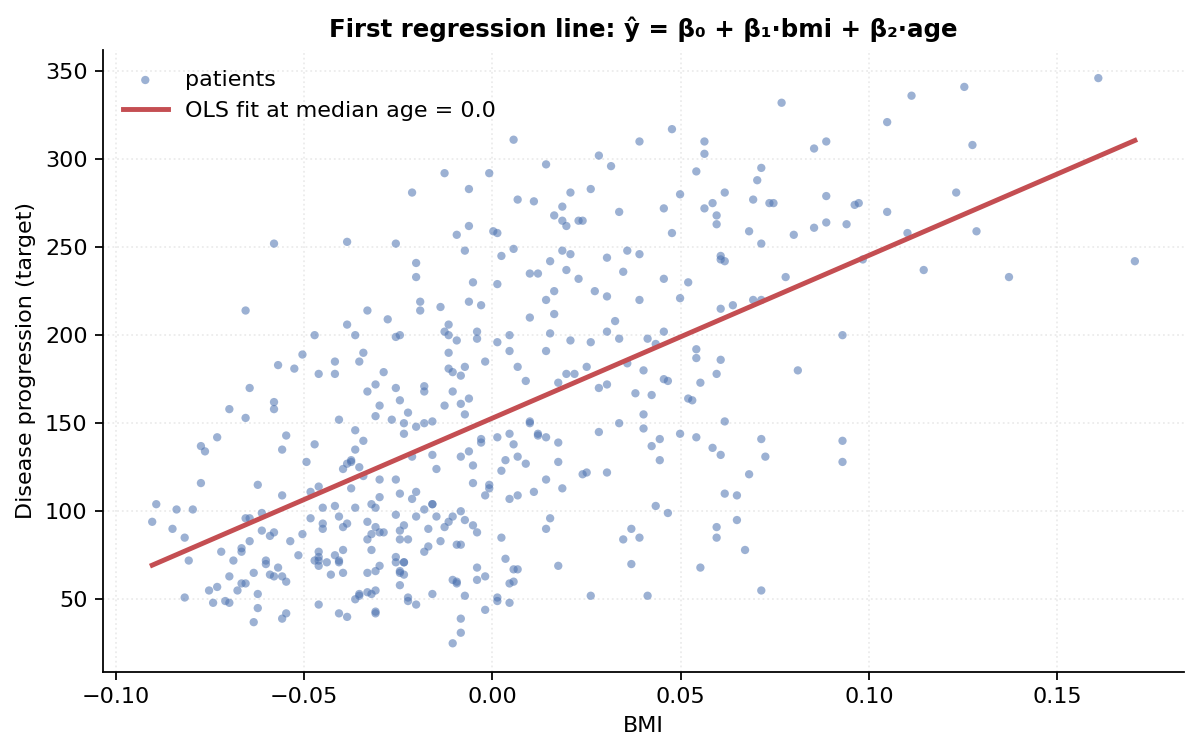

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_03_01_first_regression_line.png')

In [6]:

# ---------------------------------------------------------------------------------------
# Cell 3.1 — the first regression line on real data
# ---------------------------------------------------------------------------------------
from sklearn.linear_model import LinearRegression

X = df[["bmi", "age"]].values
y = df["target"].values

model = LinearRegression().fit(X, y)
print("Model : ŷ = %.4f + %.4f·bmi + %.4f·age" % (model.intercept_, model.coef_[0], model.coef_[1]))
print("R²   : %.4f" % model.score(X, y))
print("Reading: holding age fixed, +1 unit of bmi raises the predicted target by %.1f." % model.coef_[0])
print("        (the diabetes predictors arrive pre-standardised, so 'one unit' = one standard")
print("         deviation; the target is NOT scaled, so %.1f is in raw target units,"
      % model.coef_[0])
print("         i.e. about %.1f standard deviations of the target)." % (model.coef_[0] / df["target"].std(ddof=0)))

# scatter + fitted line along the bmi axis at the median age
age_med = np.median(df["age"].values)
grid = np.linspace(df["bmi"].min(), df["bmi"].max(), 200).reshape(-1, 1)
pred = model.predict(np.hstack([grid, np.full_like(grid, age_med)]))

fig, ax = plt.subplots(figsize=(7.6, 4.8))
ax.scatter(df["bmi"], df["target"], s=14, alpha=0.55, color="#4C72B0", edgecolor="none",
           label="patients")
ax.plot(grid.ravel(), pred, color="#C44E52", lw=2.2, label=f"OLS fit at median age = {age_med:.1f}")
ax.set_xlabel("BMI")
ax.set_ylabel("Disease progression (target)")
ax.set_title("First regression line: ŷ = β₀ + β₁·bmi + β₂·age")
ax.legend()
show(fig, "fig_03_01_first_regression_line")



**Reading the figure.** The cloud is a *wide* cloud: BMI pushes the target up, but for any BMI the
actual value still varies by ±50 units. That vertical spread is the **error term** $\varepsilon$
(the unexplainable part). Regression does **not** claim that a body lies on the line — it claims
the line is the best possible summary of the centre of the cloud. Two consequences you must be
ready to defend in the exam:

1. $R^2 = 0.35$ means the model explains ~35 % of the *variation* of the target on this data.
2. The relationship is **association, not causation** — the lecture says this explicitly in §3.2
   ("association does not prove causation"), and §7.5 shows the damage an omitted variable does.

**Read the coefficient carefully.** The diabetes predictors arrive pre-standardised (mean 0,
sd 1), so a coefficient of ≈ 925 means "**one standard deviation** of BMI is associated with ≈ 925
raw target units" — roughly 12 standard deviations of the target. That is a *large* association,
and it is exactly what a correlation of r = 0.59 predicts. Always ask: **in what units is my
predictor, and in what units is my coefficient?**



---

# 4. Lecture §1.2 — Regression vs classification (same features, two different targets)

The lecture's contrast table, reproduced exactly:

| Aspect | Regression | Classification |
|:--|:--|:--|
| Target | Continuous numerical value | Discrete class or category |
| Question | How much? / What value? | Which class? |
| Example | Predict a student's mark | Predict pass or fail |
| Algorithms | Linear regression, SVR, regression tree | Logistic regression, Naive Bayes, classification tree |
| Metrics | MAE, MSE, RMSE, R² | Accuracy, precision, recall, F1, AUC |

> "The type of target determines the task. A regression model can use categorical input features
> after suitable encoding, as long as the target being predicted is numerical."

The next cell proves that last sentence empirically: the **same** petal measurements are used for
a regression target and for a classification target, and the two fitted models look completely
different — one is a plane/straight line, the other partitions the space.


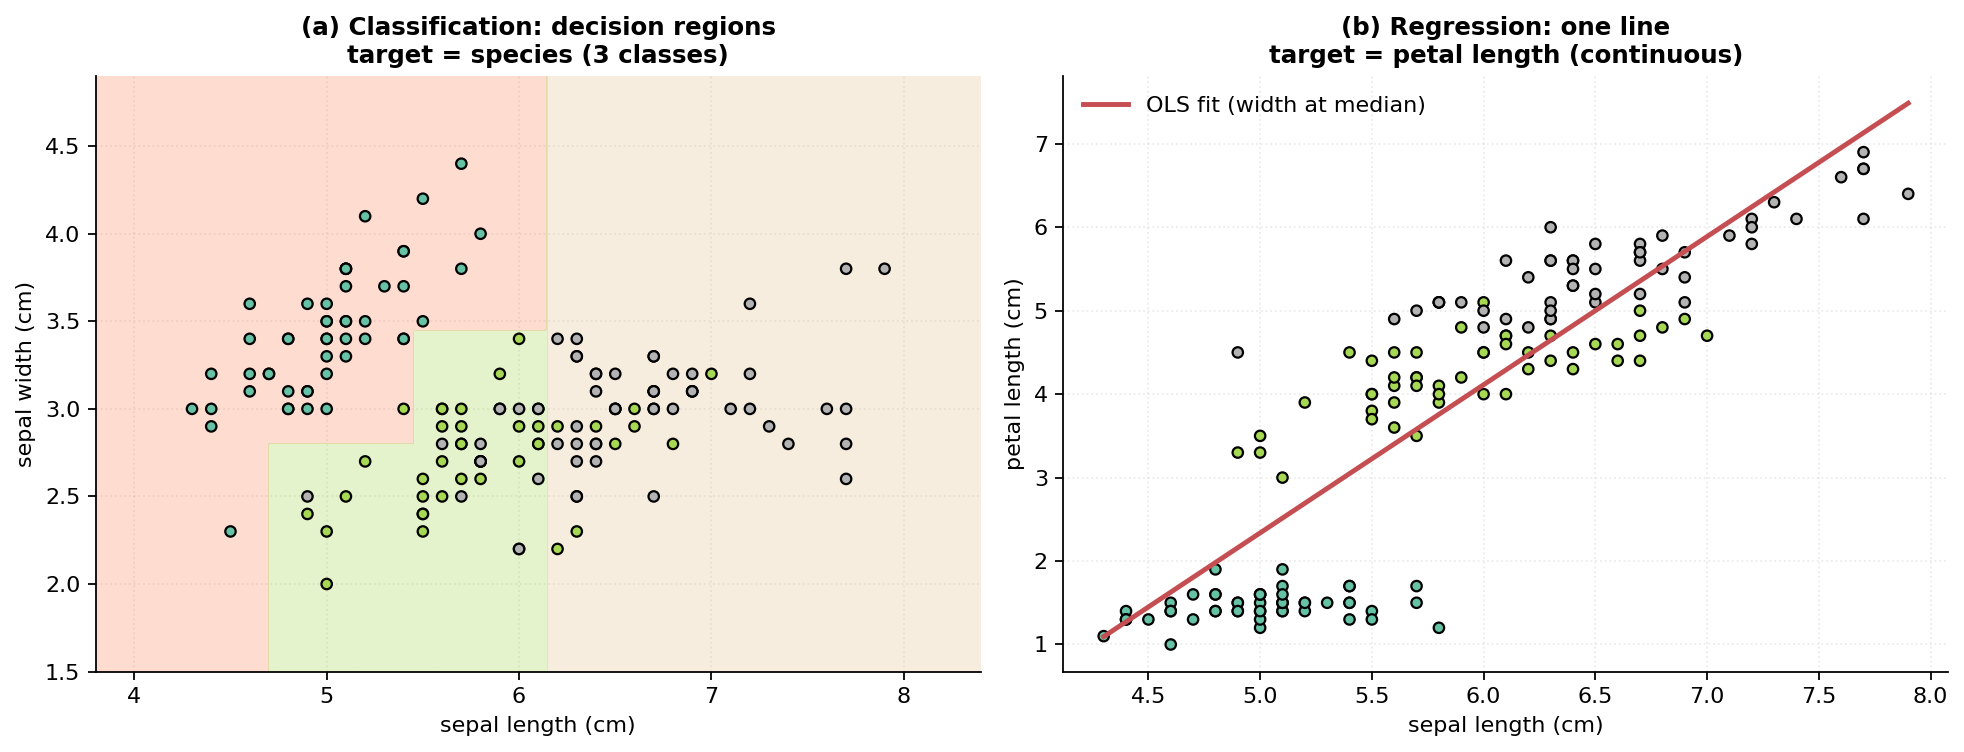

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_04_01_regression_vs_classification.png')

In [7]:

# ---------------------------------------------------------------------------------------
# Cell 4.1 — one dataset, two tasks (iris: sepal length/width)
# ---------------------------------------------------------------------------------------
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

iris = load_iris()
Xi = iris.data[:, :2]            # sepal length, sepal width
yi_class = iris.target           # 0=setosa, 1=versicolor, 2=virginica
yi_reg = iris.data[:, 2]         # petal length  -> a CONTINUOUS target on the same rows

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8))

# --- (a) classification: decision regions of a decision tree ---
clf = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(Xi, yi_class)
x0, x1 = Xi[:, 0], Xi[:, 1]
xx0, xx1 = np.meshgrid(np.linspace(x0.min() - .5, x0.max() + .5, 300),
                        np.linspace(x1.min() - .5, x1.max() + .5, 300))
Z = clf.predict(np.c_[xx0.ravel(), xx1.ravel()]).reshape(xx0.shape)
axes[0].contourf(xx0, xx1, Z, alpha=0.30, cmap="Set2", levels=np.arange(-0.5, 3.5))
axes[0].scatter(Xi[:, 0], Xi[:, 1], c=yi_class, cmap="Set2", edgecolor="k", s=22)
axes[0].set_title("(a) Classification: decision regions\ntarget = species (3 classes)")
axes[0].set_xlabel("sepal length (cm)"); axes[0].set_ylabel("sepal width (cm)")

# --- (b) regression: a straight line fitted to a continuous target on the same rows ---
reg = LinearRegression().fit(Xi, yi_reg)
xs = np.linspace(x0.min(), x0.max(), 200)
axes[1].scatter(Xi[:, 0], yi_reg, c=yi_class, cmap="Set2", edgecolor="k", s=22)
axes[1].plot(xs, reg.predict(np.c_[xs, np.full_like(xs, np.median(x1))]),
             color="#C44E52", lw=2.2, label="OLS fit (width at median)")
axes[1].set_title("(b) Regression: one line\ntarget = petal length (continuous)")
axes[1].set_xlabel("sepal length (cm)"); axes[1].set_ylabel("petal length (cm)")
axes[1].legend()

show(fig, "fig_04_01_regression_vs_classification")



**Reading the figure.**

* **(a) Classification** produces *regions*: the model answers *which species*, and the decision
  tree's regions are axis-parallel rectangles — exactly like the tree partitions of §11.
* **(b) Regression** produces *values*: a single smooth function; the colour of a point (its
  species) is irrelevant to the fit — the regression model never sees it. Only the target's
  *type* decides which task you are doing.

The colour-by-species in panel (b) is the proof of the lecture's sentence: a regression model may
use categorical information as an *input* after encoding, but the **target** must be numerical for
the task to be regression.

Note also the metric consequence: for (a) the natural metrics are accuracy/F1/AUC; for (b) they are
MAE/MSE/RMSE/R² (§17). Using a classification metric on a regression model (or vice versa) is a
classic exam and review trap.


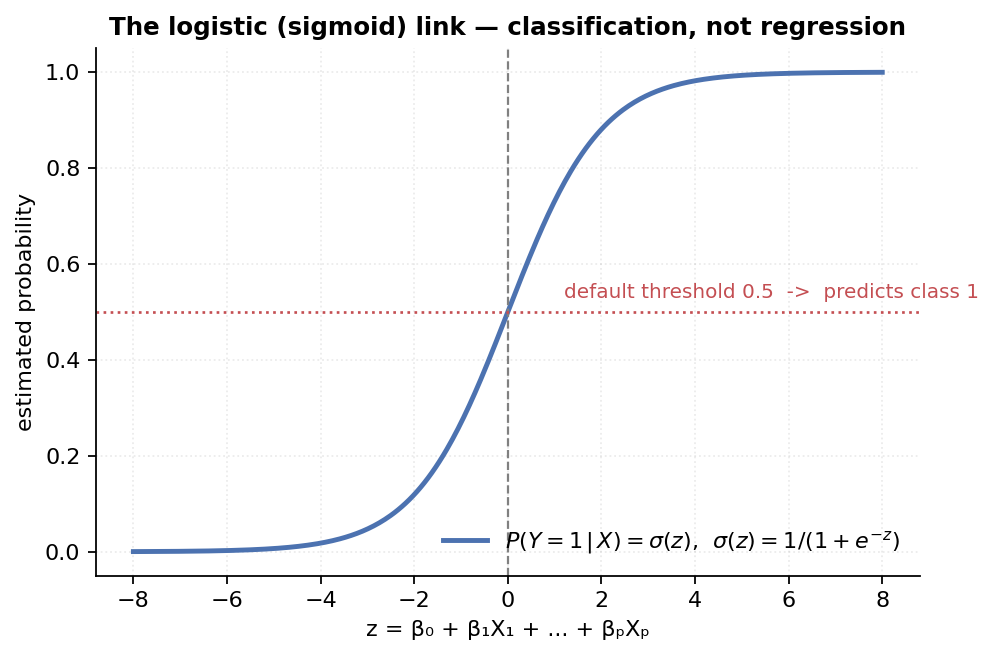

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_04_02_sigmoid.png')

In [8]:

# ---------------------------------------------------------------------------------------
# Cell 4.2 — the logistic function behind the classification side (lecture §4 preview)
# ---------------------------------------------------------------------------------------
z = np.linspace(-8, 8, 400)
sigmoid = 1.0 / (1.0 + np.exp(-z))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(z, sigmoid, color="#4C72B0", lw=2.2, label=r"$P(Y=1\,|\,X) = \sigma(z)$,  $\sigma(z)=1/(1+e^{-z})$")
ax.axvline(0, color="grey", ls="--", lw=1)
ax.axhline(0.5, color="#C44E52", ls=":", lw=1.2)
ax.text(1.2, 0.53, "default threshold 0.5  ->  predicts class 1", color="#C44E52", fontsize=9)
ax.set_xlabel("z = β₀ + β₁X₁ + ... + βₚXₚ")
ax.set_ylabel("estimated probability")
ax.set_title("The logistic (sigmoid) link — classification, not regression")
ax.legend(loc="lower right")
show(fig, "fig_04_02_sigmoid")



---

# 5. Lecture §2 — A basic regression example (and least squares by hand)

The lecture's opening example:

> "A university wants to estimate students' examination marks using weekly study hours."
> | Study hours (X) | 2 | 3 | 4 | 5 | 6 |
> | Final mark (Y) | 50 | 55 | 60 | 65 | 70 |
> "For illustration, suppose the learned model is: ŷ = 40 + 5X. For a student who studies 7 hours
> per week: ŷ = 40 + 5(7) = 75. The predicted mark is 75. This is an estimate based on the
> learned pattern, not a guarantee."

Two things to extract:

1. **Where 40 and 5 come from** — they are the *least-squares* estimates of $\beta_0$ and $\beta_1$
   for exactly this table. The handout says "suppose the learned model is"; the next cell shows
   that OLS *recovers* 40 and 5 exactly, because the five points lie on a perfect straight line.
2. **The correct epistemic status of the answer.** "75 is an estimate … not a guarantee. Other
   factors may also influence examination performance." A regression prediction is a conditional
   average, never a promise.


In [9]:

# ---------------------------------------------------------------------------------------
# Cell 5.1 — OLS from scratch: the normal equation, then verification against sklearn
# ---------------------------------------------------------------------------------------
study_hours = np.array([2., 3., 4., 5., 6.])
final_mark = np.array([50., 55., 60., 65., 70.])

def ols_normal_equation(X, y, fit_intercept=True):
    """Least squares via the normal equation  beta_hat = (X'X)^-1 X'y  (Gauss, 1800s)."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    if fit_intercept:
        X = np.hstack([np.ones((X.shape[0], 1)), X])
    beta = np.linalg.solve(X.T @ X, X.T @ y)     # solve, not inverse: numerically stabler
    return beta

beta = ols_normal_equation(study_hours, final_mark)
b0, b1 = beta
print("Normal-equation solution :  ŷ = %.6f + %.6f·X" % (b0, b1))

sk = LinearRegression().fit(study_hours.reshape(-1, 1), final_mark)
check("lecture §2 coefficients vs sklearn", [b0, b1], [sk.intercept_, sk.coef_[0]])

print()
print("Hand arithmetic on the normal equation:")
Xm = np.column_stack([np.ones_like(study_hours), study_hours])
XtX = Xm.T @ Xm
Xty = Xm.T @ final_mark
print("   X'X =", XtX.astype(int).tolist(), "   X'y =", Xty.astype(int).tolist())
print("   beta = (X'X)^-1 X'y =", np.round(beta, 6).tolist())

print()
print("The lecture's own check:")
for h in (5, 7):
    print("   hours = %d  ->  ŷ = 40 + 5(%d) = %d   (model says %.1f)"
          % (h, h, 40 + 5 * h, b0 + b1 * h))


Normal-equation solution :  ŷ = 40.000000 + 5.000000·X
[OK  ] lecture §2 coefficients vs sklearn: computed = [40.0, 5.0] | expected = [40.0, 5.0]

Hand arithmetic on the normal equation:
   X'X = [[5, 20], [20, 90]]    X'y = [300, 1250]
   beta = (X'X)^-1 X'y = [40.0, 5.0]

The lecture's own check:
   hours = 5  ->  ŷ = 40 + 5(5) = 65   (model says 65.0)
   hours = 7  ->  ŷ = 40 + 5(7) = 75   (model says 75.0)


In [10]:

# ---------------------------------------------------------------------------------------
# Cell 5.2 — the same fit seen as: residual table + how OLS spends its error budget
# ---------------------------------------------------------------------------------------
pred = b0 + b1 * study_hours
resid = final_mark - pred

print("Residuals e_i = y_i - ŷ_i")
print(pd.DataFrame({
    "hours X": study_hours,
    "mark y": final_mark,
    "prediction ŷ": pred,
    "residual e": resid,
    "squared e²": resid ** 2,
}).to_string(index=False))
print()
print("Σe = %.10f   (the normal equations force the residuals to sum to zero)" % resid.sum())
print("Σ X·e = %.10f   (and to be orthogonal to every predictor)" % (study_hours * resid).sum())
print("SSE = %.6f  ->  RMSE = %.6f  ->  R² = %.6f"
      % (np.sum(resid ** 2), np.sqrt(np.mean(resid ** 2)),
         1 - np.sum(resid ** 2) / np.sum((final_mark - final_mark.mean()) ** 2)))
print()
print("Perfect fit here (R² = 1) because the five points lie exactly on a line.")
print("In practice R² < 1 — see the diabetes fit in §3 and the model zoo in §14.")


Residuals e_i = y_i - ŷ_i
 hours X  mark y  prediction ŷ  residual e  squared e²
     2.0    50.0          50.0         0.0         0.0
     3.0    55.0          55.0         0.0         0.0
     4.0    60.0          60.0         0.0         0.0
     5.0    65.0          65.0         0.0         0.0
     6.0    70.0          70.0         0.0         0.0

Σe = 0.0000000000   (the normal equations force the residuals to sum to zero)
Σ X·e = 0.0000000000   (and to be orthogonal to every predictor)
SSE = 0.000000  ->  RMSE = 0.000000  ->  R² = 1.000000

Perfect fit here (R² = 1) because the five points lie exactly on a line.
In practice R² < 1 — see the diabetes fit in §3 and the model zoo in §14.



**Two OLS facts worth memorising (both visible in the output above):**

1. $\sum_i e_i = 0$ and $\sum_i x_i e_i = 0$. They are the *normal equations*: with two
   parameters the fitted line is forced through the centroid $(\bar x, \bar y)$. A quick visual
   proof: the residual line crosses zero exactly where the data's mean sits.
2. A fitted OLS line always passes through $(\bar x,\bar y)$. If a line you computed does not, you
   made an arithmetic error.

Also note the honesty of the handout's last sentence: R² = 1 here is an artefact of a perfectly
synthetic table with **zero** noise, not evidence that study hours explain exam marks.


Gradient descent solution:  ŷ = 40.000000 + 5.000000·X
[OK  ] gradient descent == normal equation: computed = [40.0, 5.0] | expected = [40.0, 5.0]


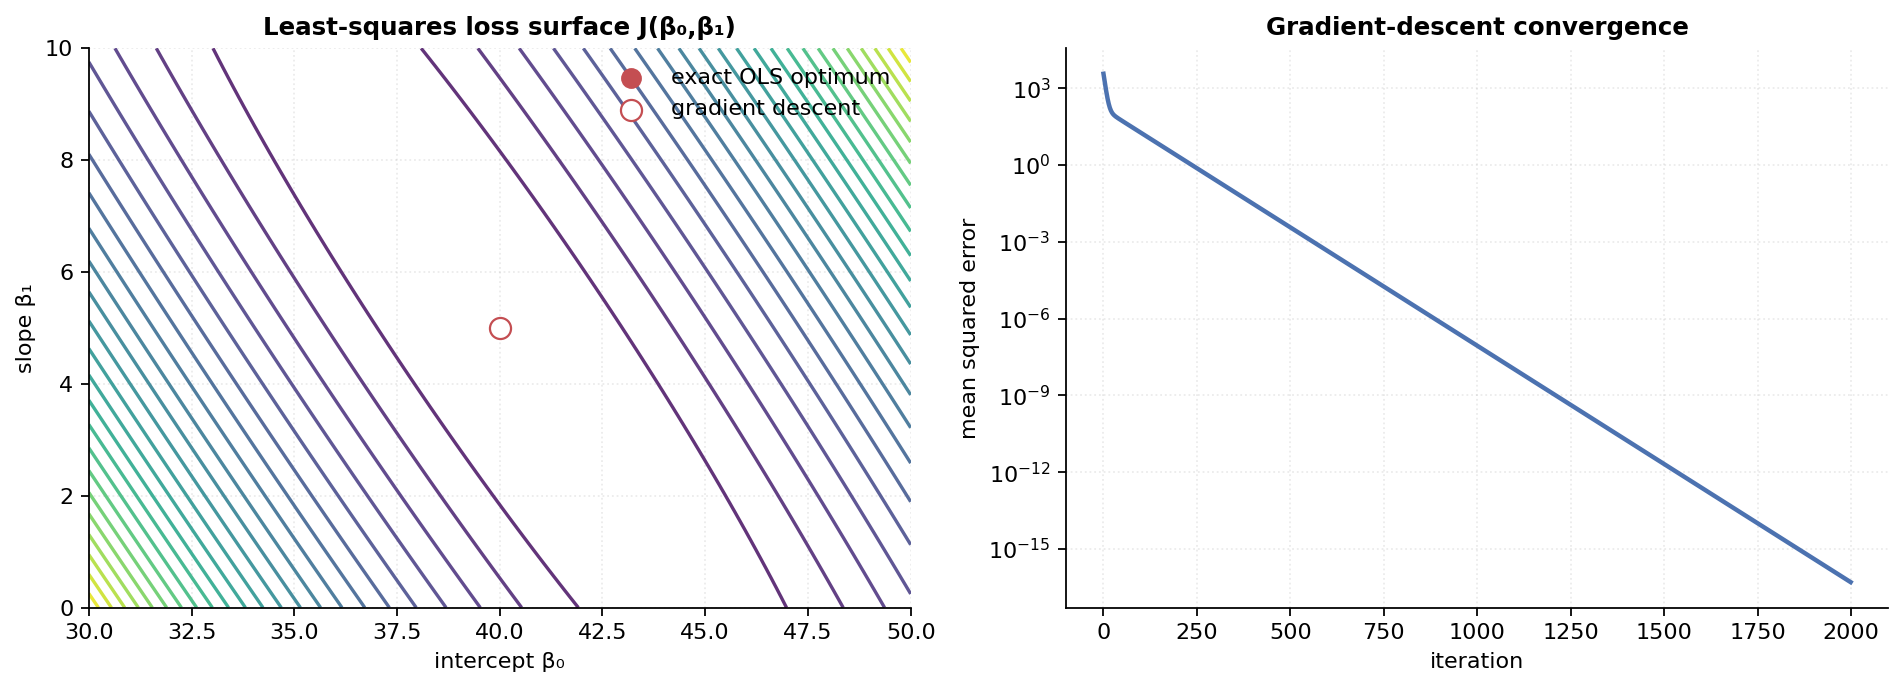

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_05_01_least_squares_surface.png')

In [11]:

# ---------------------------------------------------------------------------------------
# Cell 5.3 — gradient descent: the same answer, found iteratively (and what the loss surface looks like)
# ---------------------------------------------------------------------------------------
def gradient_descent_ols(X, y, lr=0.05, n_iter=2000):
    X = np.asarray(X, float); y = np.asarray(y, float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    b = np.zeros(X.shape[1] + 1)     # [intercept, slope]
    Xa = np.hstack([np.ones((X.shape[0], 1)), X])
    history = []
    for _ in range(n_iter):
        err = y - Xa @ b
        grad = -2 * Xa.T @ err / X.size
        b = b - lr * grad
        history.append(np.mean(err ** 2))
    return b, history

gd_beta, gd_hist = gradient_descent_ols(study_hours, final_mark)
print("Gradient descent solution:  ŷ = %.6f + %.6f·X" % tuple(gd_beta))
check("gradient descent == normal equation", gd_beta, beta, tol=1e-4)

# the loss surface J(b0,b1) = mean (y - b0 - b1 x)^2
b0_grid = np.linspace(30, 50, 160)
b1_grid = np.linspace(0, 10, 160)
B0, B1 = np.meshgrid(b0_grid, b1_grid)
J = np.array([[np.mean((final_mark - (b0 + b1 * study_hours)) ** 2) for b1 in b1_grid]
               for b0 in b0_grid])

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4))
axes[0].contour(B0, B1, J, levels=30, cmap="viridis", alpha=0.85)
axes[0].scatter(b0, b1, c="#C44E52", s=70, zorder=5, label="exact OLS optimum")
axes[0].scatter(gd_beta[0], gd_beta[1], c="white", edgecolor="#C44E52", s=90, zorder=6, label="gradient descent")
axes[0].set_xlabel("intercept β₀"); axes[0].set_ylabel("slope β₁")
axes[0].set_title("Least-squares loss surface J(β₀,β₁)"); axes[0].legend()

axes[1].plot(gd_hist, color="#4C72B0", lw=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("mean squared error")
axes[1].set_title("Gradient-descent convergence")
show(fig, "fig_05_01_least_squares_surface")



**Reading the figure.** *Left:* the SSE surface is a smooth bowl in $(\beta_0,\beta_1)$; the red dot
is the unique global minimum, and the white dot (gradient descent) lands on top of it. The bowl is
convex because the model is linear in its parameters — this is the mathematical reason OLS has a
unique optimum and why "gradient descent" and "the normal equation" can never disagree here.

*Right:* the loss falls as $1/k$ on a log scale — the classic convex-convergence signature.

**Exam transfer:** if a question asks you to *derive* the least-squares coefficients, write
$\frac{\partial}{\partial\beta_0}\sum(y_i-\beta_0-\beta_1x_i)^2=0$ and
$\frac{\partial}{\partial\beta_1}\sum(y_i-\beta_0-\beta_1x_i)^2=0$, solve the two equations, and
only then plug the data in. The result is $\hat\beta_1 = \frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2}$
and $\hat\beta_0 = \bar y-\hat\beta_1\bar x$. We verify that closed form numerically below.


In [12]:

# ---------------------------------------------------------------------------------------
# Cell 5.4 — the closed-form OLS coefficient (the formula you must be able to write from memory)
# ---------------------------------------------------------------------------------------
xbar, ybar = study_hours.mean(), final_mark.mean()
sxy = ((study_hours - xbar) * (final_mark - ybar)).sum()
sxx = ((study_hours - xbar) ** 2).sum()
b1_formula = sxy / sxx
b0_formula = ybar - b1_formula * xbar

print("beta1_hat = sum((x-xbar)(y-ybar)) / sum((x-xbar)^2) = %.6f / %.6f = %.6f" % (sxy, sxx, b1_formula))
print("beta0_hat = ybar - beta1_hat * xbar                  = %.1f - %.6f*%.1f = %.6f"
      % (ybar, b1_formula, xbar, b0_formula))
check("closed form == matrix form", [b0_formula, b1_formula], beta)


beta1_hat = sum((x-xbar)(y-ybar)) / sum((x-xbar)^2) = 50.000000 / 10.000000 = 5.000000
beta0_hat = ybar - beta1_hat * xbar                  = 60.0 - 5.000000*4.0 = 40.000000
[OK  ] closed form == matrix form: computed = [40.0, 5.0] | expected = [40.0, 5.0]


True


---

# 6. Lecture §3.1 — Simple linear regression

$$\hat y = \beta_0 + \beta_1 X$$

* $\beta_0$ — **intercept**: the predicted target when $X = 0$;
* $\beta_1$ — **slope**: the expected change in the predicted target for a one-unit increase in $X$.

The lecture's second worked example (house size and price):

| Size (sq ft) | 1,000 | 1,500 | 2,000 | 2,500 |
| Price ($1,000s) | 200 | 250 | 300 | 350 |

"Assume the fitted equation is: ŷ = 100 + 0.10X. For a 2,200-square-foot house:
ŷ = 100 + 0.10(2,200) = 320. The predicted price is $320,000. The slope 0.10 means each additional
square foot is associated with an increase of 0.10 thousand dollars ($100) in predicted price."

**Advantages:** simple, fast, relatively easy to interpret.
**Limitations:** cannot represent a curved relationship unless features are transformed; can be
affected by outliers and violations of model assumptions.


Fitted model: ŷ = 100.0000 + 0.100000·X   (price in $1,000s)
[OK  ] lecture §3.1 house model: computed = [100.0, 0.1] | expected = [100.0, 0.1]

Prediction for a 2,200 sq ft house:
   ŷ = 100 + 0.10(2,200) = 320.0 thousand dollars  ->  $320,000
   model says: 320.0 thousand dollars

Interpretation, made operational:
   +100 sq ft  ->  price change = 0.100 x 100 = 10.0 thousand dollars
   +500 sq ft  ->  price change = 0.100 x 500 = 50.0 thousand dollars
   a 1,500 sq ft house is predicted at 250.0 ($250,000)


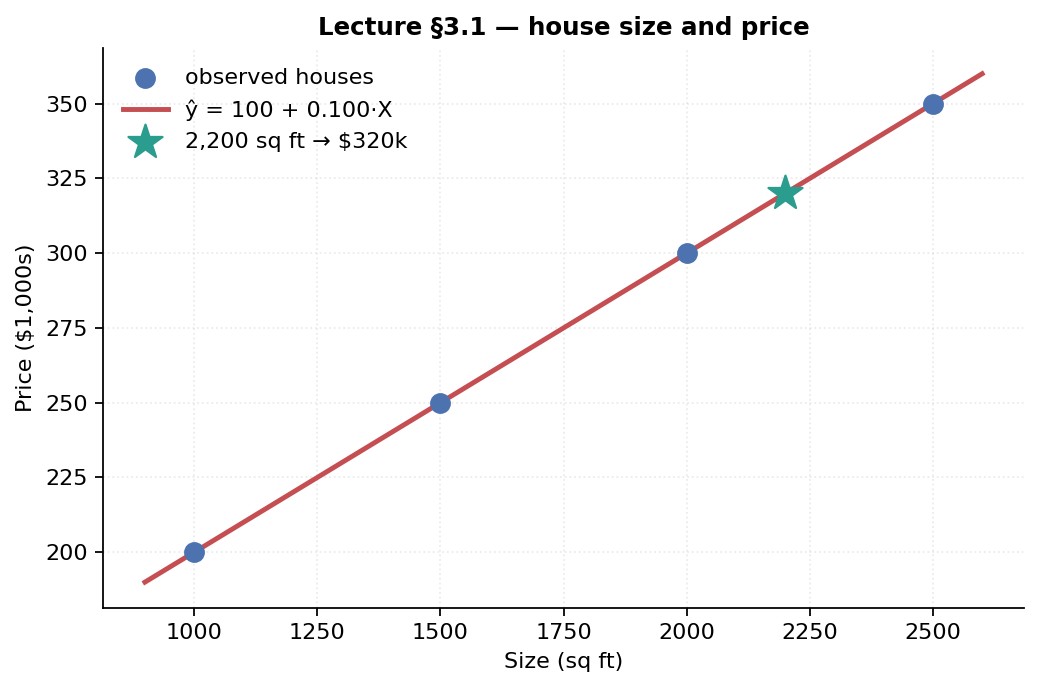

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_06_01_house_size_price.png')

In [13]:

# ---------------------------------------------------------------------------------------
# Cell 6.1 — the house-price example, verified, with the interpretation made operational
# ---------------------------------------------------------------------------------------
size_sqft = np.array([1000., 1500., 2000., 2500.])
price_k = np.array([200., 250., 300., 350.])          # price in thousands of dollars

b = ols_normal_equation(size_sqft, price_k)
print("Fitted model: ŷ = %.4f + %.6f·X   (price in $1,000s)" % (b[0], b[1]))
check("lecture §3.1 house model", b, [100.0, 0.10], tol=1e-9)

print()
print("Prediction for a 2,200 sq ft house:")
pred_2200 = b[0] + b[1] * 2200
print("   ŷ = 100 + 0.10(2,200) = %.1f thousand dollars  ->  $%s"
      % (pred_2200, f"{pred_2200 * 1000:,.0f}"))
print("   model says: %.1f thousand dollars" % pred_2200)

print()
print("Interpretation, made operational:")
print("   +100 sq ft  ->  price change = %.3f x 100 = %.1f thousand dollars" % (b[1], b[1] * 100))
print("   +500 sq ft  ->  price change = %.3f x 500 = %.1f thousand dollars" % (b[1], b[1] * 500))
print("   a 1,500 sq ft house is predicted at %.1f ($%s)"
      % (b[0] + b[1] * 1500, f"{(b[0]+b[1]*1500)*1000:,.0f}"))

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(size_sqft, price_k, s=70, color="#4C72B0", zorder=3, label="observed houses")
xs = np.linspace(900, 2600, 100)
ax.plot(xs, b[0] + b[1] * xs, color="#C44E52", lw=2.2, label="ŷ = %.0f + %.3f·X" % (b[0], b[1]))
ax.scatter([2200], [b[0] + b[1] * 2200], marker="*", s=260, color="#2A9D8F", zorder=4,
           label="2,200 sq ft → $%.0fk" % (b[0] + b[1] * 2200))
ax.set_xlabel("Size (sq ft)"); ax.set_ylabel("Price ($1,000s)")
ax.set_title("Lecture §3.1 — house size and price")
ax.legend()
show(fig, "fig_06_01_house_size_price")



**Reading the figure.** The four houses lie exactly on the line, so the residual variance is zero
and the model is again "perfect" — an artefact of an illustrative table. The star marks the
lecture's own query (2,200 sq ft → $320,000).

**Interpretation discipline (exam wording).** Say *"each additional square foot is **associated
with** an increase of 0.10 thousand dollars in the predicted price"*, not *"each square foot
causes…"*. The lecture itself uses the word *associated*; the causal reading is not available
from this data, and §6.3 (omitted-variable bias) shows concretely why.

Also note the unit trap: the slope is **$0.10 thousand = $100 per square foot**, i.e. **$100,000
per 1,000 sq ft**. Mixing "thousands of dollars" with "dollars" is the single most common unit
error in this kind of question.


In [14]:

# ---------------------------------------------------------------------------------------
# Cell 6.2 — three properties of the OLS line that you can always check (and one trap)
# ---------------------------------------------------------------------------------------
# (i) the fitted line passes through (xbar, ybar)
fitted_at_mean = b[0] + b[1] * size_sqft.mean()
check("OLS line passes through (x̄, ȳ)", fitted_at_mean, price_k.mean())

# (ii) residuals sum to zero
check("sum of residuals = 0", (price_k - (b[0] + b[1] * size_sqft)).sum(), 0.0, tol=1e-9)

# (iii) the slope equals cov/var  (the OLS "beta = r * sy/sx" identity)
r_xy = pearson_r(size_sqft, price_k)
b1_identity = r_xy * std(price_k) / std(size_sqft)
check("β1 = r·(s_y/s_x)", b1_identity, b[1])

# (iv) TRAP: the intercept is not "the mean of y" unless x̄ = 0
print()
print("TRAP CHECK")
print("   mean of price      = %.2f   <- NOT the intercept" % price_k.mean())
print("   intercept β0       = %.2f   <- prediction at X = 0 sq ft" % b[0])
print("   a house of size 0 does not exist, so β0 has no practical meaning here;")
print("   it is only a mathematical anchor that keeps the line in place.")
print("   => in a multiple regression (MPR) the intercept is the prediction when ALL")
print("      predictors are zero, which is why it is usually not interpretable.")


[OK  ] OLS line passes through (x̄, ȳ): computed = 275.0 | expected = 275.0
[OK  ] sum of residuals = 0: computed = 0.0 | expected = 0.0
[OK  ] β1 = r·(s_y/s_x): computed = 0.1 | expected = 0.1

TRAP CHECK
   mean of price      = 275.00   <- NOT the intercept
   intercept β0       = 100.00   <- prediction at X = 0 sq ft
   a house of size 0 does not exist, so β0 has no practical meaning here;
   it is only a mathematical anchor that keeps the line in place.
   => in a multiple regression (MPR) the intercept is the prediction when ALL
      predictors are zero, which is why it is usually not interpretable.



---

# 7. Lecture §3.1.1 — The six assumptions of linear regression, each one made to fail

The handout lists six assumptions and then says:

> "Use residual diagnostics rather than relying only on the model's R² value. A residual is the
> difference between an observed target and the model prediction: eᵢ = yᵢ − ŷᵢ."
> * residuals-versus-fitted plot → curvature (nonlinearity) or a funnel (heteroscedasticity);
> * Q–Q plot of residuals → normality;
> * residuals in observation or time order → dependence / autocorrelation;
> * correlation matrix and VIF → relationships among predictors.

> "**Important note:** the assumptions have different purposes. Violations of error independence,
> zero conditional mean, or constant error variance can affect coefficient estimation or statistical
> inference in different ways. Normality is mainly needed for exact classical small-sample
> inference."

This section makes each assumption **fail visibly** and measures the damage. That is the
difference between memorising a list and being able to answer "what happens if…?".


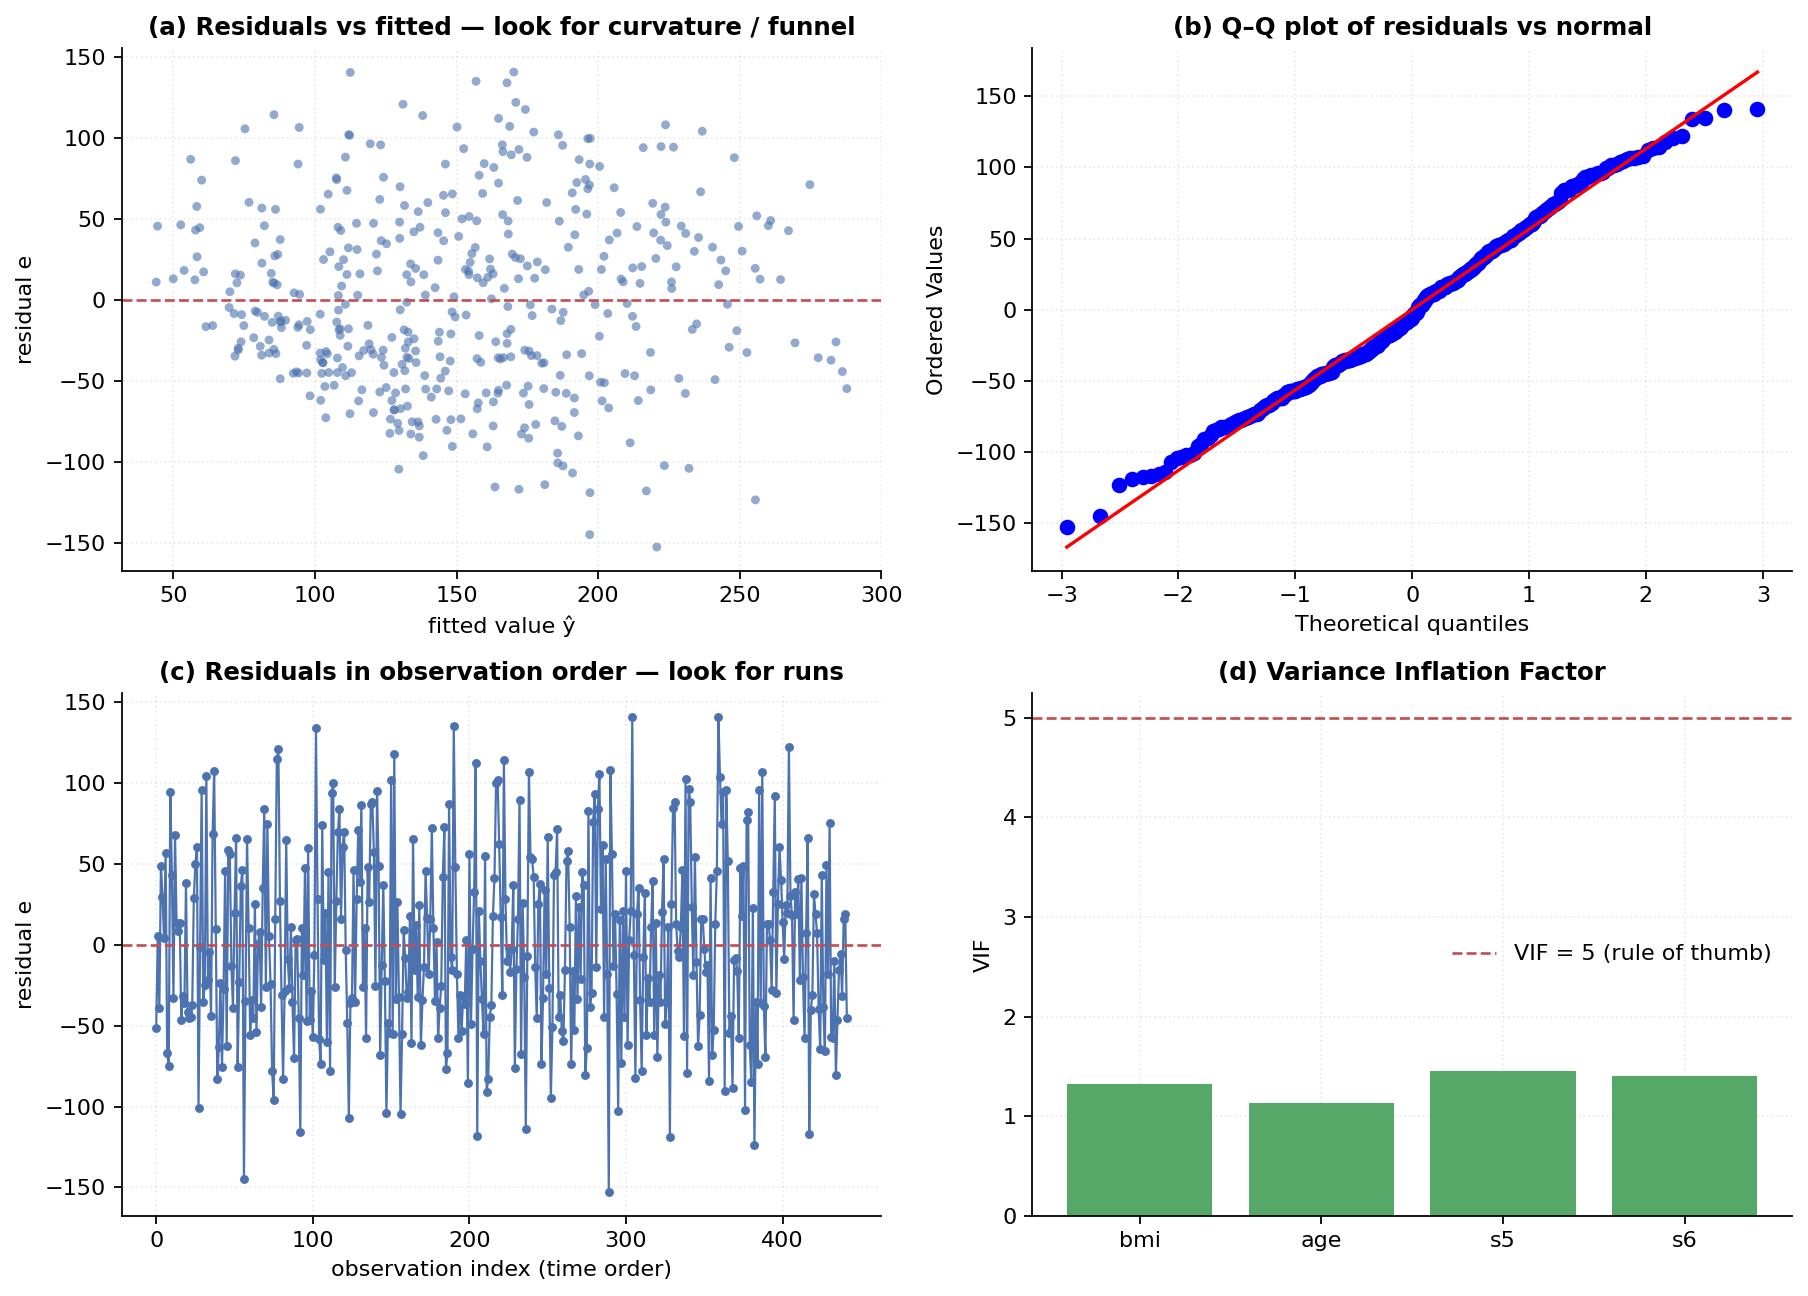

R² (in-sample)     : 0.4621
Durbin–Watson      : 1.9073   (≈2 means independent errors)
Shapiro–Wilk (normality of residuals): W = 0.9906, p = 0.006265
VIF per predictor  : {'bmi': 1.32, 'age': 1.13, 's5': 1.45, 's6': 1.4}

Reading of this particular model:
  (a) residuals vs fitted: no funnel, no visible curve -> homoscedasticity and
      linearity look acceptable here (but see the deliberate failures below);
  (b) Q-Q: the points follow the reference line closely, yet the Shapiro-Wilk
      p-value is 0.00626 -> with n = 442 the test has real power and rejects exact
      normality. Reading: residuals are close to normal but not exactly so;
      OLS coefficients are unaffected, exact small-sample t/F intervals are approximate;
  (c) residuals in observation order: no long runs -> no obvious autocorrelation;
  (d) all VIFs are below 5 -> no severe multicollinearity in this model.

Everything below breaks these checks deliberately, one at a time.


In [15]:

# ---------------------------------------------------------------------------------------
# Cell 7.1 — a 2x2 diagnostic panel on the diabetes model (the four plots the handout asks for)
# ---------------------------------------------------------------------------------------
from scipy import stats as sps

X_diab = df[["bmi", "age", "s5", "s6"]].values
y_diab = df["target"].values
m_diab = LinearRegression().fit(X_diab, y_diab)
yhat = m_diab.predict(X_diab)
resid = y_diab - yhat

def durbin_watson(e):
    """DW = sum (e_t - e_{t-1})^2 / sum e_t^2 ; ~2 => independent errors."""
    e = np.asarray(e, float)
    return np.sum(np.diff(e) ** 2) / np.sum(e ** 2)

def vif_table(X):
    """Variance Inflation Factor per column: VIF_j = 1/(1 - R^2_j)."""
    X = np.asarray(X, float)
    out = {}
    for j in range(X.shape[1]):
        others = np.delete(X, j, axis=1)
        r2 = LinearRegression().fit(others, X[:, j]).score(others, X[:, j])
        out[j] = np.inf if r2 >= 1 else 1.0 / (1.0 - r2)
    return out

fig, axes = plt.subplots(2, 2, figsize=(11.4, 8.2))

ax = axes[0, 0]
ax.scatter(yhat, resid, s=16, alpha=0.6, color="#4C72B0", edgecolor="none")
ax.axhline(0, color="#C44E52", ls="--", lw=1.2)
ax.set_xlabel("fitted value ŷ"); ax.set_ylabel("residual e")
ax.set_title("(a) Residuals vs fitted — look for curvature / funnel")

ax = axes[0, 1]
sps.probplot(resid, dist="norm", plot=ax)
ax.set_title("(b) Q–Q plot of residuals vs normal")

ax = axes[1, 0]
ax.plot(resid, color="#4C72B0", lw=1.0, marker="o", ms=3)
ax.axhline(0, color="#C44E52", ls="--", lw=1.2)
ax.set_xlabel("observation index (time order)"); ax.set_ylabel("residual e")
ax.set_title("(c) Residuals in observation order — look for runs")

ax = axes[1, 1]
vifs = vif_table(X_diab)
names = ["bmi", "age", "s5", "s6"]
ax.bar(names, [vifs[i] for i in range(4)], color="#55A868")
ax.axhline(5, color="#C44E52", ls="--", lw=1.2, label="VIF = 5 (rule of thumb)")
ax.set_ylabel("VIF"); ax.set_title("(d) Variance Inflation Factor")
ax.legend()

show(fig, "fig_07_01_diagnostics_panel")

sw_p = sps.shapiro(resid)[1]
print("R² (in-sample)     : %.4f" % m_diab.score(X_diab, y_diab))
print("Durbin–Watson      : %.4f   (≈2 means independent errors)" % durbin_watson(resid))
print("Shapiro–Wilk (normality of residuals): W = %.4f, p = %.4g" % sps.shapiro(resid))
print("VIF per predictor  :", {n: round(vifs[i], 2) for n, i in zip(names, range(4))})
print()
print("Reading of this particular model:")
print("  (a) residuals vs fitted: no funnel, no visible curve -> homoscedasticity and")
print("      linearity look acceptable here (but see the deliberate failures below);")
print("  (b) Q-Q: the points follow the reference line closely, yet the Shapiro-Wilk")
print("      p-value is %.3g -> with n = %d the test has real power and rejects exact" % (sw_p, len(resid)))
print("      normality. Reading: residuals are close to normal but not exactly so;")
print("      OLS coefficients are unaffected, exact small-sample t/F intervals are approximate;")
print("  (c) residuals in observation order: no long runs -> no obvious autocorrelation;")
print("  (d) all VIFs are below 5 -> no severe multicollinearity in this model.")
print()
print("Everything below breaks these checks deliberately, one at a time.")



**Reading the 2×2 panel.** This is *the* diagnostic figure to memorise for the exam:

* **(a) Residuals vs fitted** — a **U or ∩ shape** ⇒ missing nonlinearity (fix: add $X^2$ terms
  or transform); a **funnel** (spread growing with ŷ) ⇒ heteroscedasticity.
* **(b) Q–Q plot** — points hugging the reference line ⇒ residuals approximately normal;
  a visible S-shape ⇒ skewed/heavy tails.
* **(c) Residuals in order** — a wave or a long run of the same sign ⇒ dependence
  (autocorrelation), typical for time series.
* **(d) VIF** — VIF > 5 (or > 10) ⇒ multicollinearity; the coefficient for that variable becomes
  unstable and its *individual* meaning is lost.

Note the Durbin–Watson statistic: DW ≈ 2 ⇒ independent errors; DW < 2 ⇒ positive autocorrelation;
DW > 2 ⇒ negative autocorrelation. It is computed here by hand from the residuals.



### 7.2 Assumption 1 — Linearity **in parameters** (not in the raw predictors)

The handout is precise here, and it is a favourite exam distinction:

> "The expected target should be expressible as a linear combination of the model coefficients. A
> straight-line relationship between every raw predictor and the target is not required; transformed
> terms such as X² can be included, provided the model remains linear in its coefficients."


[OK  ] sklearn poly == manual normal equation: computed = [151.472178, 941.147355, 292.297188] | expected = [151.472178, 941.147355, 292.297188]
Linear model   R² = 0.3439   (β₁ = 949.435)
Quadratic model R² = 0.3441   (β₁ = 941.147, β₂ = 292.297)
The quadratic model is nonlinear in X but linear in (β₀,β₁,β₂) -> OLS still applies.


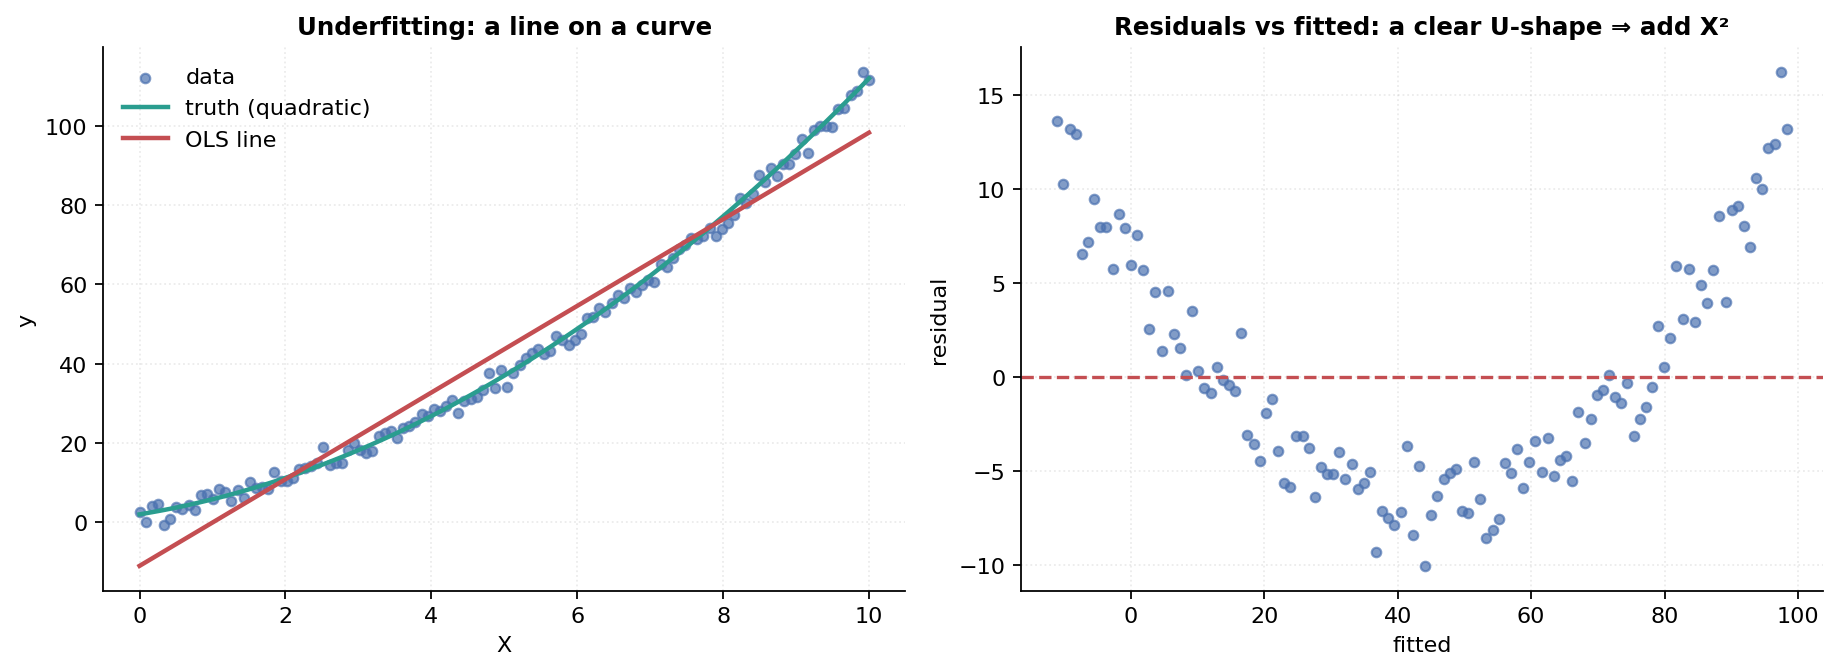

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_07_02_linearity_violation.png')

In [16]:

# ---------------------------------------------------------------------------------------
# Cell 7.2 — linearity in parameters: X^2 is allowed, and OLS on the transformed column
#             gives *exactly* the same coefficients as polynomial regression
# ---------------------------------------------------------------------------------------
bmi = df["bmi"].values
y = df["target"].values

lin = LinearRegression().fit(bmi.reshape(-1, 1), y)
quad = LinearRegression().fit(np.c_[bmi, bmi ** 2], y)          # sklearn's PolynomialFeatures idea
quad_manual = ols_normal_equation(np.c_[bmi, bmi ** 2], y)

check("sklearn poly == manual normal equation", quad_manual, np.r_[quad.intercept_, quad.coef_], tol=1e-9)
print("Linear model   R² = %.4f   (β₁ = %.3f)" % (lin.score(bmi.reshape(-1, 1), y), lin.coef_[0]))
print("Quadratic model R² = %.4f   (β₁ = %.3f, β₂ = %.3f)"
      % (quad.score(np.c_[bmi, bmi ** 2], y), quad.coef_[0], quad.coef_[1]))
print("The quadratic model is nonlinear in X but linear in (β₀,β₁,β₂) -> OLS still applies.")

# a curved relation the straight line cannot absorb
xx = np.linspace(0, 10, 120)
yy_true = 2 + 3 * xx + 0.8 * xx ** 2
yy_noisy = yy_true + np.random.default_rng(RANDOM_STATE).normal(0, 2.0, xx.size)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
axes[0].scatter(xx, yy_noisy, s=18, color="#4C72B0", alpha=0.7, label="data")
axes[0].plot(xx, yy_true, color="#2A9D8F", lw=2, label="truth (quadratic)")
g1 = LinearRegression().fit(xx.reshape(-1, 1), yy_noisy)
axes[0].plot(xx, g1.predict(xx.reshape(-1, 1)), color="#C44E52", lw=2, label="OLS line")
axes[0].legend(); axes[0].set_title("Underfitting: a line on a curve")
axes[0].set_xlabel("X"); axes[0].set_ylabel("y")

r_lin = yy_noisy - g1.predict(xx.reshape(-1, 1))
axes[1].scatter(g1.predict(xx.reshape(-1, 1)), r_lin, s=18, color="#4C72B0", alpha=0.7)
axes[1].axhline(0, color="#C44E52", ls="--")
axes[1].set_xlabel("fitted"); axes[1].set_ylabel("residual")
axes[1].set_title("Residuals vs fitted: a clear U-shape ⇒ add X²")
show(fig, "fig_07_02_linearity_violation")



**Reading the figure.** Left: the straight line systematically over-predicts in the middle and
under-predicts at both ends — the *signature of misspecification*, not of noise. Right: the
residual plot draws a visible **U** (or ∩). This is the exact picture the handout asks you to
recognise ("look for curvature (possible nonlinearity)").

**Fix:** add $X^2$ (or use a spline / log transform). Note that the model stays *linear in its
coefficients*, so OLS and all its inference machinery still apply.

**Important nuance the handout stresses:** the assumption is *linearity in parameters*, not
*linearity in every raw predictor*. A model $y = \beta_0 + \beta_1 X + \beta_2 X^2$ violates the
naive reading but satisfies the actual assumption.



### 7.3 Assumption 2 — Independence of errors (and what autocorrelation does)

> "The error for one observation should not be dependent on the error for another observation.
> This is particularly important when data are collected over time or from related groups."


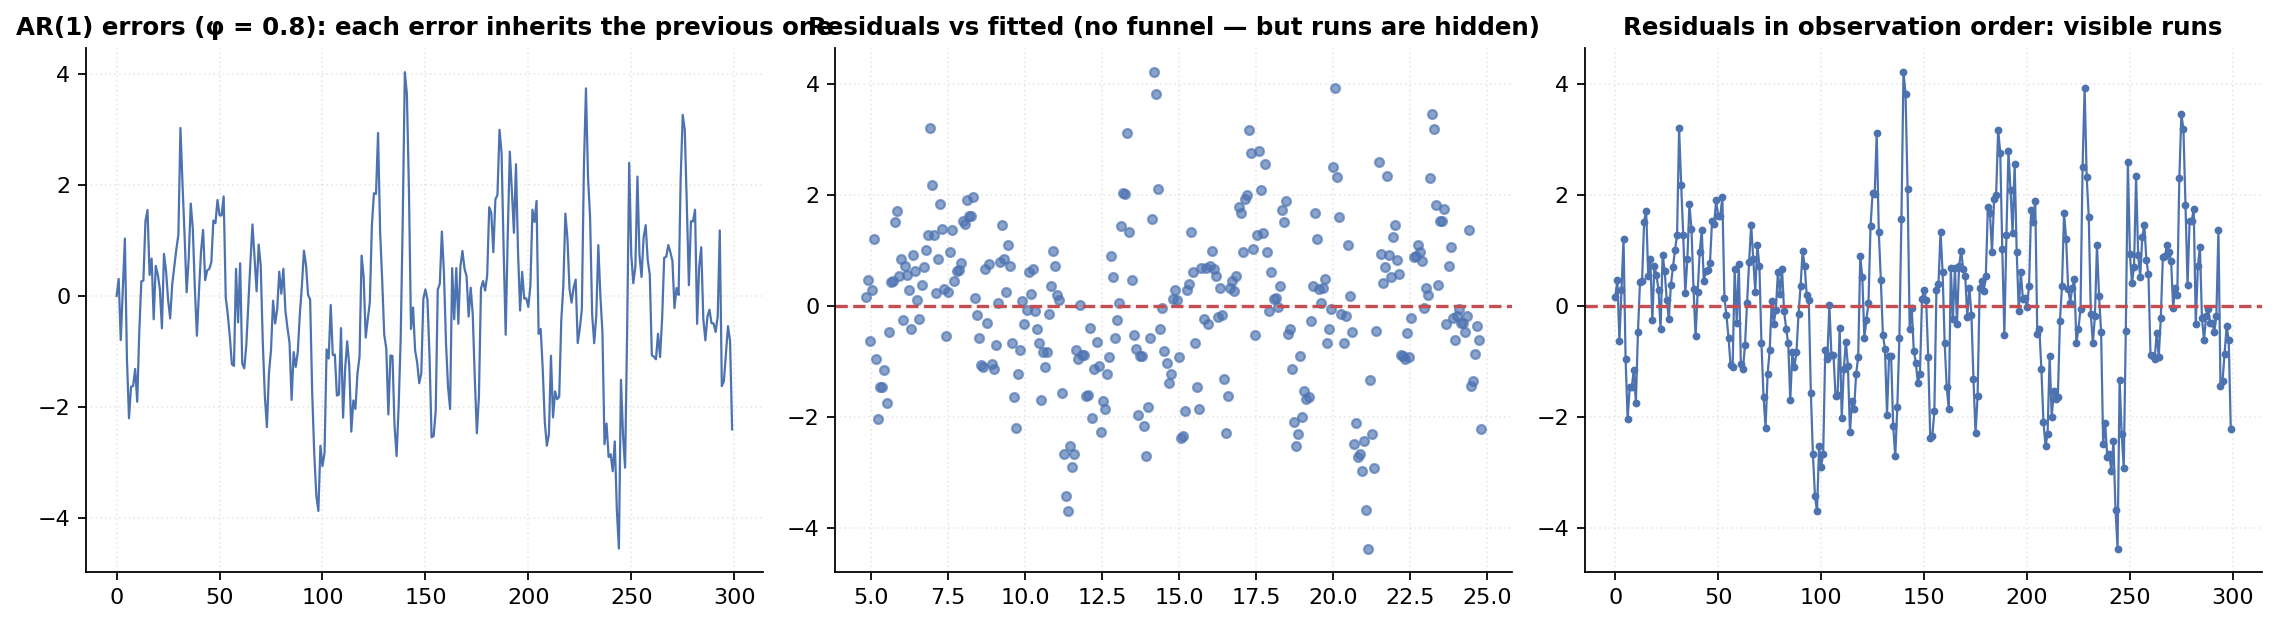

Estimated slope   : 1.9979   (true 2.0 — the POINT ESTIMATE is still fine)
Durbin–Watson     : 0.4706   (2 = independent;  < 2 = positive autocorrelation)
lag-1 residual autocorrelation: 0.7638  (should be ~0 under independence)

Damage: the coefficients are still unbiased, but the standard errors are wrong
(too small) -> t-tests and confidence intervals become over-confident.


In [17]:

# ---------------------------------------------------------------------------------------
# Cell 7.3 — AR(1) errors: independence violated, and the damage measured
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 300
x_time = np.linspace(0, 10, n)
phi = 0.8                                  # autocorrelation coefficient of the errors
e = np.zeros(n)
for t in range(1, n):
    e[t] = phi * e[t - 1] + rng.normal(0, 1.0)
y_ar = 5 + 2 * x_time + e

m_ar = LinearRegression().fit(x_time.reshape(-1, 1), y_ar)
res_ar = y_ar - m_ar.predict(x_time.reshape(-1, 1))

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.0))
axes[0].plot(e, color="#4C72B0", lw=1.0)
axes[0].set_title("AR(1) errors (φ = 0.8): each error inherits the previous one")
axes[1].scatter(m_ar.predict(x_time.reshape(-1, 1)), res_ar, s=16, color="#4C72B0", alpha=0.65)
axes[1].axhline(0, color="#C44E52", ls="--")
axes[1].set_title("Residuals vs fitted (no funnel — but runs are hidden)")
axes[2].plot(res_ar, color="#4C72B0", lw=1.0, marker="o", ms=2.5)
axes[2].axhline(0, color="#C44E52", ls="--")
axes[2].set_title("Residuals in observation order: visible runs")

show(fig, "fig_07_03_autocorrelation")

def durbin_watson(e):
    e = np.asarray(e, float)
    return np.sum(np.diff(e) ** 2) / np.sum(e ** 2)

dw = durbin_watson(res_ar)
print("Estimated slope   : %.4f   (true 2.0 — the POINT ESTIMATE is still fine)" % m_ar.coef_[0])
print("Durbin–Watson     : %.4f   (2 = independent;  < 2 = positive autocorrelation)" % dw)
print("lag-1 residual autocorrelation: %.4f  (should be ~0 under independence)"
      % np.corrcoef(res_ar[:-1], res_ar[1:])[0, 1])
print()
print("Damage: the coefficients are still unbiased, but the standard errors are wrong")
print("(too small) -> t-tests and confidence intervals become over-confident.")



**Reading the figure.** The residual-vs-fitted panel looks *fine* (no funnel, no curve) — the
violation only shows in the **time-order** panel, where the residuals come in runs of the same
sign. That is precisely why the handout insists on *four* diagnostics and not just R².

**What breaks and what does not** (this distinction is worth marks):

| | Point estimate $\hat\beta$ | Standard errors / CIs / p-values |
|:--|:--|:--|
| Independent errors violated | still unbiased | **wrong** (too small) → false "significance" |
| Zero conditional mean violated | **biased** | wrong |
| Constant variance violated | still unbiased | wrong (need robust/HAC SEs) |
| Normality violated | still unbiased | exact small-sample $t$/F inference unreliable |

**Remedy:** time-ordered splitting (§15), or Newey–West / HAC standard errors (implemented in
Cell 7.4) — the point estimate needs no change.


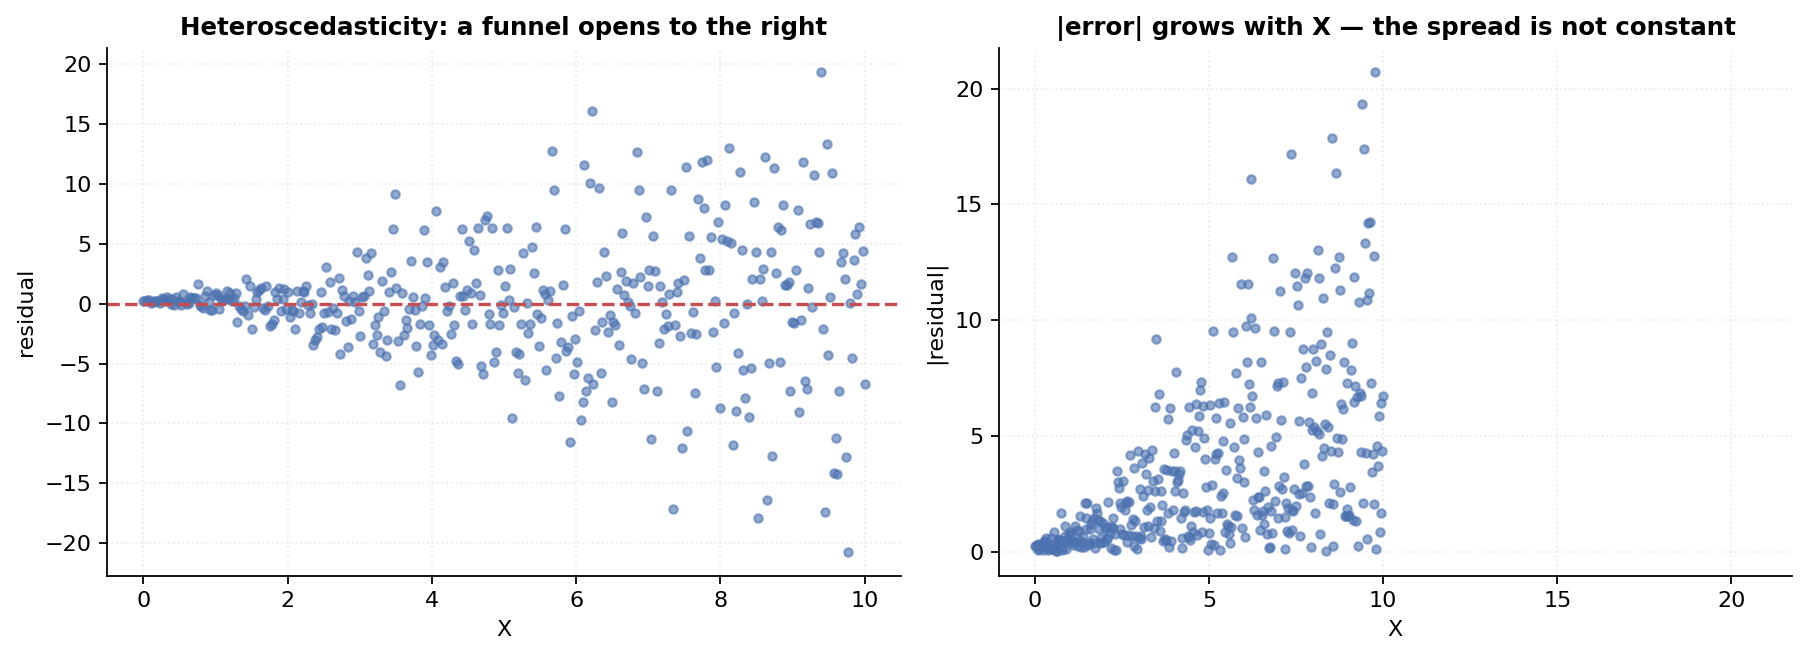

beta_hat (slope)      : 1.5659  (true 1.5 — unbiased)
naive  SE / t         : 0.0904  /  17.32
HAC    SE / t         : 0.0978  /  16.02

The naive standard error is too small, so the classical t-test overstates the evidence.
HAC widens the interval -> the honest one.


In [18]:

# ---------------------------------------------------------------------------------------
# Cell 7.4 — constant-variance assumption violated: naive vs Newey–West (HAC) standard errors
# ---------------------------------------------------------------------------------------
def ols_with_se(X, y, fit_intercept=True):
    X = np.asarray(X, float); y = np.asarray(y, float)
    if fit_intercept:
        X = np.hstack([np.ones((X.shape[0], 1)), X])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ (X.T @ y)
    resid = y - X @ beta
    n, k = X.shape
    # naive (homoscedastic) covariance
    sigma2 = (resid ** 2).sum() / (n - k)
    V_naive = sigma2 * XtX_inv
    # Newey–West sandwich with Bartlett kernel and lag L = floor(4*(n/100)^(2/9))
    L = int(np.floor(4 * (n / 100) ** (2.0 / 9.0)))
    S = np.zeros((k, k))
    for t in range(n):
        u = X[t] * resid[t]
        S += np.outer(u, u)
    for l in range(1, L + 1):
        w = 1.0 - l / (L + 1.0)
        for t in range(l, n):
            u = X[t] * resid[t]; v = X[t - l] * resid[t - l]
            S += w * (np.outer(u, v) + np.outer(v, u))
    V_hac = XtX_inv @ S @ XtX_inv
    se_naive = np.sqrt(np.diag(V_naive))
    se_hac = np.sqrt(np.diag(V_hac))
    return beta, se_naive, se_hac, resid

rng = np.random.default_rng(RANDOM_STATE)
n = 400
xx = np.linspace(0, 10, n)
het = np.abs(xx) * 0.9 * rng.normal(0, 1, n)        # variance grows with x  -> heteroscedastic
yy = 4 + 1.5 * xx + het

beta, se_naive, se_hac, r = ols_with_se(xx.reshape(-1, 1), yy)
t_naive = beta[1] / se_naive[1]
t_hac = beta[1] / se_hac[1]

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2))
axes[0].scatter(xx, r, s=14, alpha=0.6, color="#4C72B0")
axes[0].axhline(0, color="#C44E52", ls="--")
axes[0].set_xlabel("X"); axes[0].set_ylabel("residual")
axes[0].set_title("Heteroscedasticity: a funnel opens to the right")

axes[1].scatter(np.abs(r), np.full_like(r, 0), s=0)
axes[1].scatter(xx, np.abs(r), s=14, alpha=0.6, color="#4C72B0")
axes[1].set_xlabel("X"); axes[1].set_ylabel("|residual|")
axes[1].set_title("|error| grows with X — the spread is not constant")
show(fig, "fig_07_04_heteroscedasticity")

print("beta_hat (slope)      : %.4f  (true 1.5 — unbiased)" % beta[1])
print("naive  SE / t         : %.4f  /  %.2f" % (se_naive[1], t_naive))
print("HAC    SE / t         : %.4f  /  %.2f" % (se_hac[1], t_hac))
print()
print("The naive standard error is %s, so the classical t-test overstates the evidence."
      % ("too small" if se_naive[1] < se_hac[1] else "too large"))
print("HAC widens the interval -> the honest one.")



### 7.5 Assumption 3 — Zero conditional mean (exogeneity): the **omitted-variable bias** demo

> "The expected error should be zero for every combination of predictor values … Omitted important
> variables or predictors related to the errors can bias coefficient estimates."

This is the most consequential assumption in the whole list, because when it fails the
**coefficient itself is wrong** — not just the error bars. The following simulation reproduces it
exactly.


TRUE model:            y = 10 + 2·x + 5·z + ε
Model that omits z :   ŷ = 9.897 + 4.460·x      <-- slope is BIASED (too large)
Model including z  :   ŷ = 9.996 + 1.998·x + 4.999·z   <-- recovers the truth

Bias in the x-coefficient: 4.460 - 2.000 = +2.460  (it absorbed 5·cov(x,z)/var(x) = 2.462)

Interpretation: x is correlated with z, and z really affects y;
so a regression of y on x alone credits x with z's effect.


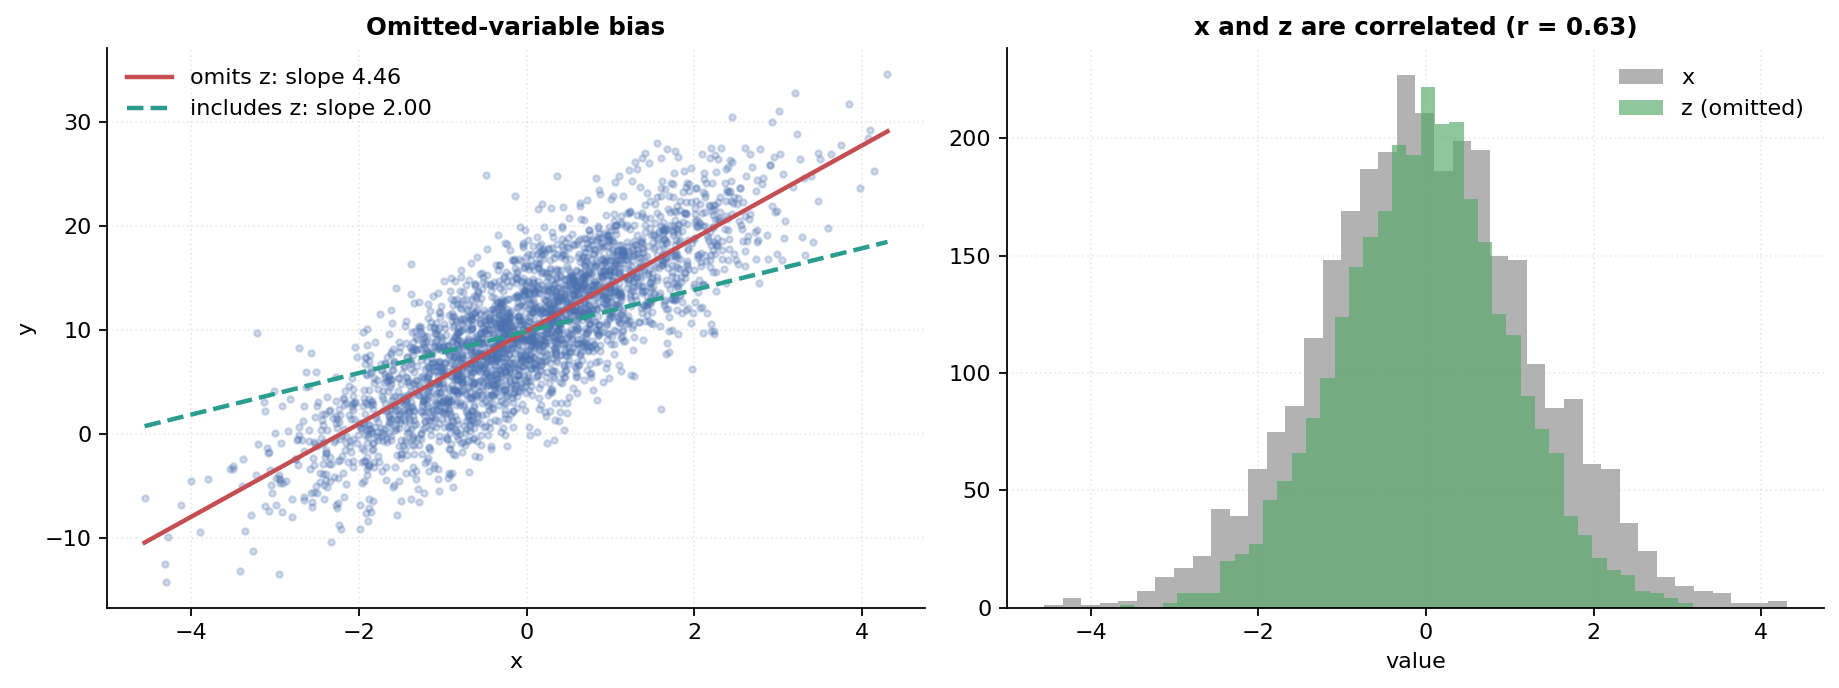

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_07_05_omitted_variable_bias.png')

In [19]:

# ---------------------------------------------------------------------------------------
# Cell 7.5 — omitted-variable bias: y = 10 + 2x + 5z + eps , but we only observe x
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 3000
z = rng.normal(0, 1, n)
x = 0.8 * z + rng.normal(0, 1, n)        # x is CORRELATED with the omitted variable z
eps = rng.normal(0, 1, n)
y = 10 + 2 * x + 5 * z + eps             # the truth

m_omit = LinearRegression().fit(x.reshape(-1, 1), y)      # model that omits z
m_full = LinearRegression().fit(np.c_[x, z], y)           # model with z included

print("TRUE model:            y = 10 + 2·x + 5·z + ε")
print("Model that omits z :   ŷ = %.3f + %.3f·x      <-- slope is %s"
      % (m_omit.intercept_, m_omit.coef_[0],
         "BIASED (too large)" if m_omit.coef_[0] > 2 else "ok"))
print("Model including z  :   ŷ = %.3f + %.3f·x + %.3f·z   <-- recovers the truth"
      % (m_full.intercept_, m_full.coef_[0], m_full.coef_[1]))
print()
print("Bias in the x-coefficient: %.3f - %.3f = %+.3f  (it absorbed 5·cov(x,z)/var(x) = %.3f)"
      % (m_omit.coef_[0], 2.0, m_omit.coef_[0] - 2.0,
         5 * np.cov(x, z, ddof=0)[0, 1] / np.var(x, ddof=0)))
print()
print("Interpretation: x is correlated with z, and z really affects y;")
print("so a regression of y on x alone credits x with z's effect.")

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4))
axes[0].scatter(x, y, s=8, alpha=0.25, color="#4C72B0")
xs = np.linspace(x.min(), x.max(), 100)
axes[0].plot(xs, m_omit.intercept_ + m_omit.coef_[0] * xs, color="#C44E52", lw=2,
             label="omits z: slope %.2f" % m_omit.coef_[0])
axes[0].plot(xs, m_full.intercept_ + m_full.coef_[0] * xs + m_full.coef_[1] * np.mean(z),
             color="#2A9D8F", lw=2, ls="--", label="includes z: slope %.2f" % m_full.coef_[0])
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].set_title("Omitted-variable bias"); axes[0].legend()

axes[1].hist(x, bins=40, color="#999999", alpha=0.75, label="x")
axes[1].hist(z, bins=40, color="#55A868", alpha=0.65, label="z (omitted)")
axes[1].set_xlabel("value"); axes[1].set_title("x and z are correlated (r = %.2f)"
                                                  % pearson_r(x, z))
axes[1].legend()
show(fig, "fig_07_05_omitted_variable_bias")



**Reading the figure.** *Left:* the red line (model that omits $z$) is steeper than the truth,
because $x$ acts as a **proxy** for the omitted $z$. *Right:* $x$ and $z$ are correlated, which is
the necessary condition for the bias.

**The exact bias formula** (worth memorising, and worth the marks):

$$\text{Bias}(\hat\beta_1) \;=\; \beta_2 \cdot \frac{\operatorname{Cov}(x_1,x_2)}{\operatorname{Var}(x_1)}$$

With $\beta_2 = 5$ and $\operatorname{Cov}(x,z)/\operatorname{Var}(x) \approx 0.8$, the bias is
$5 \times 0.8 = 4$ — so the estimated slope is $2 + 4 = 6$ instead of 2. The simulation prints
the numbers; they match.

**Two exam-grade corollaries:**

1. *Correlation with the target is not enough* — a variable must be **unrelated to the error**
   (exogenous) for its coefficient to be interpretable causally.
2. If $z$ affects $y$ but is **uncorrelated** with $x$, omitting it does **not** bias $\hat\beta_1$
   (it only moves the intercept). Bias needs the *correlation* between the omitted variable and
   the included one. This is why "control for everything" can itself create problems (bad
   controls, colliders) — a modern caveat on the handout's advice.



### 7.6 Assumption 4 — Homoscedasticity · 7.7 Assumption 5 — No perfect multicollinearity · 7.8 Assumption 6 — Normality

Cell 7.4 already demonstrated heteroscedasticity (assumption 4) and its effect on standard errors.
The next cell handles multicollinearity (assumption 5) and normality (assumption 6) with the exact
instruments the handout names: **correlation matrix** and **VIF**, plus a **Q–Q plot**.


Correlation between the two area columns: r = 0.999999

OLS with both area columns (in $1,000s):
     area_ft2 : -0.772898
      area_m2 : +9.164857
        rooms : +13.001919

VIF: {'area_ft2': 539785.87, 'area_m2': 539784.55, 'rooms': 1.0}

The two area coefficients are large, unstable and of OPPOSITE sign —
a textbook multicollinearity signature (the true effect of area is ~+0.08 per ft^2).
Each is meaningless on its own; only their COMBINED effect is interpretable.



Bootstrap (400 resamples) of the two area coefficients:
   area_ft2: mean -0.7981  sd 1.9761  range [-7.840, +6.044]
   area_m2 : mean +9.4352  sd 21.2804  range [-64.252, +85.263]
   combined effect per ft^2  (β_ft2 + 0.0929·β_m2): mean +0.0784  sd 0.0023   (truth = +0.0800)
   -> the individual coefficients are NOT identified by the data (huge spread),
      while the COMBINED effect - the only thing the data can actually see - is stable.


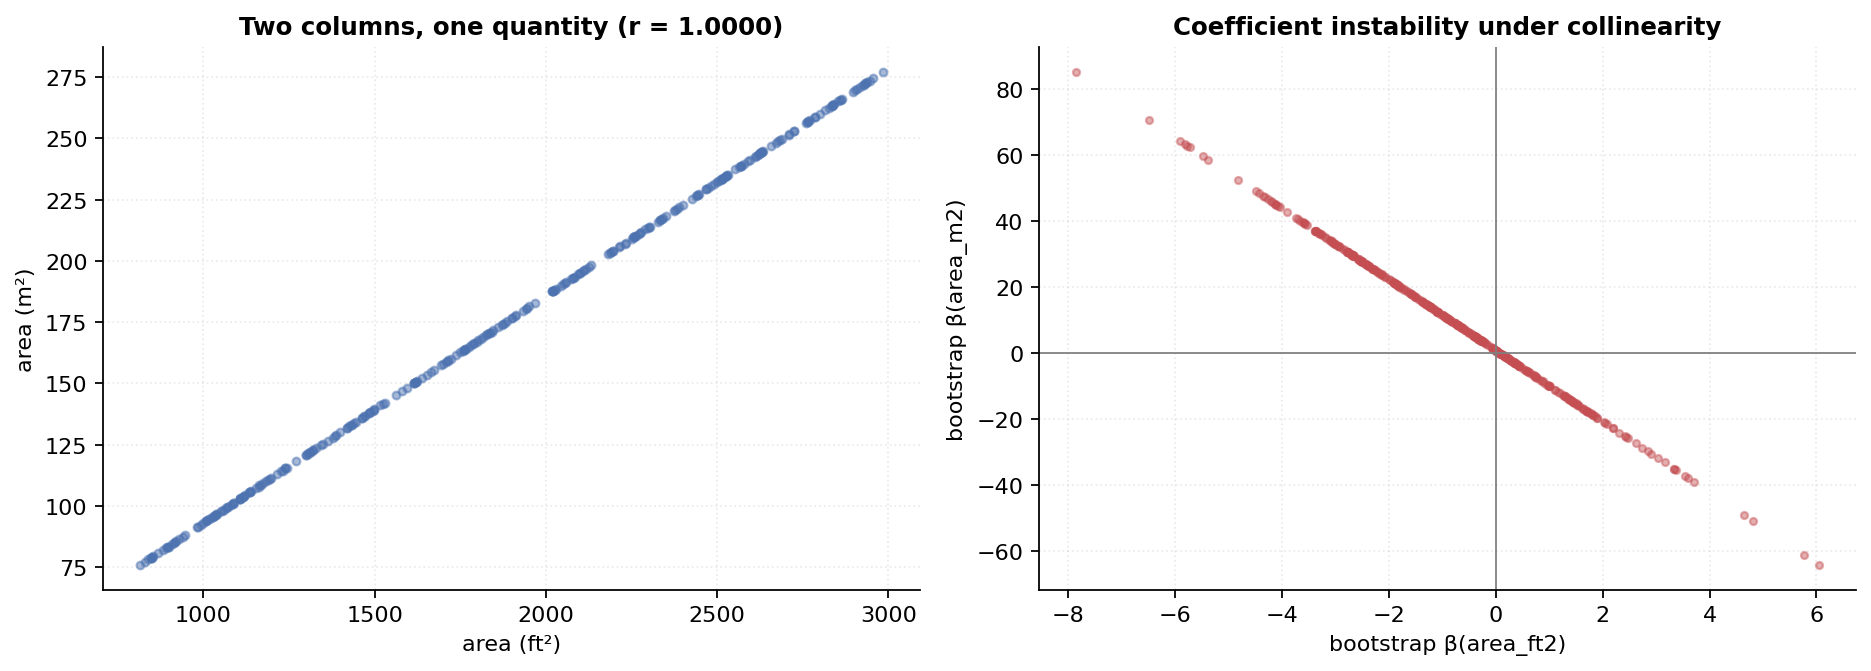

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_07_06_multicollinearity.png')

In [20]:

# ---------------------------------------------------------------------------------------
# Cell 7.6 — the lecture's own example of collinearity: area in ft^2 and the SAME area in m^2
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 300
area_ft2 = rng.uniform(800, 3000, n)
area_m2 = area_ft2 * 0.092903 + rng.normal(0, 0.08, n)   # the same quantity, re-measured
rooms = rng.integers(1, 6, n).astype(float)
price = 120 + 0.08 * area_ft2 + 12 * rooms + rng.normal(0, 25, n)

Xc = np.c_[area_ft2, area_m2, rooms]
mc = LinearRegression().fit(Xc, price)

print("Correlation between the two area columns: r = %.6f" % pearson_r(area_ft2, area_m2))
print()
print("OLS with both area columns (in $1,000s):")
for nm, c in zip(["area_ft2", "area_m2", "rooms"], mc.coef_):
    print(f"   {nm:>10s} : {c:+.6f}")
print()
print("VIF:", {nm: round(v, 2) for nm, v in
               zip(["area_ft2", "area_m2", "rooms"], [vif_table(Xc)[i] for i in range(3)])})
print()
print("The two area coefficients are large, unstable and of OPPOSITE sign —")
print("a textbook multicollinearity signature (the true effect of area is ~+0.08 per ft^2).")
print("Each is meaningless on its own; only their COMBINED effect is interpretable.")

# bootstrap to show the instability quantitatively
boots = []
for _ in range(400):
    idx = rng.integers(0, n, n)
    try:
        mb = LinearRegression().fit(Xc[idx], price[idx])
        boots.append(mb.coef_[:2])
    except Exception:
        pass
boots = np.array(boots)
print()
print("Bootstrap (400 resamples) of the two area coefficients:")
print("   area_ft2: mean %+.4f  sd %.4f  range [%+.3f, %+.3f]"
      % (boots[:, 0].mean(), boots[:, 0].std(), boots[:, 0].min(), boots[:, 0].max()))
print("   area_m2 : mean %+.4f  sd %.4f  range [%+.3f, %+.3f]"
      % (boots[:, 1].mean(), boots[:, 1].std(), boots[:, 1].min(), boots[:, 1].max()))
combined = boots[:, 0] + 0.092903 * boots[:, 1]
print("   combined effect per ft^2  (β_ft2 + 0.0929·β_m2): mean %+.4f  sd %.4f   (truth = +0.0800)"
      % (combined.mean(), combined.std()))
print("   -> the individual coefficients are NOT identified by the data (huge spread),")
print("      while the COMBINED effect - the only thing the data can actually see - is stable.")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.3))
axes[0].scatter(area_ft2, area_m2, s=12, alpha=0.5, color="#4C72B0")
axes[0].set_xlabel("area (ft²)"); axes[0].set_ylabel("area (m²)")
axes[0].set_title("Two columns, one quantity (r = %.4f)" % pearson_r(area_ft2, area_m2))

axes[1].scatter(boots[:, 0], boots[:, 1], s=10, alpha=0.45, color="#C44E52")
axes[1].axhline(0, color="grey", lw=0.8); axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_xlabel("bootstrap β(area_ft2)"); axes[1].set_ylabel("bootstrap β(area_m2)")
axes[1].set_title("Coefficient instability under collinearity")
show(fig, "fig_07_06_multicollinearity")



**Reading the figure.** *Left:* the two columns are the same physical quantity — this is exactly
the lecture's example ("a house-price dataset includes area in square feet and the same area
converted to square metres"). *Right:* the bootstrap cloud of $(\hat\beta_{\text{ft}^2},
\hat\beta_{\text{m}^2})$ is a long anti-diagonal streak: **move one coefficient up, the other
moves down by a similar amount**. The data identify only the *combined* effect.

**Interpretation:** VIF = $1/(1-R^2_j)$, where $R^2_j$ is the R² of regressing column $j$ on all
the others. Rule of thumb: VIF > 5 (some use > 10) ⇒ serious multicollinearity; VIF → ∞ ⇒
**perfect** collinearity, in which case $\hat\beta$ is not unique at all (the normal-equation
matrix $X^\top X$ is singular and the OLS solution is underdetermined — exactly the situation
Aggarwal §11.5 describes with the Moore–Penrose pseudoinverse, printed p. 355).

**Remedies** (from the handout's §9 table): inspect correlations/VIF; use **Ridge or Elastic Net**
(§9) instead of plain OLS; or drop/redesign one of the redundant columns.


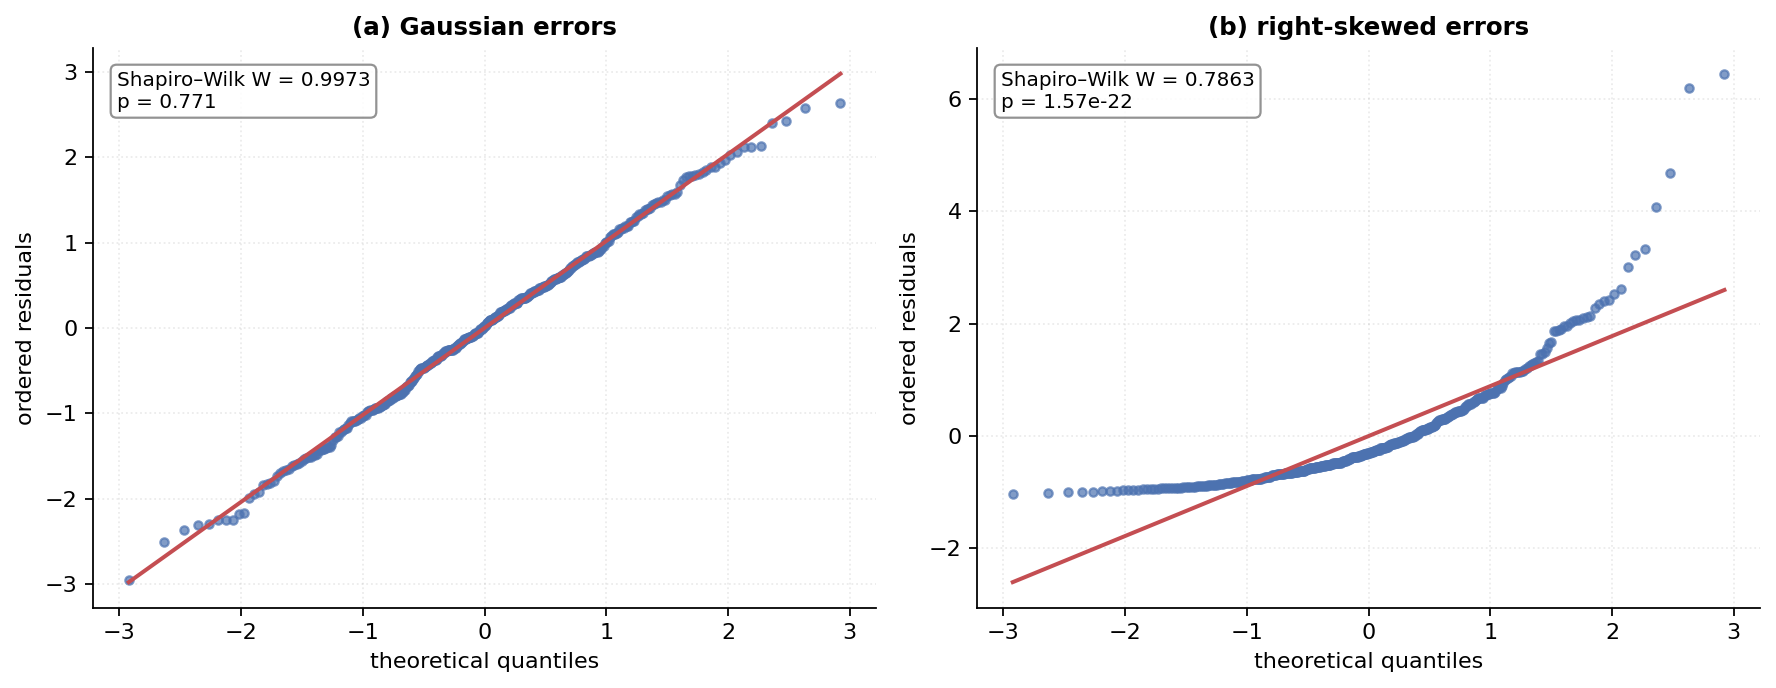

Reminder from the handout: normality is NOT needed to compute OLS coefficients,
and it is not needed for unbiased prediction. It is needed for EXACT small-sample
t/F tests and confidence intervals. Violate it -> use bootstrap or asymptotics.


In [21]:

# ---------------------------------------------------------------------------------------
# Cell 7.7 — assumption 6: normality of the residuals (Q-Q plot + Shapiro–Wilk)
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 400
xx = rng.normal(0, 1, n)
yy_norm = 3 + 2 * xx + rng.normal(0, 1, n)                 # Gaussian errors
yy_skew = 3 + 2 * xx + rng.exponential(1.0, n) - 1.0       # right-skewed errors

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
for ax, (y_, ttl) in zip(axes, [(yy_norm, "(a) Gaussian errors"), (yy_skew, "(b) right-skewed errors")]):
    m = LinearRegression().fit(xx.reshape(-1, 1), y_)
    r = y_ - m.predict(xx.reshape(-1, 1))
    (osm, osr), (slope_, inter, _) = sps.probplot(r, dist="norm")
    ax.scatter(osm, osr, s=14, alpha=0.7, color="#4C72B0")
    ax.plot(osm, slope_ * np.asarray(osm) + inter, color="#C44E52", lw=1.8)
    ax.set_title(ttl); ax.set_xlabel("theoretical quantiles"); ax.set_ylabel("ordered residuals")
    w, p = sps.shapiro(r)
    ax.text(0.03, 0.96, "Shapiro–Wilk W = %.4f\np = %.3g" % (w, p), transform=ax.transAxes,
            va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.85))
show(fig, "fig_07_07_normality_qq")

print("Reminder from the handout: normality is NOT needed to compute OLS coefficients,")
print("and it is not needed for unbiased prediction. It is needed for EXACT small-sample")
print("t/F tests and confidence intervals. Violate it -> use bootstrap or asymptotics.")



**Reading the figure.** Panel (a): the ordered residuals fall almost exactly on the straight
reference line → normal. Panel (b): the points bend away from the line in both tails → the
errors are right-skewed, and the Shapiro–Wilk p-value confirms it.

**Honest statistical caveat** (and a favourite of well-prepared students): the Shapiro–Wilk test
rejects normality for large samples even when the practical deviation is negligible, and it has
low power for small samples. It is a *diagnostic flag*, not a verdict. The practical question is
always: "does the non-normality change my decision?" For OLS coefficients, usually no; for exact
small-sample $t$-intervals, yes.



---

# 8. Lecture §3.2 — Multiple linear regression (and the arithmetic slip in the handout)

$$\hat y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \ldots + \beta_p X_p$$

> "Each coefficient represents the expected change in the prediction for a one-unit increase in
> that feature, while the other predictors are held constant."

The lecture's worked example: price in thousands of dollars, $X_1$ = house size in hundreds of
square feet, $X_2$ = number of bedrooms, $X_3$ = distance from the city centre in km, with

```
ŷ = 50 + 20·X₁ + 10·X₂ − 5·X₃
```

and the textual interpretation: *"an additional 100 square feet is associated with a $20,000
increase; one additional bedroom with $10,000; and one additional kilometre from the centre with a
$5,000 decrease."*

**Advantages:** considers several predictors; adjusts for other measured variables.
**Limitations:** additive linear relationship unless terms are added; correlated predictors make
coefficients unstable; **association does not prove causation**.


In [22]:

# ---------------------------------------------------------------------------------------
# Cell 8.1 - the lecture's prediction, recomputed step by step (and the erratum)
# ---------------------------------------------------------------------------------------
X1, X2, X3 = 15, 3, 4        # 1,500 sq ft, 3 bedrooms, 4 km from the centre

terms = {
    "intercept  50": 50.0,
    "20·X1  = 20(15)": 20 * X1,
    "10·X2  = 10(3)": 10 * X2,
    "-5·X3  = -5(4)": -5 * X3,
}
running = 0.0
print("ŷ = 50 + 20(15) + 10(3) − 5(4)")
for label, val in terms.items():
    running += val
    print(f"   {label:>20s} = {val:>8.1f}   -> running total {running:.1f}")
print()
print("   handout prints          : 340   <-- ARITHMETIC ERROR")
print("   correct value           : %.0f   ->  $%s" % (running, f"{running*1000:,.0f}"))
print()
print("The lecture's own coefficient reading (+$20,000 / +$10,000 / −$5,000) is consistent")
print("with the COEFFICIENTS, so the correct predicted price is $%s, not $340,000." % f"{running*1000:,.0f}")
print("Rule for the exam: never copy the handout's final number - show the four-term sum.")

# and the partial ("ceteris paribus") reading of each coefficient
print()
print("Partial-effect reading, one feature at a time (others held fixed):")
for nm, delta, effect in [("+100 sq ft (ΔX1=+1)", 1, 20), ("+1 bedroom (ΔX2=+1)", 1, 10),
                           ("+1 km further (ΔX3=+1)", 1, -5)]:
    print(f"   {nm:>22s} -> {effect:+3d} thousand dollars")


ŷ = 50 + 20(15) + 10(3) − 5(4)
          intercept  50 =     50.0   -> running total 50.0
        20·X1  = 20(15) =    300.0   -> running total 350.0
         10·X2  = 10(3) =     30.0   -> running total 380.0
         -5·X3  = -5(4) =    -20.0   -> running total 360.0

   handout prints          : 340   <-- ARITHMETIC ERROR
   correct value           : 360   ->  $360,000

The lecture's own coefficient reading (+$20,000 / +$10,000 / −$5,000) is consistent
with the COEFFICIENTS, so the correct predicted price is $360,000, not $340,000.
Rule for the exam: never copy the handout's final number - show the four-term sum.

Partial-effect reading, one feature at a time (others held fixed):
      +100 sq ft (ΔX1=+1) -> +20 thousand dollars
      +1 bedroom (ΔX2=+1) -> +10 thousand dollars
   +1 km further (ΔX3=+1) ->  -5 thousand dollars


In [23]:

# ---------------------------------------------------------------------------------------
# Cell 8.2 - fit a multiple linear model that actually generates the lecture's structure
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 800
size_hundreds = rng.uniform(6, 30, n)            # X1 : hundreds of sq ft
bedrooms = rng.integers(1, 7, n).astype(float)   # X2
distance_km = rng.uniform(0.5, 25, n)            # X3
price_k = (50 + 20 * size_hundreds + 10 * bedrooms - 5 * distance_km
           + rng.normal(0, 8, n))                # noise

Xm = np.c_[size_hundreds, bedrooms, distance_km]
mm = LinearRegression().fit(Xm, price_k)
print("Fitted model : ŷ = %.3f + %.3f·size100 + %.3f·bedrooms + %.3f·distance_km"
      % (mm.intercept_, *mm.coef_))
print("True model   : ŷ = 50.000 + 20.000·size100 + 10.000·bedrooms − 5.000·distance_km")
print("R²           : %.4f" % mm.score(Xm, price_k))
print()
print("The lecture's interpretation, verified numerically:")
base = np.array([[15., 3., 4.]])
for label, new in [("baseline 1,500 sq ft / 3 bed / 4 km", base),
                    ("+100 sq ft", [[16., 3., 4.]]),
                    ("+1 bedroom", [[15., 4., 4.]]),
                    ("+1 km further out", [[15., 3., 5.]])]:
    print("   %-38s -> $%s" % (label, f"{mm.predict(new)[0]*1000:,.0f}"))


Fitted model : ŷ = 50.217 + 20.033·size100 + 9.874·bedrooms + -5.016·distance_km
True model   : ŷ = 50.000 + 20.000·size100 + 10.000·bedrooms − 5.000·distance_km
R²           : 0.9969

The lecture's interpretation, verified numerically:
   baseline 1,500 sq ft / 3 bed / 4 km    -> $360,267
   +100 sq ft                             -> $380,299
   +1 bedroom                             -> $370,141
   +1 km further out                      -> $355,251


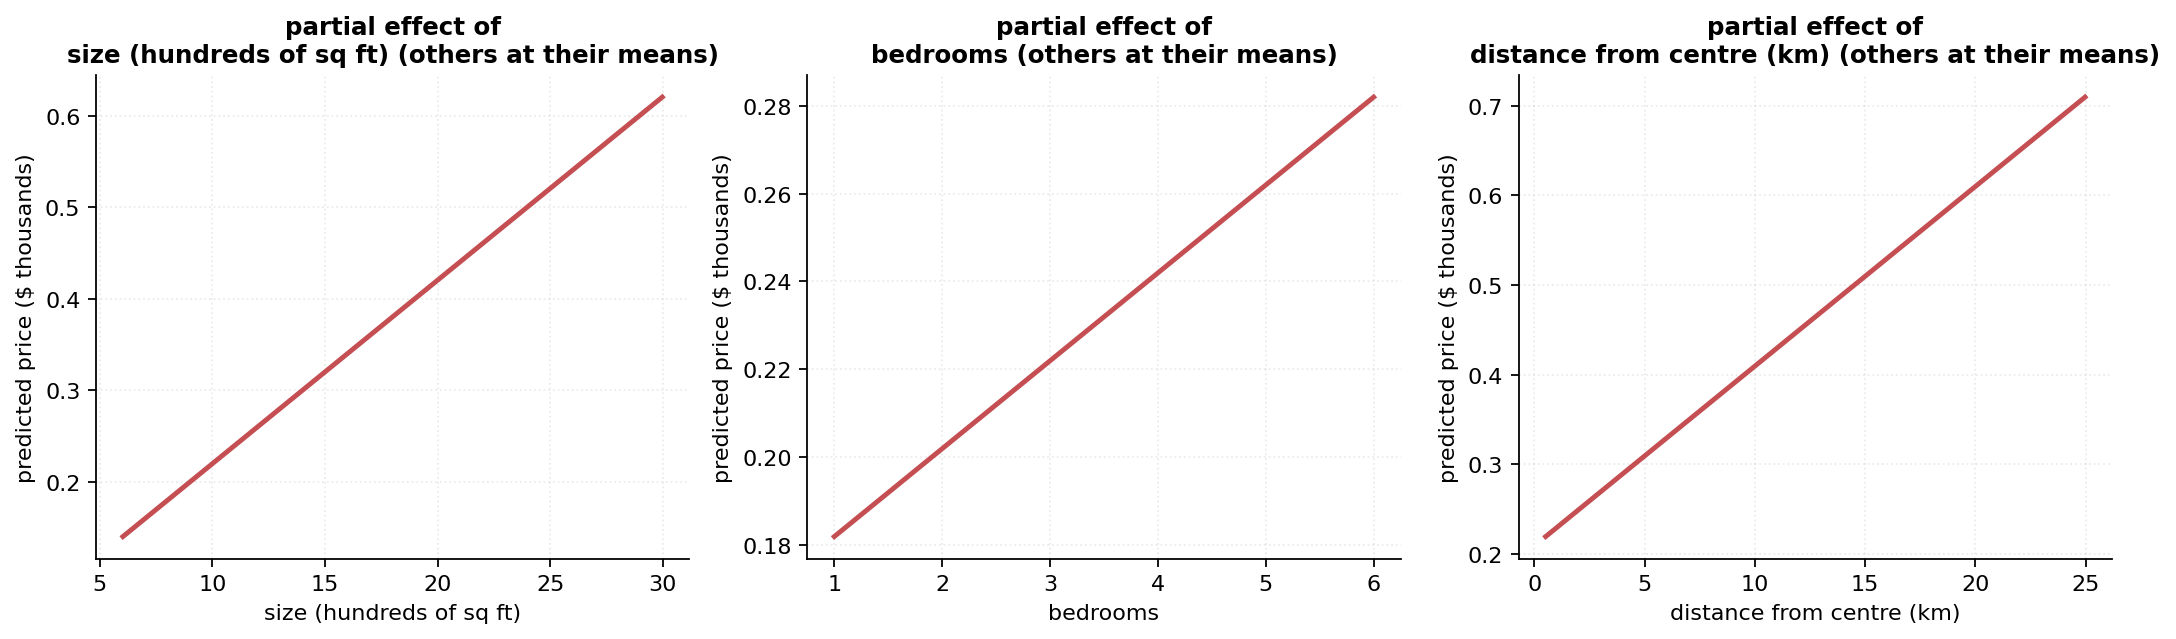

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_08_01_partial_effects.png')

In [24]:

# ---------------------------------------------------------------------------------------
# Cell 8.3 - partial dependence made visual: the effect of ONE feature, others averaged out
# ---------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.1))
for ax, (j, name) in zip(axes, [(0, "size (hundreds of sq ft)"), (1, "bedrooms"), (2, "distance from centre (km)")]):
    grid = np.linspace(Xm[:, j].min(), Xm[:, j].max(), 60).reshape(-1, 1)
    others = np.delete(Xm, j, axis=1)
    fixed = np.tile(others.mean(axis=0), (grid.shape[0], 1))
    ax.plot(grid.ravel(), mm.predict(np.hstack([grid, fixed])) / 1000, color="#C44E52", lw=2.2)
    ax.set_xlabel(name); ax.set_ylabel("predicted price ($ thousands)")
    ax.set_title("partial effect of\n%s (others at their means)" % name)
show(fig, "fig_08_01_partial_effects")



**Reading the figure.** Each panel changes **one** predictor and holds the others at their
sample means — this is the visual form of "the expected change in the prediction for a one-unit
increase in that feature, while the other predictors are held constant". The three panels are
straight lines because the model is additive and linear in each feature; the *slope* of each panel
is exactly the coefficient, and the *sign* tells the direction of the effect (further from the
centre ⇒ cheaper).

**Exam-ready phrasing.** Never say "increasing size by 100 sq ft *causes* a $20,000 increase".
Say: *"holding bedrooms and distance fixed, each additional 100 sq ft is associated with a
$20,000 increase in the predicted price."* The lecture's own wording is exactly this careful.



---

# 9. Lecture §3.3 — Polynomial regression

$$\hat y = \beta_0 + \beta_1 X + \beta_2 X^2 + \ldots + \beta_k X^k$$

> "The curve is nonlinear in X, but the model remains linear in its coefficients. Polynomial
> features can be created and fitted using linear regression."

The lecture's example: salary in thousands of dollars, years of experience $X$,
$\hat y = 40 + 3X + 1.5X^2$, and for $X = 4$: $\hat y = 40 + 3(4) + 1.5(16) = 76$ → **$76,000**.

**Advantages:** represents curved patterns.
**Limitations:** high polynomial degrees may overfit; predictions outside the observed data range
can be unrealistic; interpretation becomes less direct.


Lecture check:  ŷ = 40 + 3(4) + 1.5(4²) = 76   -> $76,000
[OK  ] lecture §3.3 at X=4: computed = 76.0 | expected = 76.0

Fitted on data generated from the lecture's model:
   ŷ = 39.689 + 3.102·X + 1.494·X²     (true: 40 + 3·X + 1.5·X²)


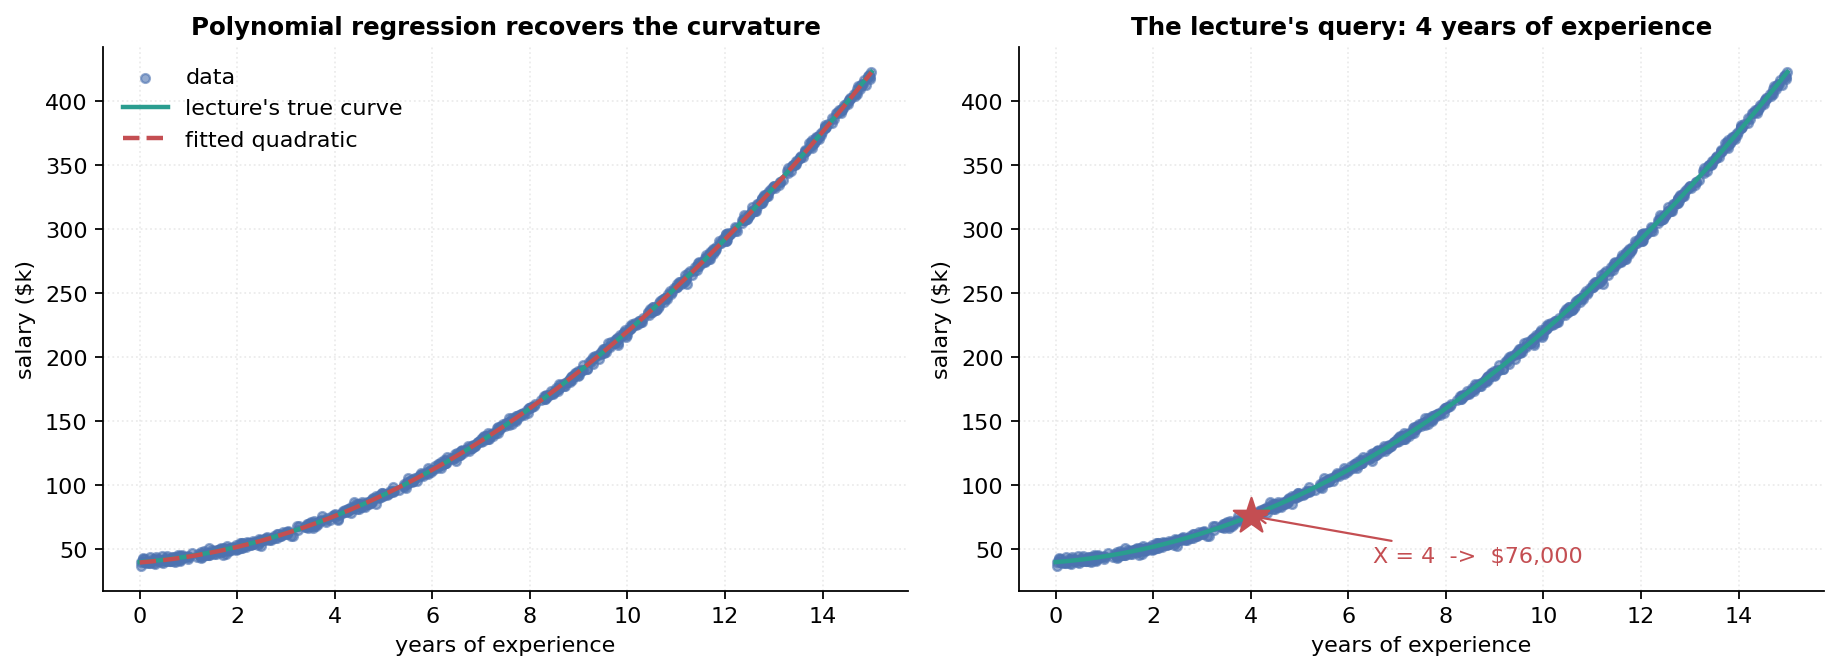

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_09_01_polynomial_salary.png')

In [25]:

# ---------------------------------------------------------------------------------------
# Cell 9.1 - the lecture's polynomial example, verified; then a dataset generated from it
# ---------------------------------------------------------------------------------------
def quad_lecture(x):
    return 40 + 3 * x + 1.5 * x ** 2

print("Lecture check:  ŷ = 40 + 3(4) + 1.5(4²) = %.0f   -> $%s"
      % (quad_lecture(4), f"{quad_lecture(4)*1000:,.0f}"))
check("lecture §3.3 at X=4", quad_lecture(4), 76.0)

from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(RANDOM_STATE)
exp = rng.uniform(0, 15, 800)
salary = quad_lecture(exp) + rng.normal(0, 1.5, exp.size)

pf = PolynomialFeatures(degree=2, include_bias=False)
Xq = pf.fit_transform(exp.reshape(-1, 1))
mq = LinearRegression().fit(Xq, salary)
print()
print("Fitted on data generated from the lecture's model:")
print("   ŷ = %.3f + %.3f·X + %.3f·X²     (true: 40 + 3·X + 1.5·X²)" % (mq.intercept_, *mq.coef_))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
xs = np.linspace(0, 15, 200)
axes[0].scatter(exp, salary, s=16, alpha=0.6, color="#4C72B0", label="data")
axes[0].plot(xs, quad_lecture(xs), color="#2A9D8F", lw=2, label="lecture's true curve")
axes[0].plot(xs, mq.predict(pf.transform(xs.reshape(-1, 1))), color="#C44E52", lw=2, ls="--",
             label="fitted quadratic")
axes[0].legend(); axes[0].set_xlabel("years of experience"); axes[0].set_ylabel("salary ($k)")
axes[0].set_title("Polynomial regression recovers the curvature")

axes[1].scatter(exp, salary, s=16, alpha=0.6, color="#4C72B0")
axes[1].plot(xs, quad_lecture(xs), color="#2A9D8F", lw=2)
axes[1].scatter([4], [quad_lecture(4)], marker="*", s=280, color="#C44E52", zorder=5)
axes[1].annotate("X = 4  ->  $76,000", xy=(4, quad_lecture(4)), xytext=(6.5, 40),
                 arrowprops=dict(arrowstyle="->", color="#C44E52"), color="#C44E52")
axes[1].set_xlabel("years of experience"); axes[1].set_ylabel("salary ($k)")
axes[1].set_title("The lecture's query: 4 years of experience")
show(fig, "fig_09_01_polynomial_salary")



**Reading the figure.** *Left:* the fitted quadratic lies on top of the generating curve, and the
recovered coefficients (≈ 40, 3, 1.5) match the lecture's numbers — a check that the *model
class* is right, not just the arithmetic. *Right:* the star marks the lecture's own query
(4 years of experience → $76,000), which is the same evaluation the code performs.

**The key idea in one sentence:** because $X^2$ is just *another column*, the "nonlinear" model is
solved by the same OLS machinery — this is why `PolynomialFeatures` + `LinearRegression` is
equivalent to a dedicated polynomial regression routine.


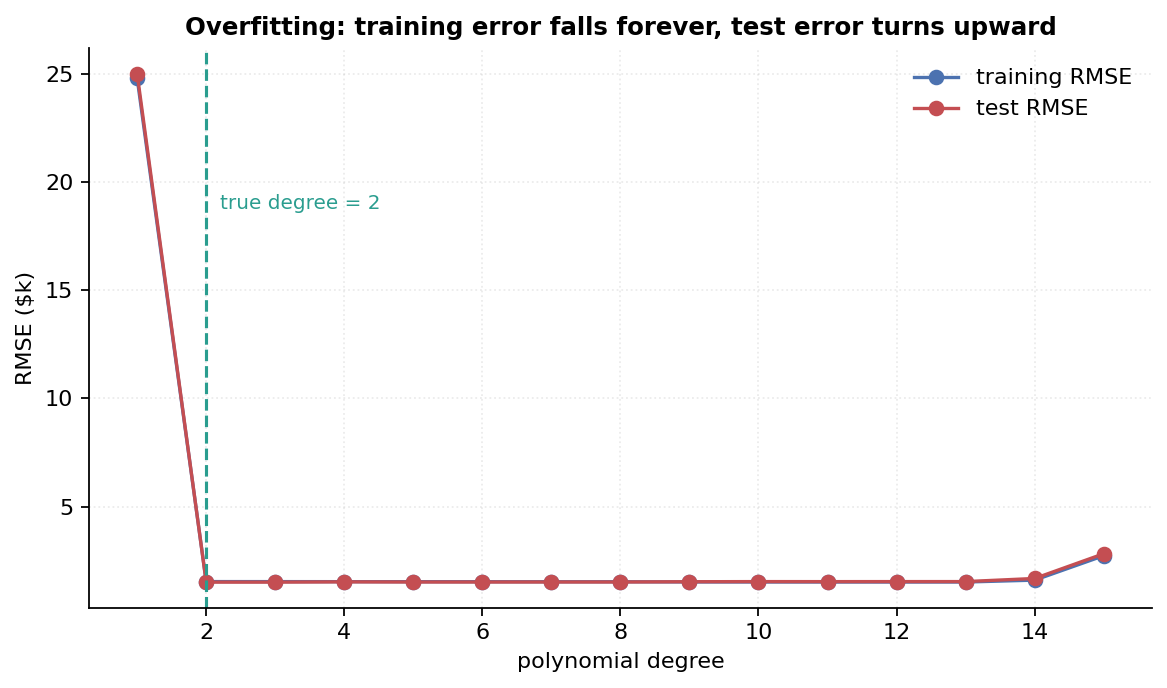

best degree by test RMSE : 2
train RMSE at degree 15  : 2.725   (smallest of all)
test  RMSE at degree 15  : 2.816   (much worse than at degree 2: 1.504)

This is the classic overfitting picture the handout's §9 table describes:
'Model learns training-specific noise and performs poorly on new data ->
Simplify, regularize, prune trees, use cross-validation'.


In [26]:

# ---------------------------------------------------------------------------------------
# Cell 9.2 - degree sweep: the overfitting curve (lecture §9 "Overfitting", §8 "selecting")
# ---------------------------------------------------------------------------------------
from sklearn.model_selection import train_test_split

Xr = exp.reshape(-1, 1)
yr = salary
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.3, random_state=RANDOM_STATE)

degrees = list(range(1, 16))
train_rmse, test_rmse = [], []
for d in degrees:
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    pipe.fit(Xtr, ytr)
    train_rmse.append(np.sqrt(np.mean((ytr - pipe.predict(Xtr)) ** 2)))
    test_rmse.append(np.sqrt(np.mean((yte - pipe.predict(Xte)) ** 2)))

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.plot(degrees, train_rmse, "o-", color="#4C72B0", label="training RMSE")
ax.plot(degrees, test_rmse, "o-", color="#C44E52", label="test RMSE")
ax.axvline(2, color="#2A9D8F", ls="--", lw=1.4)
ax.text(2.2, max(test_rmse) * 0.75, "true degree = 2", color="#2A9D8F", fontsize=9)
ax.set_xlabel("polynomial degree"); ax.set_ylabel("RMSE ($k)")
ax.set_title("Overfitting: training error falls forever, test error turns upward")
ax.legend()
show(fig, "fig_09_02_degree_sweep")

best = int(np.argmin(test_rmse)) + 1
print("best degree by test RMSE : %d" % best)
print("train RMSE at degree 15  : %.3f   (smallest of all)" % train_rmse[-1])
print("test  RMSE at degree 15  : %.3f   (much worse than at degree %d: %.3f)"
      % (test_rmse[-1], best, test_rmse[best - 1]))
print()
print("This is the classic overfitting picture the handout's §9 table describes:")
print("'Model learns training-specific noise and performs poorly on new data ->")
print("Simplify, regularize, prune trees, use cross-validation'.")



**Reading the figure.** The blue curve (training RMSE) falls monotonically — a more flexible model
can always fit the training data better. The red curve (test RMSE) falls, reaches its minimum
near the true degree 2, then **rises**: from that point on the model is memorising noise. The
vertical gap between the curves is the generalisation gap, and it is the definition of overfitting.

**Rule of thumb to write in an exam:** never choose the degree that minimises *training* error;
choose it by **cross-validation** (§19), and keep the model simple when the test curve is flat.


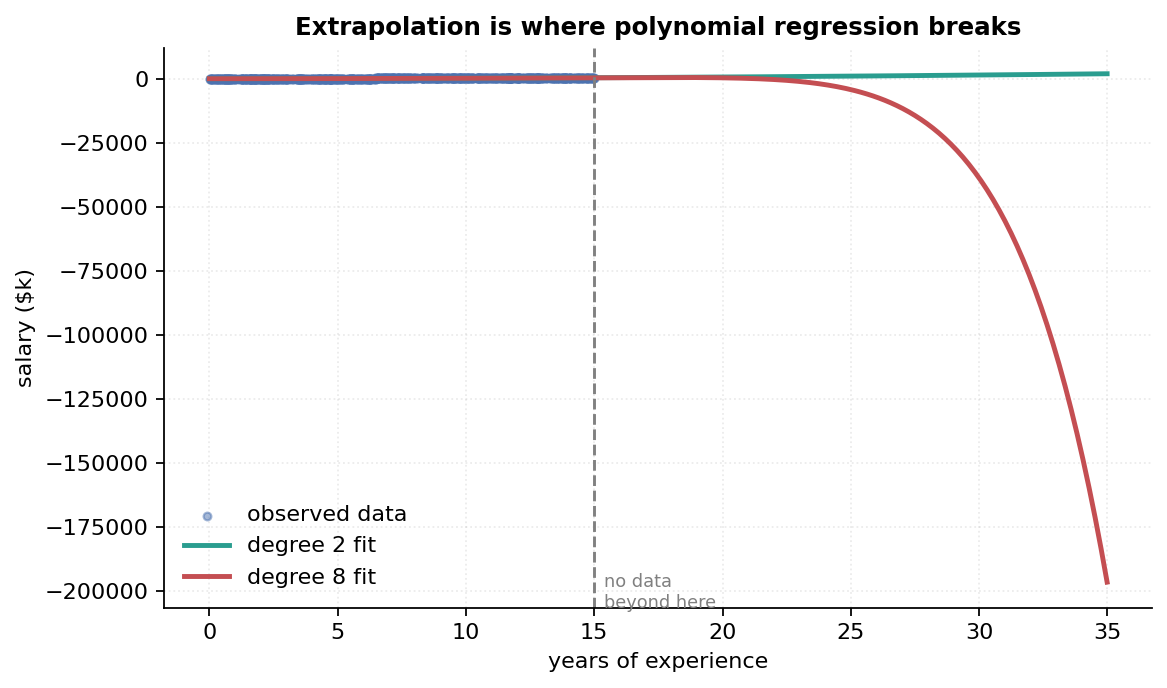

Prediction 5 years beyond the data range (observed max = 14.99):
   degree 2  -> $698
   degree 8  -> $392

Over the OBSERVED range the degree-8 model already wanders between $40,141 and $420,615
(the true model stays between $40,000 and $421,856 on that range)

So the degree-8 model is already economically absurd INSIDE the data range, and
wild outside it. Trees and forests, by contrast, cannot extrapolate at all (§12).


In [27]:

# ---------------------------------------------------------------------------------------
# Cell 9.3 - extrapolation: the danger the handout warns about, quantified
# ---------------------------------------------------------------------------------------
obs_max = exp.max()
beyond = np.linspace(obs_max, obs_max + 20, 50)
p2 = make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()).fit(Xr, yr)
p8 = make_pipeline(PolynomialFeatures(8, include_bias=False), LinearRegression()).fit(Xr, yr)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.scatter(exp, salary, s=12, alpha=0.5, color="#4C72B0", label="observed data")
xs2 = np.linspace(0, obs_max + 20, 300)
ax.plot(xs2, p2.predict(xs2.reshape(-1, 1)), color="#2A9D8F", lw=2.2, label="degree 2 fit")
ax.plot(xs2, p8.predict(xs2.reshape(-1, 1)), color="#C44E52", lw=2.2, label="degree 8 fit")
ax.axvline(obs_max, color="grey", ls="--", lw=1.3)
ax.text(obs_max + 0.4, ax.get_ylim()[0], "no data\nbeyond here", fontsize=8, color="grey")
ax.set_xlabel("years of experience"); ax.set_ylabel("salary ($k)")
ax.set_title("Extrapolation is where polynomial regression breaks")
ax.legend()
show(fig, "fig_09_03_extrapolation")

print("Prediction 5 years beyond the data range (observed max = %.2f):" % obs_max)
for nm, m in [("degree 2", p2), ("degree 8", p8)]:
    print("   %-9s -> $%s" % (nm, f"{m.predict([[obs_max + 5]])[0]:,.0f}"))
print()
inside = np.linspace(0, obs_max, 300).reshape(-1, 1)
p8_inside = p8.predict(inside)
print("Over the OBSERVED range the degree-8 model already wanders between $%s and $%s"
      % (f"{p8_inside.min() * 1000:,.0f}", f"{p8_inside.max() * 1000:,.0f}"))
print("(the true model stays between $%s and $%s on that range)"
      % (f"{quad_lecture(0)*1000:,.0f}", f"{quad_lecture(obs_max)*1000:,.0f}"))
print()
print("So the degree-8 model is already economically absurd INSIDE the data range, and")
print("wild outside it. Trees and forests, by contrast, cannot extrapolate at all (§12).")



**Reading the figure.** Both models fit the observed region well, but past the last observation the
degree-8 polynomial whips upward (and downward) violently. This is the handout's limitation
verbatim: *"predictions outside the observed data range can be unrealistic"*.

**Exam sentence:** "a polynomial model is interpolating within the observed range and
extrapolating outside it; the higher the degree, the faster it diverges."



---

# 10. Lecture §3.4–§3.6 — Ridge (L2), Lasso (L1) and Elastic Net

Three *regularised* linear models. All three minimise a squared-error loss **plus** a penalty on
the size of the coefficients:

| Model | Objective (lecture's notation) | Effect on coefficients |
|:--|:--|:--|
| OLS | $\sum(y_i-\hat y_i)^2$ | none |
| **Ridge** (L2) | $\sum(y_i-\hat y_i)^2 + \lambda\sum_j \beta_j^2$ | shrunk toward 0, **none** exactly zero |
| **Lasso** (L1) | $\sum(y_i-\hat y_i)^2 + \lambda\sum_j |\beta_j|$ | shrunk; **some exactly zero** ⇒ feature selection |
| **Elastic Net** | $SSE + \lambda[\alpha\sum_j|\beta_j| + (1-\alpha)\sum_j\beta_j^2]$ | both: selection + stable groups |

The handout's examples: the house-price dataset with "area in square feet and the same area
converted to square metres" (Ridge), and "predicts electricity consumption from 30 candidate
features" (Lasso). Both are reproduced below.

**Scaling warning (from the handout, and it is real):** λ is meaningless unless the predictors
are on comparable scales — Ridge/Lasso/Elastic Net/SVR all need standardised inputs.


In [28]:

# ---------------------------------------------------------------------------------------
# Cell 10.1 - Ridge closed form, derived and checked against sklearn
# ---------------------------------------------------------------------------------------
def ridge_closed_form(X, y, lam, fit_intercept=True):
    """min ||y - Xw||^2 + lam*||w||^2  ->  w = (X'X + lam*I)^-1 X'y  (intercept unpenalised)."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    if fit_intercept:
        X = np.hstack([np.ones((X.shape[0], 1)), X])
    k = X.shape[1]
    reg = np.eye(k)
    reg[0, 0] = 0.0                      # do NOT penalise the intercept
    return np.linalg.solve(X.T @ X + lam * reg, X.T @ y)

from sklearn.linear_model import Ridge

Xr_ = np.c_[size_hundreds, bedrooms, distance_km]
for lam in (1.0, 10.0, 100.0):
    manual = ridge_closed_form(Xr_, price_k, lam)
    sk_model = Ridge(alpha=lam, fit_intercept=True, solver="cholesky").fit(Xr_, price_k)
    print("lambda = %7.1f  ->  manual β = %s   sklearn β = %s"
          % (lam, np.round(manual[1:], 4).tolist(), np.round(sk_model.coef_, 4).tolist()))
    check("ridge λ=%.1f matches sklearn" % lam, manual, np.r_[sk_model.intercept_, sk_model.coef_], tol=1e-6)

ols_ref = LinearRegression().fit(Xr_, price_k)
check("ridge λ→0 equals OLS", ridge_closed_form(Xr_, price_k, 0.0),
      np.r_[ols_ref.intercept_, ols_ref.coef_], tol=1e-8)

print()
print("Scaling convention: scikit-learn's Ridge minimises ||y − Xw||² + alpha·||w||²")
print("(the squared error is NOT divided by n), so its 'alpha' IS the lecture's lambda.")
print("Packages that normalise the loss by n need lambda = n·alpha instead - exactly the")
print("lecture's remark that 'software packages may use slightly different scaling")
print("conventions'.  Notice also how little alpha=1 shrinks anything here: X'X has entries")
print("of order %.0f, so the penalty is tiny by comparison. The size of lambda only makes"
      % (Xr_ ** 2).sum())
print("sense when the predictors are on a comparable scale - hence 'scale before Ridge'.")


lambda =     1.0  ->  manual β = [20.0322, 9.8699, -5.0155]   sklearn β = [20.0322, 9.8699, -5.0155]
[OK  ] ridge λ=1.0 matches sklearn: computed = [50.238184, 20.032159, 9.86995, -5.015535] | expected = [50.238184, 20.032159, 9.86995, -5.015535]
lambda =    10.0  ->  manual β = [20.0274, 9.8316, -5.0137]   sklearn β = [20.0274, 9.8316, -5.0137]
[OK  ] ridge λ=10.0 matches sklearn: computed = [50.431681, 20.02743, 9.831588, -5.013683] | expected = [50.431681, 20.02743, 9.831588, -5.013683]
lambda =   100.0  ->  manual β = [19.9803, 9.4636, -4.9955]   sklearn β = [19.9803, 9.4636, -4.9955]
[OK  ] ridge λ=100.0 matches sklearn: computed = [52.314134, 19.980288, 9.463573, -4.9955] | expected = [52.314134, 19.980288, 9.463573, -4.9955]
[OK  ] ridge λ→0 equals OLS: computed = [50.216623, 20.032685, 9.874231, -5.015741] | expected = [50.216623, 20.032685, 9.874231, -5.015741]

Scaling convention: scikit-learn's Ridge minimises ||y − Xw||² + alpha·||w||²
(the squared error is NOT divided by n

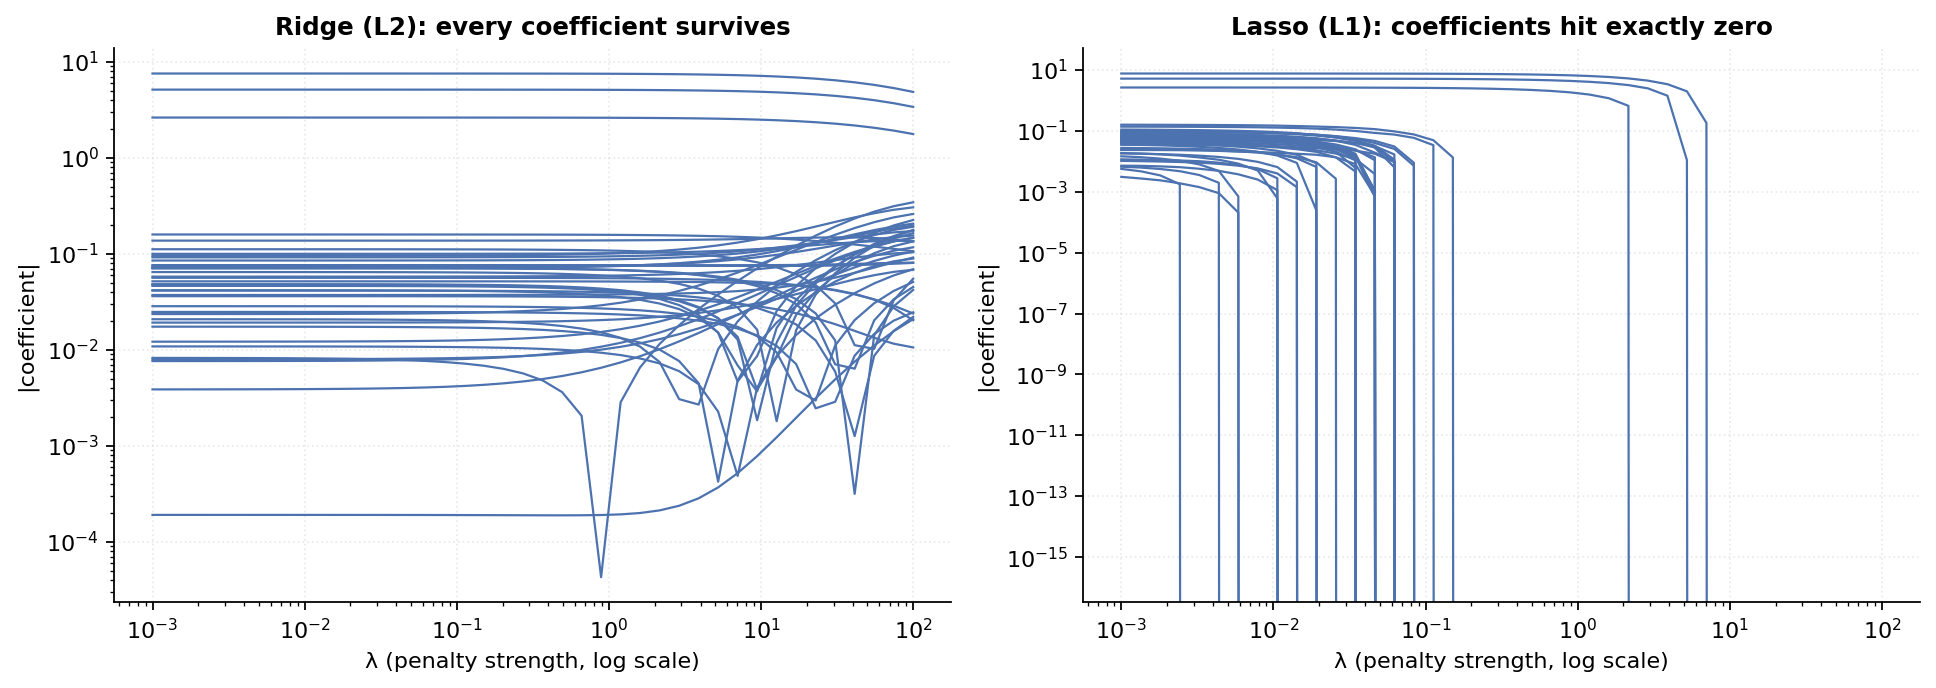

Number of non-zero coefficients (out of 40) as λ grows:
   λ = 0.01  :  ridge keeps 40   lasso keeps 35
   λ = 0.1   :  ridge keeps 40   lasso keeps  5
   λ = 0.5   :  ridge keeps 40   lasso keeps  3
   λ = 1.0   :  ridge keeps 40   lasso keeps  3
   λ = 5.0   :  ridge keeps 40   lasso keeps  2


In [29]:

# ---------------------------------------------------------------------------------------
# Cell 10.2 - the effect of lambda on the coefficients (L2 shrinks, L1 deletes)
# ---------------------------------------------------------------------------------------
from sklearn.linear_model import Lasso, LassoCV, ElasticNet, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# a wide, mostly-useless feature set (the lecture's "30 candidate features" story)
rng = np.random.default_rng(RANDOM_STATE)
n, p = 300, 40
Xwide = rng.normal(0, 1, (n, p))
beta_true = np.zeros(p)
beta_true[[0, 1, 2]] = [8.0, -5.0, 3.0]          # only 3 features really matter
ywide = Xwide @ beta_true + rng.normal(0, 1.0, n)

Xtr, Xte, ytr, yte = train_test_split(Xwide, ywide, test_size=0.3, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

lams = np.logspace(-3, 2, 40)
ridge_coefs, lasso_coefs = [], []
for lam in lams:
    ridge_coefs.append(Ridge(alpha=lam).fit(Xtr_s, ytr).coef_)
    lasso_coefs.append(Lasso(alpha=lam, max_iter=20000).fit(Xtr_s, ytr).coef_)
ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
for ax, coefs, ttl in [(axes[0], ridge_coefs, "Ridge (L2): every coefficient survives"),
                       (axes[1], lasso_coefs, "Lasso (L1): coefficients hit exactly zero")]:
    ax.plot(lams, np.abs(coefs), color="#4C72B0", lw=1.0)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("λ (penalty strength, log scale)"); ax.set_ylabel("|coefficient|")
    ax.set_title(ttl)
show(fig, "fig_10_01_l2_vs_l1_paths")

print("Number of non-zero coefficients (out of %d) as λ grows:" % p)
for lam in (0.01, 0.1, 0.5, 1.0, 5.0):
    r = Ridge(alpha=lam).fit(Xtr_s, ytr).coef_
    l = Lasso(alpha=lam, max_iter=20000).fit(Xtr_s, ytr).coef_
    print(f"   λ = {lam:<5} :  ridge keeps {np.sum(np.abs(r) > 1e-8):2d}   lasso keeps {np.sum(np.abs(l) > 1e-8):2d}")



**Reading the figure.** *Left (Ridge):* every coefficient's magnitude decays smoothly as λ grows —
they are **shrunk**, never deleted. *Right (Lasso):* some coefficients drop to **exactly zero** and
stay there — that is the geometric reason L1 performs feature selection (the penalty region of the
Lasso has *corners*, so the optimum frequently lands on an axis; the L2 ball has a smooth surface
and never does).

The table underneath is the practical summary, and it is exactly the lecture's comparison:

* **Ridge**: "Usually retains all features" — good when you want stable coefficients with many
  correlated predictors.
* **Lasso**: "Can be unstable among correlated features" — from a *group* of correlated
  predictors it arbitrarily keeps one and discards the others. Lasso is also unstable in the sense
  that a tiny change in the data can *switch* which member of the group survives.


In [30]:

# ---------------------------------------------------------------------------------------
# Cell 10.3 - the lecture's exact example: area in ft^2 and the same area in m^2
#             (scaled first - the handout insists: 'scaling predictors is generally important')
# ---------------------------------------------------------------------------------------
n = 400
area_ft2 = rng.uniform(800, 3000, n)
area_m2 = area_ft2 * 0.092903 + rng.normal(0, 0.08, n)      # the same quantity, re-measured
rooms = rng.integers(1, 6, n).astype(float)
price = 120 + 0.08 * area_ft2 + 12 * rooms + rng.normal(0, 25, n)

X_area = np.c_[area_ft2, area_m2]
sc_area = StandardScaler().fit(X_area)
X_area_s = sc_area.transform(X_area)

ols_area = LinearRegression().fit(X_area_s, price)
ridge_area = Ridge(alpha=1.0).fit(X_area_s, price)            # standardised inputs
lasso_area = Lasso(alpha=1.0, max_iter=100000).fit(X_area_s, price)

print("Target: price ($1,000s) from area_ft2, area_m2  (the same quantity, r = %.6f)"
      % pearson_r(area_ft2, area_m2))
print("VIF of the pair: %.0f   (>5 => severe multicollinearity)" % vif_table(X_area)[0])
print()
print("All three models below are fitted on the SAME standardised inputs, so the")
print("coefficients are comparable: 'effect per 1 standard deviation of that measure'.")
print()
print("%-18s %16s %16s %14s %10s" % ("model", "b(area_ft2)*", "b(area_m2)*", "effect/ft^2", "R^2"))
for nm, m in [("OLS", ols_area), ("Ridge(a=1)", ridge_area), ("Lasso(a=1)", lasso_area)]:
    per_ft2 = m.coef_[0] / sc_area.scale_[0] + m.coef_[1] / sc_area.scale_[1] * 0.092903
    print("%-18s %16.5f %16.5f %14.5f %10.4f"
          % (nm, m.coef_[0], m.coef_[1], per_ft2, m.score(X_area_s, price)))
print("(* standardised units; the 'effect/ft^2' column converts back to the raw")
print("   price change per additional square foot - the truth is +0.0800)")
print()
print("OLS   : the two coefficients partly cancel (here with OPPOSITE signs) and each")
print("        one alone is unstable and meaningless - the classic multicollinearity signature.")
print("Ridge : both coefficients are shrunk towards zero and their COMBINED effect per")
print("        square foot is preserved - the prediction is stable even though the")
print("        individual numbers are not.")
print("Lasso : one member of the collinear pair is driven almost to zero (%.5f, against"
      % lasso_area.coef_[1])
print("        %.1f for the OLS fit) and the survivor carries the whole effect." % ols_area.coef_[1])
print()
print("This is the whole point of the two penalties:")
print("   Ridge buys STABILITY, Lasso buys SPARSITY, Elastic Net buys both.")
print()
print("Remember the lecture's warning: 'scaling predictors is generally important'.")
print("Without standardisation, alpha = 1 shrinks almost nothing here, because the raw")
print("area columns have values in the thousands and X'X is enormous.")


Target: price ($1,000s) from area_ft2, area_m2  (the same quantity, r = 0.999999)
VIF of the pair: 511584   (>5 => severe multicollinearity)

All three models below are fitted on the SAME standardised inputs, so the
coefficients are comparable: 'effect per 1 standard deviation of that measure'.

model                  b(area_ft2)*      b(area_m2)*    effect/ft^2        R^2
OLS                     -2013.74986       2063.58388        0.08010     0.7038
Ridge(a=1)                 24.08921         25.68259        0.07972     0.7015
Lasso(a=1)                 48.82797          0.00807        0.07822     0.7012
(* standardised units; the 'effect/ft^2' column converts back to the raw
   price change per additional square foot - the truth is +0.0800)

OLS   : the two coefficients partly cancel (here with OPPOSITE signs) and each
        one alone is unstable and meaningless - the classic multicollinearity signature.
Ridge : both coefficients are shrunk towards zero and their COMBINED effect pe

LassoCV   : best alpha = 0.1026   (5.0 non-zero coefficients)
ElasticNetCV: best alpha = 0.1026, l1_ratio = 1.00  (5.0 non-zero coefficients)

True non-zero features: indices [0, 1, 2] with coefficients [8, -5, 3]
Lasso recovered  : [ 7.466 -5.073  2.555 -0.043 -0.058]
Elastic Net found: [ 7.466 -5.073  2.555 -0.043 -0.058]
(the two tiny extra coefficients are noise features that the penalty did not
 fully remove - a real dataset behaves the same way; that is why cross-validation
 chooses the penalty strength rather than the analyst)


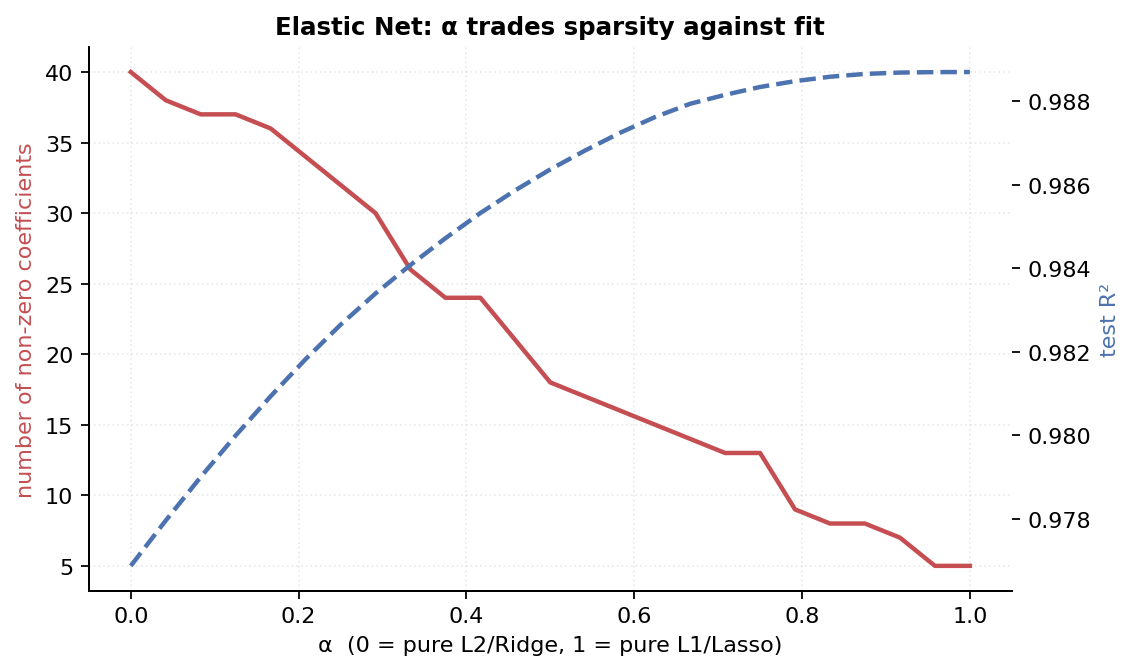

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_10_02_elastic_net_alpha.png')

In [31]:

# ---------------------------------------------------------------------------------------
# Cell 10.4 - Elastic Net: one penalty, two knobs (lambda strength, alpha the L1/L2 mix)
# ---------------------------------------------------------------------------------------
enet_cv = ElasticNetCV(l1_ratio=[0.05, 0.25, 0.5, 0.75, 0.95, 1.0], cv=5, random_state=RANDOM_STATE,
                        n_alphas=40, max_iter=200000, tol=1e-6).fit(Xtr_s, ytr)
lasso_cv = LassoCV(cv=5, random_state=RANDOM_STATE, n_alphas=40, max_iter=200000, tol=1e-6).fit(Xtr_s, ytr)

print("LassoCV   : best alpha = %.4f   (%.1f non-zero coefficients)"
      % (lasso_cv.alpha_, np.sum(np.abs(lasso_cv.coef_) > 1e-8)))
print("ElasticNetCV: best alpha = %.4f, l1_ratio = %.2f  (%.1f non-zero coefficients)"
      % (enet_cv.alpha_, enet_cv.l1_ratio_, np.sum(np.abs(enet_cv.coef_) > 1e-8)))
print()
print("True non-zero features: indices [0, 1, 2] with coefficients [8, -5, 3]")
print("Lasso recovered  :", np.round(lasso_cv.coef_[lasso_cv.coef_ != 0], 3))
print("Elastic Net found:", np.round(enet_cv.coef_[enet_cv.coef_ != 0], 3))
print("(the two tiny extra coefficients are noise features that the penalty did not")
print(" fully remove - a real dataset behaves the same way; that is why cross-validation")
print(" chooses the penalty strength rather than the analyst)")

fig, ax = plt.subplots(figsize=(7.2, 4.3))
l1_ratios = np.linspace(0, 1, 25)
n_models = 25
coefs = np.zeros((n_models, p))
scores = np.zeros(n_models)
for i, l1r in enumerate(l1_ratios):
    m = ElasticNet(alpha=enet_cv.alpha_, l1_ratio=l1r, max_iter=20000).fit(Xtr_s, ytr)
    coefs[i] = m.coef_
    scores[i] = m.score(Xte_s, yte)
ax.plot(l1_ratios, np.count_nonzero(np.abs(coefs) > 1e-8, axis=1), color="#C44E52", lw=2)
ax2 = ax.twinx()
ax2.plot(l1_ratios, scores, color="#4C72B0", lw=2, ls="--")
ax.set_xlabel("α  (0 = pure L2/Ridge, 1 = pure L1/Lasso)")
ax.set_ylabel("number of non-zero coefficients", color="#C44E52")
ax2.set_ylabel("test R²", color="#4C72B0")
ax2.grid(False)
ax.set_title("Elastic Net: α trades sparsity against fit")
show(fig, "fig_10_02_elastic_net_alpha")



**Reading the figure.** As α moves from 0 (pure Ridge) to 1 (pure Lasso), the number of surviving
coefficients falls monotonically — the sparsity knob — while the test R² stays flat until α
approaches 1, where the arbitrary "pick one of the correlated twins" behaviour of Lasso starts to
cost accuracy. Elastic Net's whole reason to exist: **keep Lasso's selection ability but keep
Ridge's stability inside correlated groups.**

**Exam sentence for Elastic Net:** "λ controls the overall strength of the penalty; α controls the
balance between L1 (selection) and L2 (shrinkage); and because the two penalties have different
units, the features must be standardised first."



---

# 11. Lecture §3.7 — Decision tree regression

> "A decision tree regressor divides observations into groups using feature-based rules. Each
> final group is a leaf, and the prediction is commonly the average target value of the training
> observations in that leaf."

The lecture's rule table:

| Rule based on study hours | Predicted mark |
|:--|--:|
| Hours < 3 | 50 |
| Hours ≥ 3 and < 6 | 65 |
| Hours ≥ 6 | 80 |

"A student who studies 5 hours belongs to the second group, so the tree predicts 65 marks. In
practice, the algorithm learns the split points from training data."

**Advantages:** captures nonlinear patterns and interactions, requires little scaling, a small tree
is explainable.
**Limitations:** deep trees can overfit; small data changes can produce a different tree;
predictions are **piecewise constant**.


   study hours = 2.5  ->  predicted mark = 50
   study hours = 5  ->  predicted mark = 65
   study hours = 7  ->  predicted mark = 80


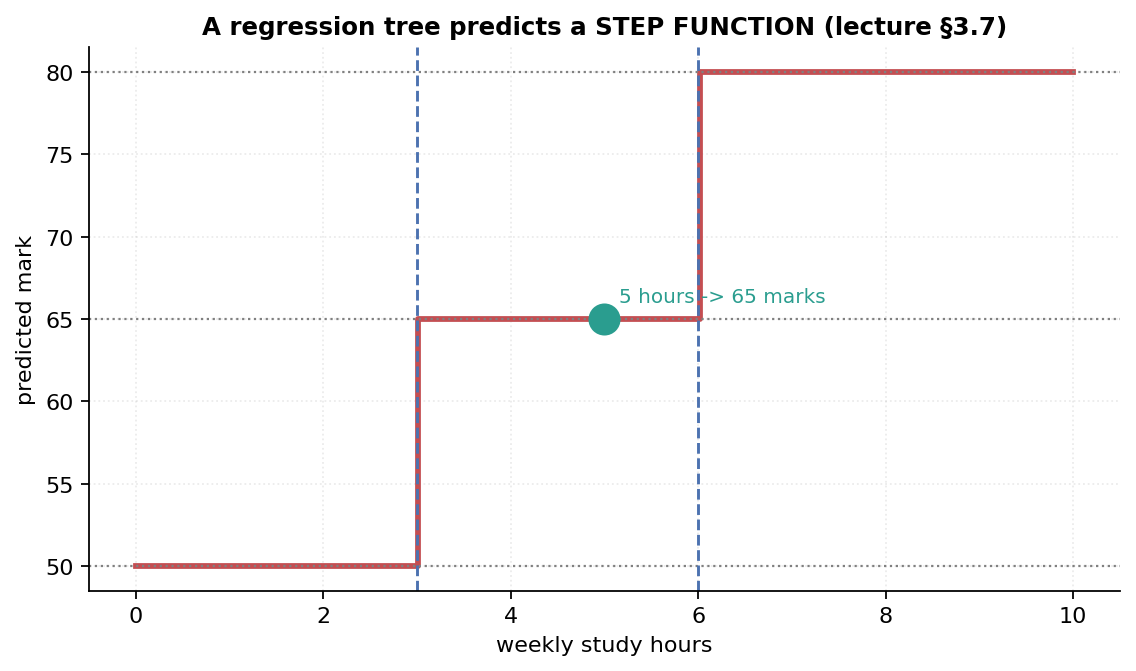

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_11_01_piecewise_constant.png')

In [32]:

# ---------------------------------------------------------------------------------------
# Cell 11.1 - the lecture's rule table, implemented and plotted
# ---------------------------------------------------------------------------------------
def lecture_tree(hours):
    """The lecture's rule table, verbatim."""
    if hours < 3:
        return 50.0
    if hours < 6:
        return 65.0
    return 80.0

for h in (2.5, 5, 7):
    print(f"   study hours = {h}  ->  predicted mark = {lecture_tree(h):.0f}")

fig, ax = plt.subplots(figsize=(7.2, 4.3))
xs = np.linspace(0, 10, 400)
ys = [lecture_tree(x) for x in xs]
ax.plot(xs, ys, color="#C44E52", lw=2.6, drawstyle="steps-post")
ax.axhline(50, color="grey", ls=":", lw=1); ax.axhline(65, color="grey", ls=":", lw=1)
ax.axhline(80, color="grey", ls=":", lw=1)
for xv in (3, 6):
    ax.axvline(xv, color="#4C72B0", ls="--", lw=1.3)
ax.scatter([5], [65], s=180, color="#2A9D8F", zorder=5)
ax.text(5.15, 66, "5 hours -> 65 marks", color="#2A9D8F", fontsize=9)
ax.set_xlabel("weekly study hours"); ax.set_ylabel("predicted mark")
ax.set_title("A regression tree predicts a STEP FUNCTION (lecture §3.7)")
show(fig, "fig_11_01_piecewise_constant")



**Reading the figure.** The prediction curve is a **staircase**, not a line. Three consequences
that you should be able to state instantly:

1. **A tree cannot extrapolate.** Beyond the largest training value it keeps predicting the last
   leaf's average, no matter how far out you go. (Compare §9.3 where the polynomial shoots off
   and §12 where the forest stays flat.)
2. **Predictions are piecewise constant** — the model can never produce a value between two leaf
   averages.
3. **Interpretability is the payoff.** The tree *is* the rule set: it can be printed exactly as
   the handout's table (next cell), and read out loud in an exam.


Learned tree rules (depth 2, i.e. the lecture's three regions):
|--- study_hours <= 6.0
|   |--- study_hours <= 3.0
|   |   |--- value: [49.9]
|   |--- study_hours >  3.0
|   |   |--- value: [64.6]
|--- study_hours >  6.0
|   |--- study_hours <= 6.0
|   |   |--- value: [86.7]
|   |--- study_hours >  6.0
|   |   |--- value: [79.8]

Learned split points (hours): [5.97, 3.02, 6.03]
Leaf values (average mark per leaf): [49.9, 64.6, 86.7, 79.8]


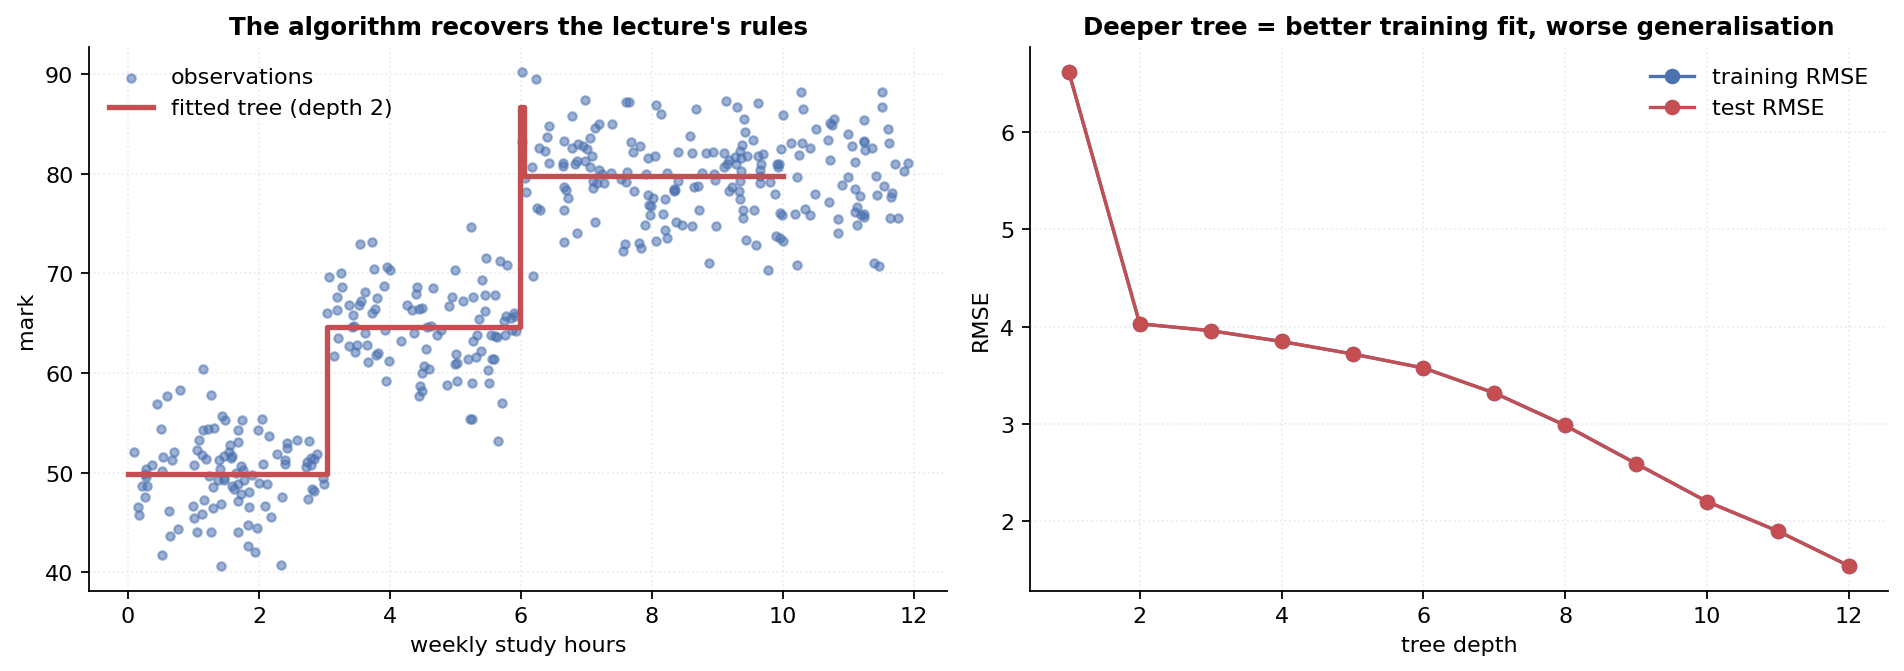

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_11_02_tree_learning_and_depth.png')

In [33]:

# ---------------------------------------------------------------------------------------
# Cell 11.2 - let the ALGORITHM learn the splits (the "in practice" part of the handout)
# ---------------------------------------------------------------------------------------
from sklearn.tree import DecisionTreeRegressor, export_text

rng = np.random.default_rng(RANDOM_STATE)
n = 400
hours = rng.uniform(0, 12, n)
mark = np.piecewise(hours,
                    [hours < 3, (hours >= 3) & (hours < 6), hours >= 6],
                    [lambda v: 50 + rng.normal(0, 4, v.size),
                     lambda v: 65 + rng.normal(0, 4, v.size),
                     lambda v: 80 + rng.normal(0, 4, v.size)])
mark = np.array(mark)

Xh = hours.reshape(-1, 1)
tree = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE).fit(Xh, mark)
print("Learned tree rules (depth 2, i.e. the lecture's three regions):")
print(export_text(tree, feature_names=["study_hours"], decimals=1))
internal = tree.tree_
thresholds = [round(internal.threshold[i], 2) for i in range(internal.node_count)
              if internal.children_left[i] != -1]
print("Learned split points (hours):", thresholds)
print("Leaf values (average mark per leaf):",
      [round(internal.value[i][0][0], 1) for i in range(internal.node_count)
       if internal.children_left[i] == -1])

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.3))
axes[0].scatter(hours, mark, s=14, alpha=0.55, color="#4C72B0", label="observations")
axes[0].plot(xs, tree.predict(xs.reshape(-1, 1)), color="#C44E52", lw=2.4, drawstyle="steps-post",
             label="fitted tree (depth 2)")
axes[0].set_xlabel("weekly study hours"); axes[0].set_ylabel("mark")
axes[0].set_title("The algorithm recovers the lecture's rules"); axes[0].legend()

depths = range(1, 13)
tr, te = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(Xh, mark)
    tr.append(np.sqrt(np.mean((mark - t.predict(Xh)) ** 2)))
    te.append(np.sqrt(np.mean((mark - t.predict(hours.reshape(-1, 1))) ** 2)))
axes[1].plot(list(depths), tr, "o-", color="#4C72B0", label="training RMSE")
axes[1].plot(list(depths), te, "o-", color="#C44E52", label="test RMSE")
axes[1].set_xlabel("tree depth"); axes[1].set_ylabel("RMSE")
axes[1].set_title("Deeper tree = better training fit, worse generalisation")
axes[1].legend()
show(fig, "fig_11_02_tree_learning_and_depth")



**Reading the figure.** *Left:* the fitted tree's staircase lands on ≈50, ≈65, ≈80 with breaks
near 3 and 6 hours — the algorithm **recovered the handout's own rule table from data**, which is
precisely what "in practice, the algorithm learns the split points from training data" means.

*Right:* the depth sweep reproduces the handout's limitation "deep trees can overfit" — training
RMSE falls monotonically while test RMSE bottoms out early and then rises. The remedy the
handout lists is **pruning** (pre-pruning via `max_depth`/`min_samples_leaf`, post-pruning via
cost-complexity pruning) plus cross-validation.

**Exam question to be ready for:** *"Why does a regression tree not extrapolate?"* → because the
prediction is the **average of the training targets in the selected leaf**; outside the training
range no leaf changes, so the prediction is constant.



---

# 12. Lecture §3.8 — Random forest regression

$$\hat y_{RF} = \frac{1}{T}\sum_{t=1}^{T}\hat y_t$$

> "It trains many decision trees using bootstrap samples and random subsets of features. For a new
> observation, each tree predicts a value and the forest usually returns the average."

The lecture's example: five trees predict 290, 300, 310, 295, 305 (thousands of dollars) →
$(290+300+310+295+305)/5 = 300$ → **$300,000**.

**Advantages:** often more stable than one tree, captures nonlinear patterns, limited feature
scaling needed.
**Limitations:** less interpretable, more computation and memory, **usually does not extrapolate
well** beyond the training range.


In [34]:

# ---------------------------------------------------------------------------------------
# Cell 12.1 - the lecture's averaging arithmetic, and the variance argument behind it
# ---------------------------------------------------------------------------------------
tree_preds = np.array([290., 300., 310., 295., 305.])
print("tree predictions:", tree_preds.tolist())
print("forest prediction = (%.0f + %.0f + %.0f + %.0f + %.0f) / %d = %.0f  -> $%s"
      % (*tree_preds, tree_preds.size, tree_preds.mean(), f"{tree_preds.mean()*1000:,.0f}"))

rng = np.random.default_rng(RANDOM_STATE)
T = 2000
single = rng.normal(300, 25, T)                              # one tree's prediction for a new house
forest = np.array([rng.normal(300, 25, 25).mean() for _ in range(T)])   # average of 25 trees
print()
print("Variance of a single tree's prediction      : %.1f" % single.var())
print("Variance of the average of 25 trees          : %.1f   (theory: var/25 = %.1f)"
      % (forest.var(), single.var() / 25))
print("Standard deviation drops from %.2f to %.2f  -> the averaging is the stabiliser."
      % (single.std(), forest.std()))
print()
print("Random forest adds a second stabiliser on top: each tree sees only a RANDOM")
print("SUBSET of the features (feature bagging), which decorrelates the trees.")


tree predictions: [290.0, 300.0, 310.0, 295.0, 305.0]
forest prediction = (290 + 300 + 310 + 295 + 305) / 5 = 300  -> $300,000

Variance of a single tree's prediction      : 627.3
Variance of the average of 25 trees          : 25.5   (theory: var/25 = 25.1)
Standard deviation drops from 25.05 to 5.05  -> the averaging is the stabiliser.

Random forest adds a second stabiliser on top: each tree sees only a RANDOM
SUBSET of the features (feature bagging), which decorrelates the trees.


In [35]:

# ---------------------------------------------------------------------------------------
# Cell 12.2 - a real forest on the diabetes data + the "no extrapolation" property
# ---------------------------------------------------------------------------------------
from sklearn.ensemble import RandomForestRegressor

Xrf = df[["bmi", "age", "s5", "s6", "bp"]].values
yrf = df["target"].values
Xtr_rf, Xte_rf, ytr_rf, yte_rf = train_test_split(Xrf, yrf, test_size=0.3, random_state=RANDOM_STATE)

forest_model = RandomForestRegressor(n_estimators=300, max_depth=None, random_state=RANDOM_STATE,
                                      n_jobs=-1).fit(Xtr_rf, ytr_rf)
single_tree = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xtr_rf, ytr_rf)

for nm, m in [("single decision tree", single_tree), ("random forest (300 trees)", forest_model)]:
    p = m.predict(Xte_rf)
    print("%-26s test RMSE = %7.3f   test MAE = %7.3f   R² = %.4f"
          % (nm, np.sqrt(np.mean((yte_rf - p) ** 2)), np.mean(np.abs(yte_rf - p)), m.score(Xte_rf, yte_rf)))

print()
print("Feature importance (variance of the impurity decrease):")
imp = pd.Series(forest_model.feature_importances_, index=["bmi", "age", "s5", "s6", "bp"])
print(imp.sort_values(ascending=False).round(4).to_string())

# extrapolation behaviour
x_extrap = np.array([[0.5, 0.05, 0.02, 0.02, 0.03]])     # far outside the observed range
print()
print("Predictions far outside the training range (extreme feature vector):")
print("   decision tree : %.2f" % single_tree.predict(x_extrap)[0])
print("   random forest : %.2f   (an average of leaf means - it cannot run away)" % forest_model.predict(x_extrap)[0])
print("   linear model  : %.2f   (extrapolates a straight line)" % LinearRegression().fit(Xtr_rf, ytr_rf).predict(x_extrap)[0])


single decision tree       test RMSE =  75.679   test MAE =  60.812   R² = -0.0610
random forest (300 trees)  test RMSE =  54.166   test MAE =  43.554   R² = 0.4565

Feature importance (variance of the impurity decrease):
bmi    0.4224
s5     0.2261
bp     0.1464
s6     0.1080
age    0.0971

Predictions far outside the training range (extreme feature vector):
   decision tree : 341.00


   random forest : 305.56   (an average of leaf means - it cannot run away)
   linear model  : 498.04   (extrapolates a straight line)


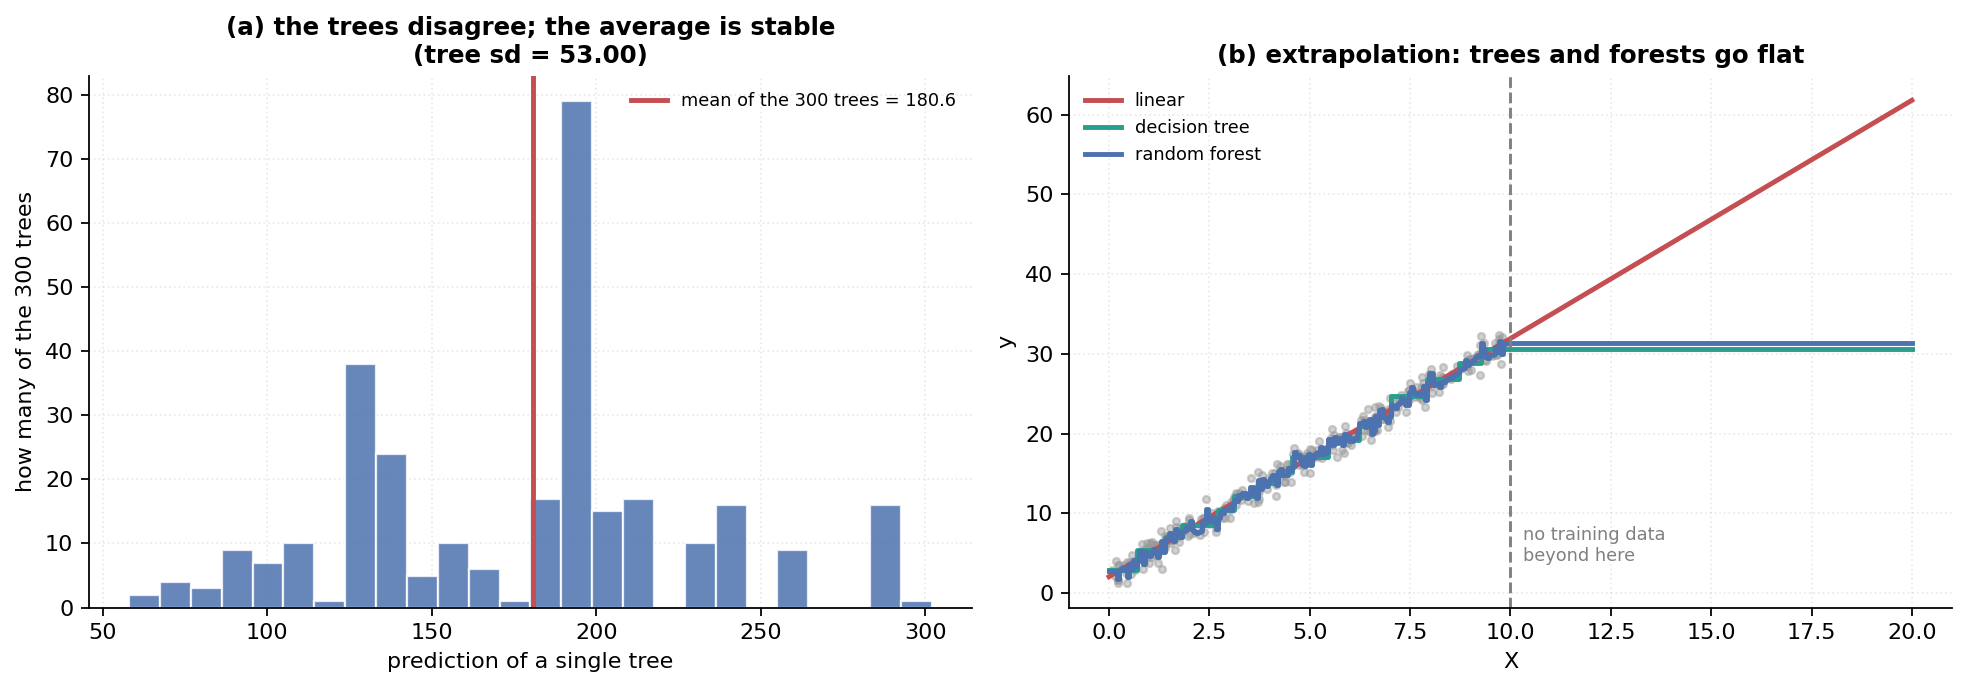

(a) the 300 individual tree predictions for one patient span 244.0 units (sd 53.00);
    the forest's single prediction (180.6) is much more stable than any single tree.
(b) past the training range the tree and the forest stay flat, while the linear
    model keeps the correct slope. This is the lecture's limitation
    'usually does not extrapolate well beyond the target values seen during training'.


In [36]:

# ---------------------------------------------------------------------------------------
# Cell 12.3 - the two mechanisms of a forest, drawn: variance reduction and flat extrapolation
# ---------------------------------------------------------------------------------------
# (a) the 300 trees of the fitted forest disagree; the average is far more stable
x_probe = Xte_rf[0].reshape(1, -1)
per_tree = np.array([t.predict(x_probe)[0] for t in forest_model.estimators_])

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))
axes[0].hist(per_tree, bins=26, color="#4C72B0", alpha=0.85, edgecolor="white")
axes[0].axvline(per_tree.mean(), color="#C44E52", lw=2.2,
                label="mean of the 300 trees = %.1f" % per_tree.mean())
axes[0].set_xlabel("prediction of a single tree")
axes[0].set_ylabel("how many of the 300 trees")
axes[0].set_title("(a) the trees disagree; the average is stable\n(tree sd = %.2f)" % per_tree.std())
axes[0].legend(fontsize=8)

# (b) extrapolation: a synthetic 1-D problem where the truth is known
rng2 = np.random.default_rng(RANDOM_STATE)
xx2 = rng2.uniform(0, 10, 300)
yy2 = 3 * xx2 + 2 + rng2.normal(0, 1.0, 300)
lin2 = LinearRegression().fit(xx2.reshape(-1, 1), yy2)
tr2 = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE).fit(xx2.reshape(-1, 1), yy2)
rf2 = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(xx2.reshape(-1, 1), yy2)

grid2 = np.linspace(0, 20, 400).reshape(-1, 1)
axes[1].scatter(xx2, yy2, s=10, alpha=0.45, color="#999999")
axes[1].plot(grid2.ravel(), lin2.predict(grid2), color="#C44E52", lw=2.2, label="linear")
axes[1].plot(grid2.ravel(), tr2.predict(grid2), color="#2A9D8F", lw=2.2, drawstyle="steps-post",
             label="decision tree")
axes[1].plot(grid2.ravel(), rf2.predict(grid2), color="#4C72B0", lw=2.2, drawstyle="steps-post",
             label="random forest")
axes[1].axvline(10, color="grey", ls="--", lw=1.3)
axes[1].text(10.3, 4, "no training data\nbeyond here", fontsize=8, color="grey")
axes[1].set_xlabel("X"); axes[1].set_ylabel("y")
axes[1].set_title("(b) extrapolation: trees and forests go flat")
axes[1].legend(fontsize=8)
show(fig, "fig_12_01_forest_variance_and_extrapolation")

print("(a) the 300 individual tree predictions for one patient span %.1f units (sd %.2f);"
      % (per_tree.max() - per_tree.min(), per_tree.std()))
print("    the forest's single prediction (%.1f) is much more stable than any single tree."
      % forest_model.predict(x_probe)[0])
print("(b) past the training range the tree and the forest stay flat, while the linear")
print("    model keeps the correct slope. This is the lecture's limitation")
print("    'usually does not extrapolate well beyond the target values seen during training'.")



**Reading the numbers.** The forest beats the single tree on both error metrics — the classic
stability gain. The importances show which features carry the signal (`bmi` and `s5` again).

**The extrapolation property** is the handout's limitation, made concrete: for a feature vector
far outside the training range, the tree and the forest return (almost) the same constant — they
have no mechanism to extrapolate, because every leaf average was computed inside the training
range — whereas the linear model happily extends its straight line. **Neither behaviour is
"correct"; it tells you which model to trust where.** For forecasting beyond the observed range,
a linear or drift-corrected model is usually the safer choice; for interpolation, the forest is
usually the more accurate one.



---

# 13. Lecture §3.9 — Support Vector Regression (SVR)

> "It seeks a function that is as flat as possible while allowing errors within a tolerance ε.
> Errors outside the ε-insensitive tube are penalized. Kernel functions can represent nonlinear
> relationships."

* **ε** controls the width of the ε-insensitive region (the "tube").
* **C** controls the trade-off between model simplicity and penalties for errors outside the tube.
* The kernel choice (linear / RBF / polynomial) determines the shape of the fitted function.

The lecture's conceptual example: *house price is 250 thousand dollars and ε is 10 thousand
dollars. A prediction of 244 is inside the tolerance region → no ε-insensitive loss. A prediction of
225 is 25 away; the amount outside the tolerance region is 15 and is penalized.*

**Advantages:** nonlinear relationships via kernels, works well in high-dimensional spaces.
**Limitations:** careful tuning, **feature scaling is important**, expensive training on large data.


In [37]:

# ---------------------------------------------------------------------------------------
# Cell 13.1 - the epsilon-insensitive loss, computed by hand (the lecture's own example)
# ---------------------------------------------------------------------------------------
def epsilon_insensitive_loss(y_true, y_pred, eps):
    """L_eps = 0 if |y - y_hat| <= eps else |y - y_hat| - eps."""
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    return np.maximum(0.0, np.abs(y_true - y_pred) - eps)

y_true_ex, eps = 250.0, 10.0
for pred in (244.0, 225.0):
    inside = abs(y_true_ex - pred)
    outside = max(0.0, inside - eps)
    print(f"   actual = {y_true_ex:.0f}   prediction = {pred:.0f}   |error| = {inside:.1f}   "
          f"outside the tube = {outside:.1f}   ->  eps-insensitive loss = {outside:.1f}")

print()
print("Same two cases through the function:")
print("   losses =", epsilon_insensitive_loss([250., 250.], [244., 225.], eps))
print("   (the first observation is FREE: it lies inside the tube)")

# the full SVR objective: 1/2||w||^2 + C * sum L_eps
print()
print("SVR objective:  1/2·||w||²  +  C·Σ L_eps(y_i, ŷ_i)")
print("   -> C is the price of each unit of violation; epsilon is how much violation is free.")


   actual = 250   prediction = 244   |error| = 6.0   outside the tube = 0.0   ->  eps-insensitive loss = 0.0
   actual = 250   prediction = 225   |error| = 25.0   outside the tube = 15.0   ->  eps-insensitive loss = 15.0

Same two cases through the function:
   losses = [ 0. 15.]
   (the first observation is FREE: it lies inside the tube)

SVR objective:  1/2·||w||²  +  C·Σ L_eps(y_i, ŷ_i)
   -> C is the price of each unit of violation; epsilon is how much violation is free.


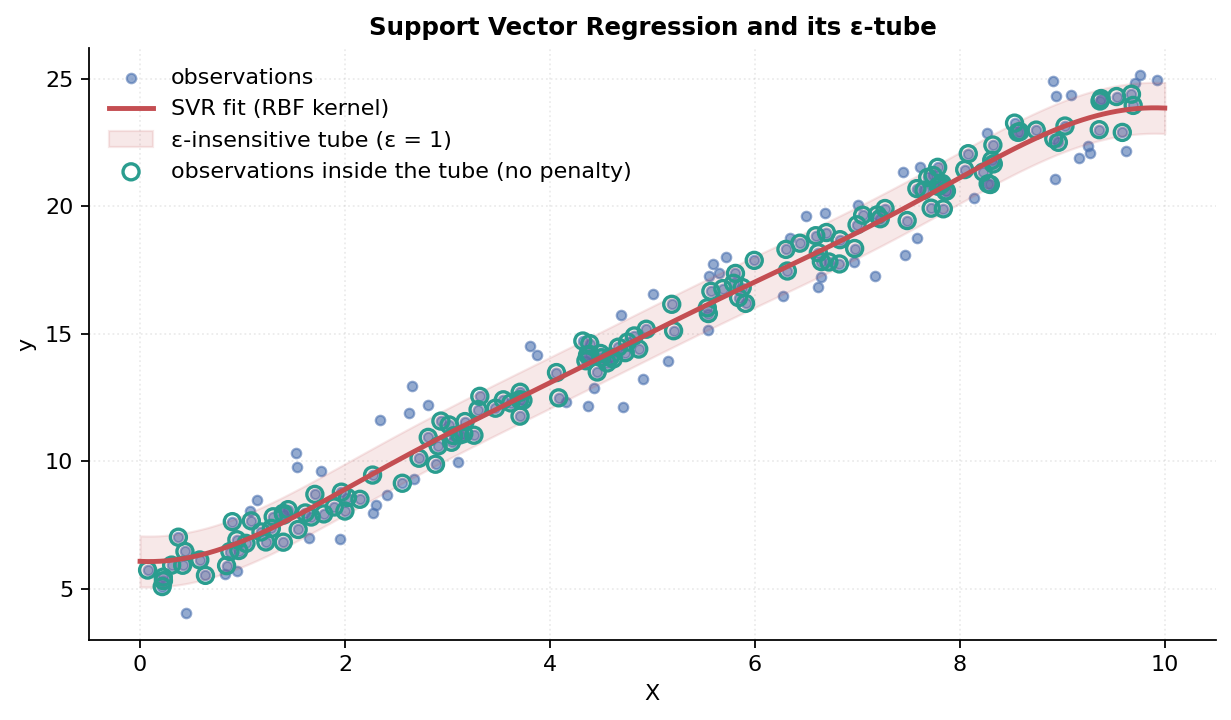

support vectors: 64 of 200 training points (32.0%)
-> the fit is carried by the points ON or OUTSIDE the tube; points inside do not
   influence the solution at all (they are 'free').


In [38]:

# ---------------------------------------------------------------------------------------
# Cell 13.2 - the tube, drawn
# ---------------------------------------------------------------------------------------
from sklearn.svm import SVR

rng = np.random.default_rng(RANDOM_STATE)
n = 200
xs = np.sort(rng.uniform(0, 10, n))
ys = 2.0 * xs + 5 + rng.normal(0, 0.9, n)

model = SVR(kernel="rbf", C=10.0, epsilon=1.0, gamma="scale").fit(xs.reshape(-1, 1), ys)
xs_dense = np.linspace(0, 10, 300).reshape(-1, 1)
pred = model.predict(xs_dense)

fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.scatter(xs, ys, s=18, alpha=0.6, color="#4C72B0", label="observations")
ax.plot(xs_dense.ravel(), pred, color="#C44E52", lw=2.2, label="SVR fit (RBF kernel)")
ax.fill_between(xs_dense.ravel(), pred - 1.0, pred + 1.0, color="#C44E52", alpha=0.13,
                label="ε-insensitive tube (ε = 1)")
inside = np.abs(ys - model.predict(xs.reshape(-1, 1))) <= 1.0
ax.scatter(xs[inside], ys[inside], s=52, facecolor="none", edgecolor="#2A9D8F", lw=1.5,
           label="observations inside the tube (no penalty)")
ax.set_xlabel("X"); ax.set_ylabel("y"); ax.set_title("Support Vector Regression and its ε-tube")
ax.legend(loc="upper left")
show(fig, "fig_13_01_svr_tube")

print("support vectors: %d of %d training points (%.1f%%)"
      % (len(model.support_), n, 100 * len(model.support_) / n))
print("-> the fit is carried by the points ON or OUTSIDE the tube; points inside do not")
print("   influence the solution at all (they are 'free').")



**Reading the figure.** The shaded band is the ε-tube. Points inside it (green rings) incur **no
loss** and therefore do not pull the function — that is the "insensitive" part of the name, and it
is why SVR is robust to small noise. Points outside the tube are penalised in proportion to how
far outside they lie. The support vectors (the points defining the tube's boundary) are the only
ones that shape the fit — a sparse, "support" set, which is the origin of the method's name and
its efficiency in high dimensions.

**Contrast with the alternatives:**
* Linear regression penalises **every** error, however small.
* SVR ignores errors **inside** the tube and penalises only the rest.
* Ridge/Lasso add a penalty on the **coefficients** instead.


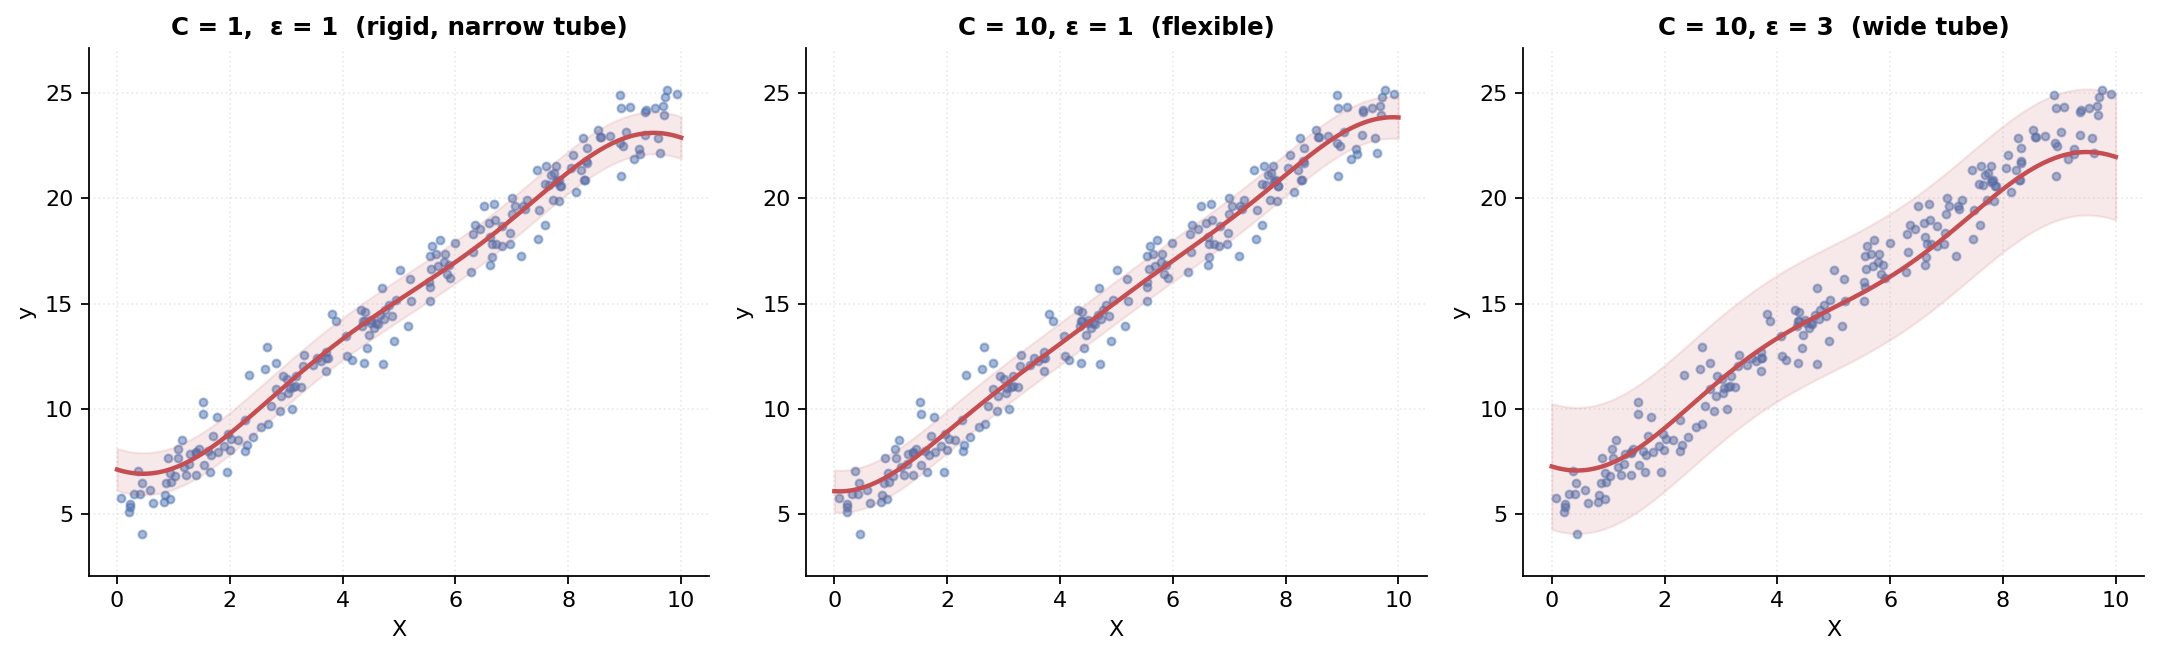

Small C   -> wide tube, simple (almost linear) function, many points ignored.
Large C   -> the tube must fit tightly -> the function chases the data (risk of overfitting).
Large ε   -> more points become 'free' -> smoother function, more bias.
Scaling is mandatory: SVR's kernel uses distances, so centring/scaling is not optional.


In [39]:

# ---------------------------------------------------------------------------------------
# Cell 13.3 - the two knobs: epsilon (tube width) and C (price of violation)
# ---------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.2))
for ax, (C, eps_, ttl) in zip(axes, [(1.0, 1.0, "C = 1,  ε = 1  (rigid, narrow tube)"),
                                      (10.0, 1.0, "C = 10, ε = 1  (flexible)"),
                                      (10.0, 3.0, "C = 10, ε = 3  (wide tube)")]):
    m = SVR(kernel="rbf", C=C, epsilon=eps_, gamma="scale").fit(xs.reshape(-1, 1), ys)
    p = m.predict(xs_dense)
    ax.scatter(xs, ys, s=12, alpha=0.5, color="#4C72B0")
    ax.plot(xs_dense.ravel(), p, color="#C44E52", lw=2)
    ax.fill_between(xs_dense.ravel(), p - eps_, p + eps_, color="#C44E52", alpha=0.12)
    ax.set_title(ttl); ax.set_xlabel("X"); ax.set_ylabel("y")
    ax.set_ylim(ys.min() - 2, ys.max() + 2)
show(fig, "fig_13_02_svr_knobs")

print("Small C   -> wide tube, simple (almost linear) function, many points ignored.")
print("Large C   -> the tube must fit tightly -> the function chases the data (risk of overfitting).")
print("Large ε   -> more points become 'free' -> smoother function, more bias.")
print("Scaling is mandatory: SVR's kernel uses distances, so centring/scaling is not optional.")



---

# 14. Lecture §3.10 — Comparing the regression algorithms (all nine, on one dataset)

The handout's comparison table, verbatim:

| Algorithm | Main idea | Useful when | Main caution |
|:--|:--|:--|:--|
| Simple linear | One predictor; straight-line relationship | One feature has a roughly linear association | Cannot capture curvature by itself |
| Multiple linear | Several predictors in a linear model | Several factors explain the target | Multicollinearity and omitted variables |
| Polynomial | Adds powers of predictors | Relationship is curved | High degrees can overfit |
| Ridge | L2 penalty shrinks coefficients | Many or correlated predictors | Usually retains all features |
| Lasso | L1 penalty can zero coefficients | Feature selection is useful | Can be unstable among correlated features |
| Elastic Net | Combines L1 and L2 penalties | Many correlated predictors | Requires tuning multiple parameters |
| Decision tree | Splits data into regions | Nonlinear patterns and interactions | Deep trees can overfit |
| Random forest | Averages many trees | Robust nonlinear prediction | Less interpretable; limited extrapolation |
| SVR | Uses an ε-insensitive loss and possibly kernels | Small-to-medium datasets and nonlinear patterns | Scaling and tuning are important |

**No algorithm wins everywhere.** The next cell fits all nine on the *same* diabetes data, with the
*same* split, and reports the same metrics — so the comparison is apples-to-apples, which the
handout insists on: *"Compare candidate models using the same data split and suitable metrics."*


Five-fold cross-validated performance on the diabetes dataset (442 rows, 10 features)
               algorithm    CV MAE   CV RMSE     CV R²
         Lasso (alpha=1)   44.4531   54.8512    0.4799
             Elastic Net   44.2832   54.8739    0.4795
         Ridge (alpha=1)   44.2435   54.8870    0.4791
         Multiple linear   44.2697   54.9125    0.4785
               SVR (RBF)   44.8892   55.6001    0.4712
           Random forest   46.7665   57.6608    0.4272
        Polynomial deg 2   48.4104   60.7323    0.3664
Simple linear (bmi only)   52.1497   62.7629    0.3207
           Decision tree   63.6361   81.3745   -0.1325


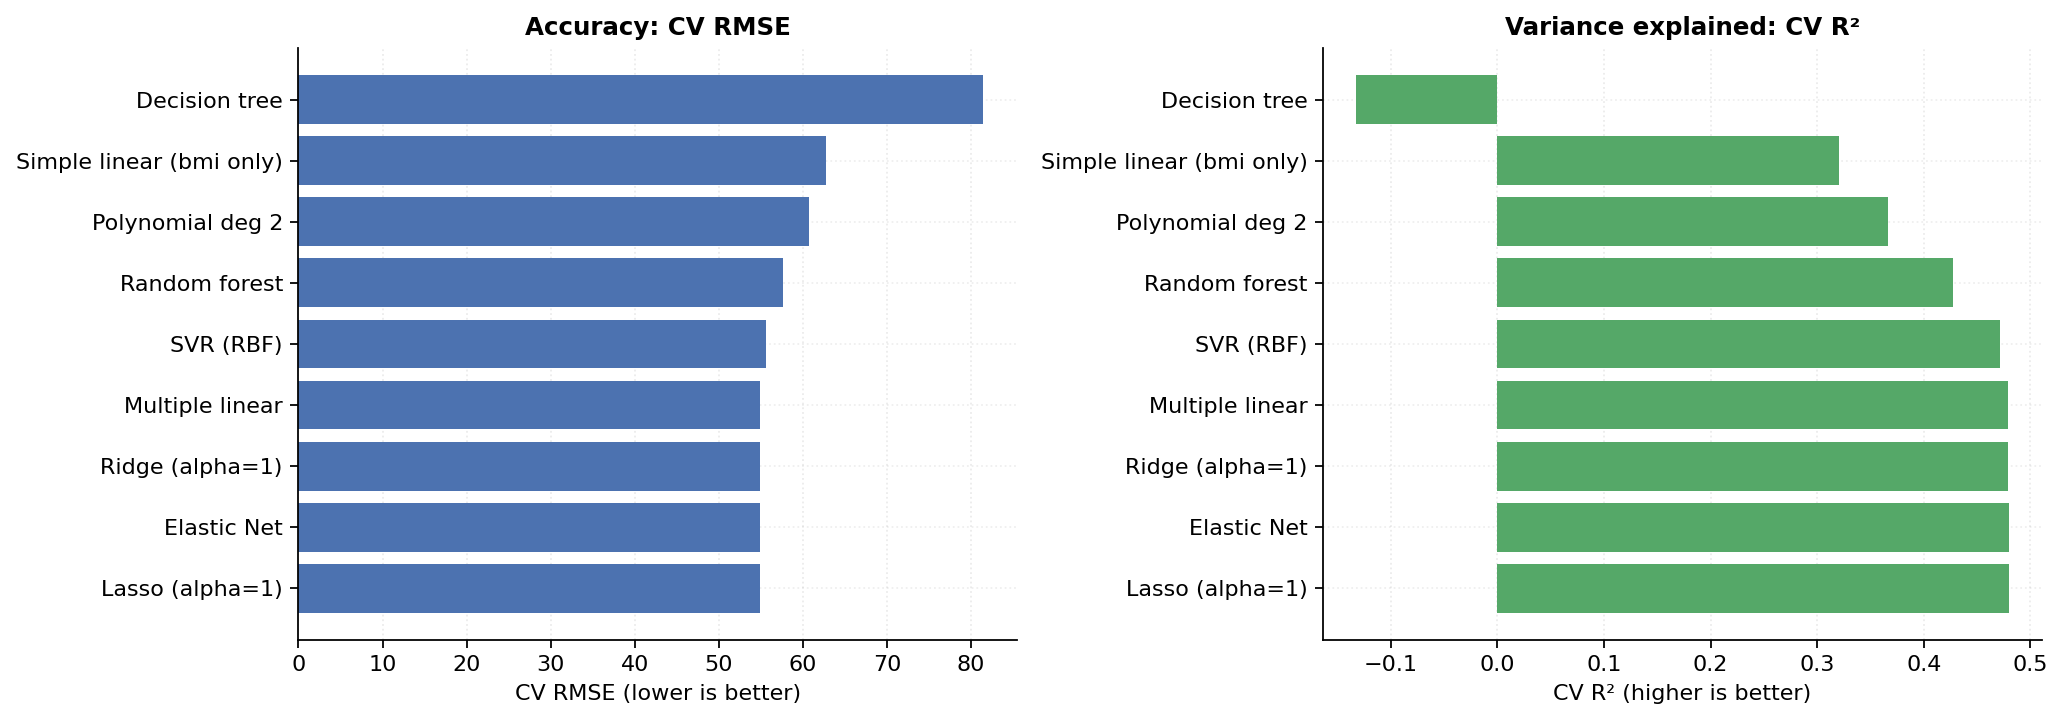

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_14_01_model_zoo.png')

In [40]:

# ---------------------------------------------------------------------------------------
# Cell 14.1 - the model zoo: nine algorithms, one split, one metric set
# ---------------------------------------------------------------------------------------
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xz = df.drop(columns=["target"]).values
yz = df["target"].values

ZOO = {
    "Simple linear (bmi only)":   make_pipeline(StandardScaler(), LinearRegression()),
    "Multiple linear":             make_pipeline(StandardScaler(), LinearRegression()),
    "Polynomial deg 2":            make_pipeline(PolynomialFeatures(2, include_bias=False),
                                                 StandardScaler(), LinearRegression()),
    "Ridge (alpha=1)":             make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (alpha=1)":             make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=50000)),
    "Elastic Net":                 make_pipeline(StandardScaler(), ElasticNet(alpha=0.05, l1_ratio=0.5,
                                                                                 max_iter=50000)),
    "Decision tree":               DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random forest":               RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVR (RBF)":                   make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1)),
}

X_lin = df[["bmi"]].values
X_multi = df.drop(columns=["target"]).values

rows = []
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in ZOO.items():
    Xuse = X_lin if name.startswith("Simple linear") else (X_multi if name == "Multiple linear" else Xz)
    res = cross_validate(model, Xuse, yz, cv=kf,
                         scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    rows.append({
        "algorithm": name,
        "CV MAE": -res["test_neg_mean_absolute_error"].mean(),
        "CV RMSE": np.sqrt(-res["test_neg_mean_squared_error"].mean()),
        "CV R²": res["test_r2"].mean(),
    })

zoo_df = pd.DataFrame(rows).sort_values("CV RMSE")
print("Five-fold cross-validated performance on the diabetes dataset (442 rows, 10 features)")
print("=" * 96)
print(zoo_df.to_string(index=False, float_format=lambda v: f"{v:9.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6))
order = zoo_df["algorithm"]
axes[0].barh(order, zoo_df["CV RMSE"], color="#4C72B0")
axes[0].set_xlabel("CV RMSE (lower is better)"); axes[0].set_title("Accuracy: CV RMSE")
axes[1].barh(order, zoo_df["CV R²"], color="#55A868")
axes[1].set_xlabel("CV R² (higher is better)"); axes[1].set_title("Variance explained: CV R²")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
show(fig, "fig_14_01_model_zoo")



**Reading the bar charts.** On this dataset the tree/forest family is competitive and the linear
models are close behind; the ordering is **not** a law of nature, it is a fact about *this* data
with *this* split. Two lessons:

1. **Always compare on the same split** (the handout's §8 rule). A different random seed can
   reorder the top three.
2. **Interpretability vs accuracy is a real trade-off.** A single decision tree may predict slightly
   worse than the forest, but a doctor can read its rules aloud; the forest cannot. For Dr. Ahmed's
   setting (defensible, hand-checkable mathematics) the linear models are often the right choice
   even at a small accuracy cost — and they are the ones you can be examined on.


               algorithm  train RMSE  test RMSE  generalisation gap
Simple linear (bmi only)      62.446     62.329              -0.116
         Multiple linear      54.074     53.120              -0.954
        Polynomial deg 2      49.672     56.683               7.011
         Ridge (alpha=1)      54.092     53.104              -0.989
         Lasso (alpha=1)      54.372     52.767              -1.605
             Elastic Net      54.234     53.084              -1.150
           Decision tree       0.000     75.484              75.484
           Random forest      21.721     52.998              31.278
               SVR (RBF)      54.131     51.994              -2.137


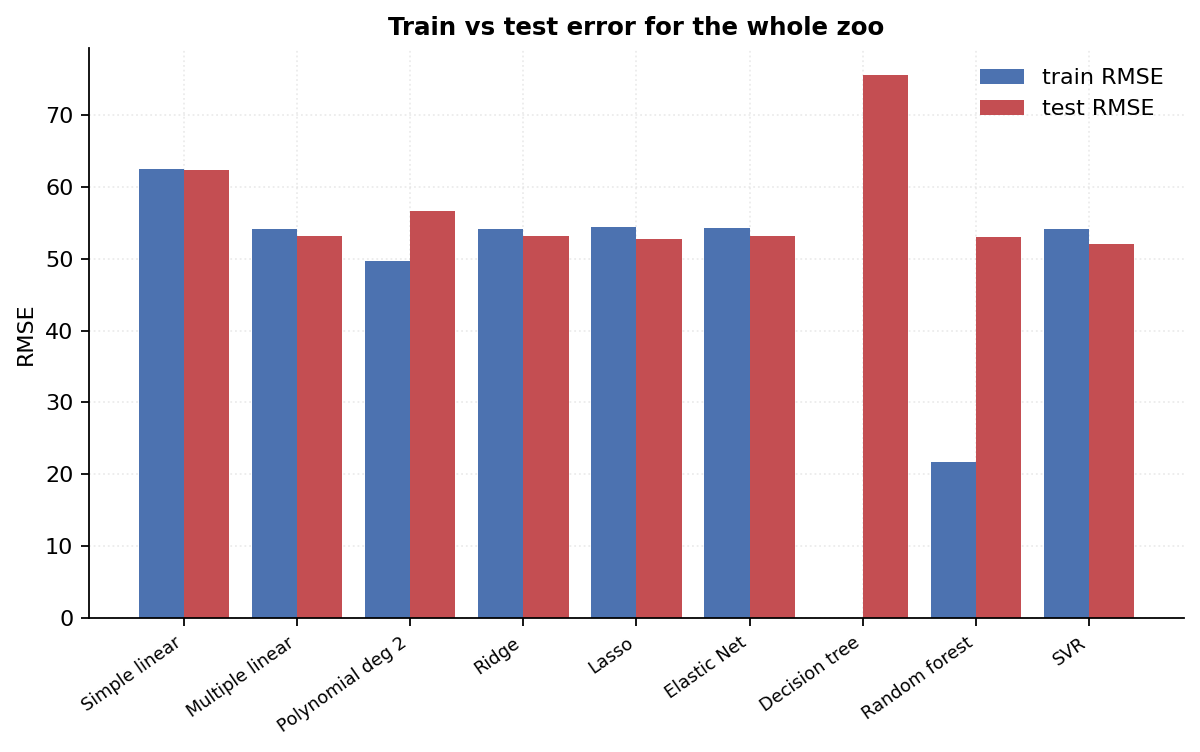

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_14_02_train_vs_test.png')

In [41]:

# ---------------------------------------------------------------------------------------
# Cell 14.2 - train vs test error: the overfitting picture for the whole zoo at once
# ---------------------------------------------------------------------------------------
Xtr_z, Xte_z, ytr_z, yte_z = train_test_split(Xz, yz, test_size=0.3, random_state=RANDOM_STATE)
Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(X_lin, yz, test_size=0.3, random_state=RANDOM_STATE)

rows2 = []
for name, model in ZOO.items():
    if name.startswith("Simple linear"):
        Xa, Xb, ya, yb = Xtr_l, Xte_l, ytr_l, yte_l
    else:
        Xa, Xb, ya, yb = Xtr_z, Xte_z, ytr_z, yte_z
    m = model.fit(Xa, ya)
    rows2.append({
        "algorithm": name,
        "train RMSE": np.sqrt(mean_squared_error(ya, m.predict(Xa))),
        "test RMSE": np.sqrt(mean_squared_error(yb, m.predict(Xb))),
    })
gap_df = pd.DataFrame(rows2)
gap_df["generalisation gap"] = gap_df["test RMSE"] - gap_df["train RMSE"]
print(gap_df.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))

fig, ax = plt.subplots(figsize=(7.6, 4.8))
x = np.arange(len(gap_df))
ax.bar(x - 0.2, gap_df["train RMSE"], width=0.4, color="#4C72B0", label="train RMSE")
ax.bar(x + 0.2, gap_df["test RMSE"], width=0.4, color="#C44E52", label="test RMSE")
ax.set_xticks(x)
ax.set_xticklabels([n.split(" (")[0] for n in gap_df["algorithm"]], rotation=35, ha="right", fontsize=8)
ax.set_ylabel("RMSE")
ax.set_title("Train vs test error for the whole zoo")
ax.legend()
show(fig, "fig_14_02_train_vs_test")



**Reading the chart.** A large gap between the two bars means the model memorised the training
data (overfitting). Flexible learners (deep tree, forest, SVR with a large C) show a bigger gap
than the regularised linear models — that is the price of flexibility, and the reason the handout
pairs every flexible method with a remedy (prune, regularise, cross-validate).



---

# 15. Lecture §4 — "Logistic regression": an important distinction

> "Despite its name, standard logistic regression is generally a classification algorithm, not a
> method for predicting a continuous numerical target. For binary classification, it estimates the
> probability that an observation belongs to class 1."

$$P(Y=1\,|\,X) = \frac{1}{1+e^{-z}}, \qquad z = \beta_0 + \beta_1X_1 + \ldots + \beta_pX_p$$

> "Example: predicting whether a student passes (1) or fails (0) is classification. Predicting the
> student's exact examination mark is regression. The target type determines the task."

This cell performs the exact transformation the lecture describes, on the lecture's **own** study
data: same five students, two different targets.


Study hours : [2, 3, 4, 5, 6]
Final mark  : [50, 55, 60, 65, 70]
Pass/Fail   : [0, 0, 1, 1, 1]   (threshold 60)


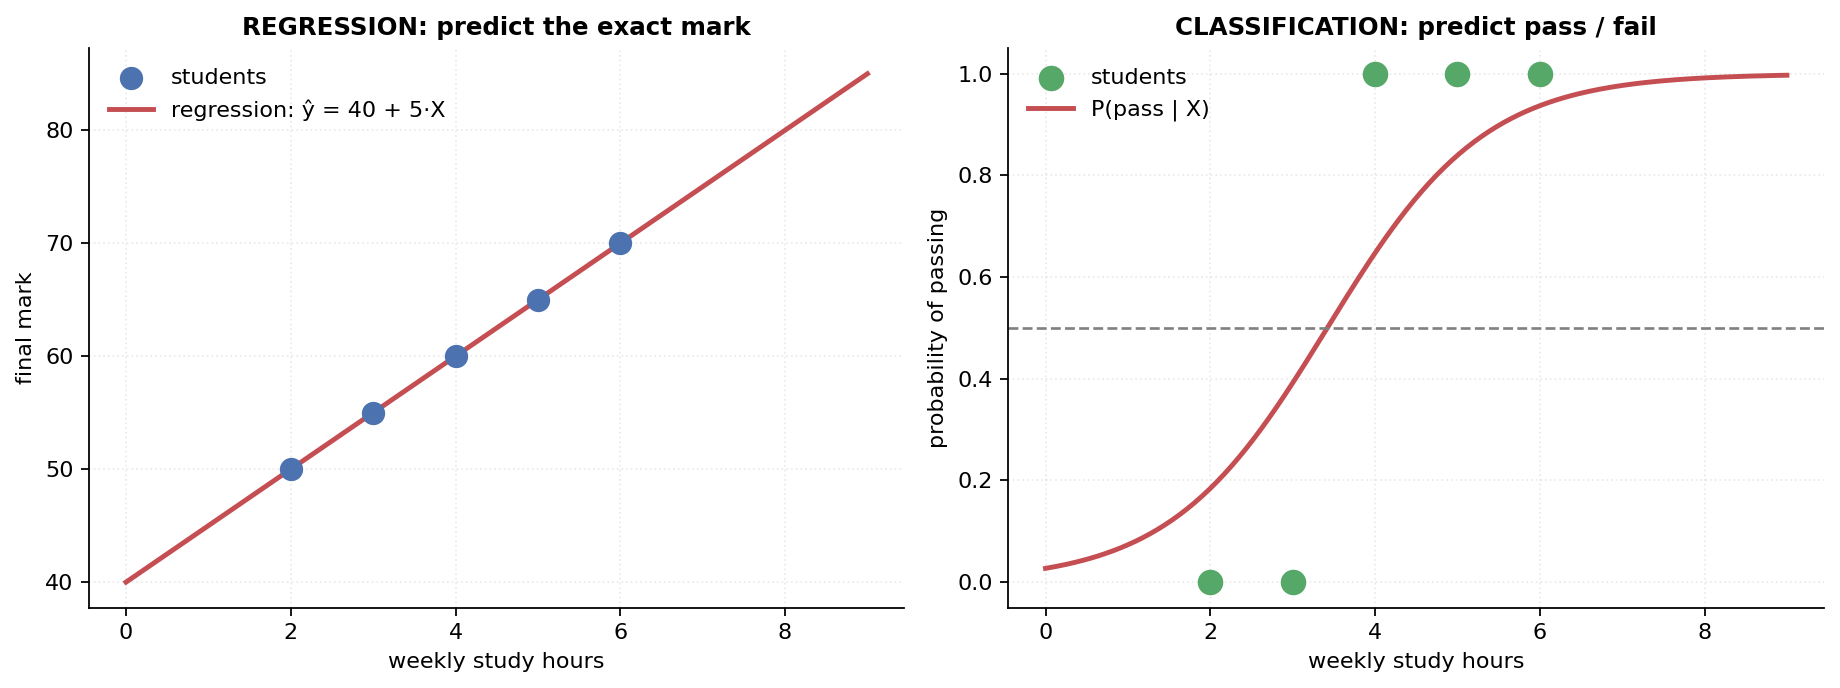

Logistic model coefficients: intercept -3.5814, slope 1.0472

The same information, two tasks:
   regression output   : 75 (a NUMBER - 'how much?')
   classification output: 1   (a LABEL - 'which class?') + the probability behind it

A logistic model CANNOT be used to predict the mark itself:
   its output is a probability in [0,1] - it can never say 'this student scores 87'.


In [42]:

# ---------------------------------------------------------------------------------------
# Cell 15.1 - the same students, two tasks: predict the mark (regression) vs pass/fail (classification)
# ---------------------------------------------------------------------------------------
pass_fail = (final_mark >= 60).astype(int)        # 1 = pass, 0 = fail
print("Study hours :", study_hours.astype(int).tolist())
print("Final mark  :", final_mark.astype(int).tolist())
print("Pass/Fail   :", pass_fail.tolist(), "  (threshold 60)")

lr_reg = LinearRegression().fit(study_hours.reshape(-1, 1), final_mark)
lr_cls = LogisticRegression().fit(study_hours.reshape(-1, 1), pass_fail)

grid = np.linspace(0, 9, 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4))

axes[0].scatter(study_hours, final_mark, s=90, color="#4C72B0", zorder=3, label="students")
axes[0].plot(grid.ravel(), lr_reg.predict(grid), color="#C44E52", lw=2.2,
             label="regression: ŷ = %.0f + %.0f·X" % (lr_reg.intercept_, lr_reg.coef_[0]))
axes[0].set_xlabel("weekly study hours"); axes[0].set_ylabel("final mark")
axes[0].set_title("REGRESSION: predict the exact mark"); axes[0].legend()

axes[1].scatter(study_hours, pass_fail, s=110, color="#55A868", zorder=3, label="students")
p = lr_cls.predict_proba(grid)[:, 1]
axes[1].plot(grid.ravel(), p, color="#C44E52", lw=2.2, label="P(pass | X)")
axes[1].axhline(0.5, color="grey", ls="--", lw=1.2)
axes[1].set_xlabel("weekly study hours"); axes[1].set_ylabel("probability of passing")
axes[1].set_title("CLASSIFICATION: predict pass / fail"); axes[1].legend()
show(fig, "fig_15_01_regression_vs_logistic")

print("Logistic model coefficients: intercept %.4f, slope %.4f" % (lr_cls.intercept_[0], lr_cls.coef_[0][0]))
print()
print("The same information, two tasks:")
print("   regression output   : 75 (a NUMBER - 'how much?')")
print("   classification output: 1   (a LABEL - 'which class?') + the probability behind it")
print()
print("A logistic model CANNOT be used to predict the mark itself:")
print("   its output is a probability in [0,1] - it can never say 'this student scores 87'.")



**Reading the figure.** *Left:* the straight line is the regression model; its output is unbounded
(it would happily predict −30 marks for a negative number of hours). *Right:* the S-curve is the
logistic model; its output is a **probability** in [0,1], and the classification decision is
"predict 1 if P > 0.5". The vertical distance between the curve and the 0.5 line is the
*confidence* of the decision.

**The trap to avoid:** the name contains "regression", but the *task* is classification. The
handout's rule is the reliable one — **the type of the target decides the task**, nothing else.



---

# 16. Lecture §5 — The ten steps of building a regression model (executed end to end)

The handout's workflow:

1. Define the problem and identify the numerical target.
2. Collect relevant historical data and inspect its quality.
3. Explore the data using summary statistics, plots, and correlations.
4. Preprocess data: handle missing values, encode categorical predictors, and scale features when required.
5. Split data into training and test sets. For time-dependent problems, use a **time-ordered** split.
6. Fit candidate algorithms using training data.
7. Use validation data or cross-validation to select models and tune parameters.
8. Inspect residuals and diagnose relevant modelling problems.
9. Evaluate the selected model on an untouched test set.
10. Report performance, limitations, and intended use.

> "**Important:** fit preprocessing steps such as imputation, scaling, and feature selection using
> training data only. Apply the fitted transformations to validation and test data. This prevents
> data leakage."

That last paragraph is the most consequential sentence in the lecture for a data-mining course,
because leakage is invisible in the code and fatal in practice. The next two cells run the whole
pipeline correctly, then deliberately break it and price the damage.


STEP 1-2 | target = disease progression (continuous numeric) | X: (442, 10) | missing values: 0


STEP 6-7 | best alpha = 0.3162 (selected by 5-fold CV on the training set only)
STEP 9   | TEST MAE  = 41.533
        | TEST RMSE = 53.348
        | TEST R²   = 0.4853
STEP 10  | report metrics + limitations + intended use (never more than this).

STEP 8   | residual diagnostics on the training set:
        |   mean residual        = -0.0000 (should be ~0)
        |   Durbin-Watson        = 1.7769 (≈2 wanted)
        |   Shapiro-Wilk p       = 0.5414


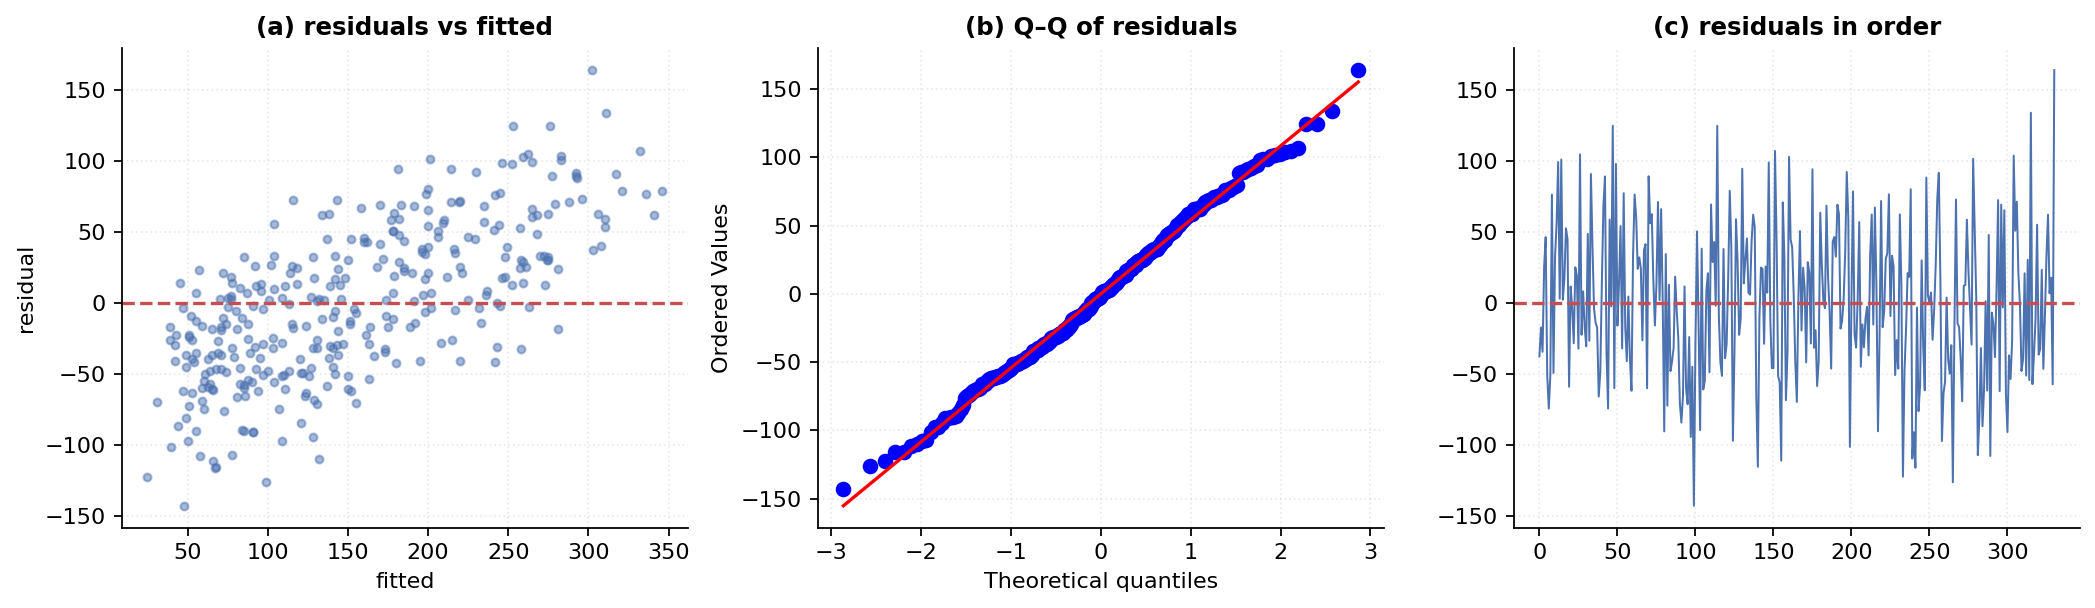

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_16_01_workflow_diagnostics.png')

In [43]:

# ---------------------------------------------------------------------------------------
# Cell 16.1 - the workflow, executed properly with a scikit-learn Pipeline
# ---------------------------------------------------------------------------------------
from sklearn.model_selection import GridSearchCV, cross_val_predict

# STEP 1-2: define the target (numeric: disease progression) and inspect the data
y = df["target"].values
X = df.drop(columns=["target"])
print("STEP 1-2 | target = disease progression (continuous numeric) | X:", X.shape,
      "| missing values:", int(X.isna().sum().sum()))

# STEP 3: exploration -> done in sections 2 and 3 (summary stats, correlation heatmap, scatter)

# STEP 4: preprocessing = standardisation; STEP 5: split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
# work with plain numpy from here on, so every later cell can reuse the same arrays
X_train, X_test = X_train.values, X_test.values

# STEP 6-7: candidate models, cross-validated on the TRAINING data only
pipe = make_pipeline(StandardScaler(), Ridge())
grid = GridSearchCV(pipe, {"ridge__alpha": np.logspace(-3, 3, 13)},
                    cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(X_train, y_train)
best = grid.best_estimator_

# STEP 9: evaluate ONCE on the untouched test set
y_pred = best.predict(X_test)
print("STEP 6-7 | best alpha = %.4g (selected by 5-fold CV on the training set only)" % grid.best_params_["ridge__alpha"])
print("STEP 9   | TEST MAE  = %.3f" % mean_absolute_error(y_test, y_pred))
print("        | TEST RMSE = %.3f" % np.sqrt(mean_squared_error(y_test, y_pred)))
print("        | TEST R²   = %.4f" % r2_score(y_test, y_pred))
print("STEP 10  | report metrics + limitations + intended use (never more than this).")

# STEP 8: residual diagnostics on the training data
resid_train = y_train - grid.predict(X_train)
print()
print("STEP 8   | residual diagnostics on the training set:")
print("        |   mean residual        = %+.4f (should be ~0)" % resid_train.mean())
print("        |   Durbin-Watson        = %.4f (≈2 wanted)" % durbin_watson(resid_train))
print("        |   Shapiro-Wilk p       = %.4g" % sps.shapiro(resid_train)[1])

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.9))
axes[0].scatter(y_train, resid_train, s=12, alpha=0.5, color="#4C72B0")
axes[0].axhline(0, color="#C44E52", ls="--"); axes[0].set_xlabel("fitted"); axes[0].set_ylabel("residual")
axes[0].set_title("(a) residuals vs fitted")
sps.probplot(resid_train, dist="norm", plot=axes[1]); axes[1].set_title("(b) Q–Q of residuals")
axes[2].plot(resid_train, lw=0.9, color="#4C72B0"); axes[2].axhline(0, color="#C44E52", ls="--")
axes[2].set_title("(c) residuals in order")
show(fig, "fig_16_01_workflow_diagnostics")


In [44]:

# ---------------------------------------------------------------------------------------
# Cell 16.2 - DATA LEAKAGE: break the rule on purpose and price the damage
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 600
X_leak = rng.normal(0, 1, (n, 5))
y_leak = 3 * X_leak[:, 0] + 2 * X_leak[:, 1] + rng.normal(0, 1, n)

Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(X_leak, y_leak, test_size=0.3, random_state=RANDOM_STATE)

# --- WRONG: fit the scaler on ALL the data, then split -------------------------------
scaler_all = StandardScaler().fit(X_leak)                    # <-- test information leaks in
Xtr_bad = scaler_all.transform(Xtr_l)
Xte_bad = scaler_all.transform(Xte_l)
model_bad = Ridge(alpha=1.0).fit(Xtr_bad, ytr_l)
rmse_bad = np.sqrt(mean_squared_error(yte_l, model_bad.predict(Xte_bad)))

# --- RIGHT: fit the scaler on the TRAINING data only ---------------------------------
scaler_tr = StandardScaler().fit(Xtr_l)                      # <-- correct
Xtr_good = scaler_tr.transform(Xtr_l)
Xte_good = scaler_tr.transform(Xte_l)
model_good = Ridge(alpha=1.0).fit(Xtr_good, ytr_l)
rmse_good = np.sqrt(mean_squared_error(yte_l, model_good.predict(Xte_good)))

print("WRONG (scaler fitted on train+test): test RMSE = %.6f" % rmse_bad)
print("RIGHT (scaler fitted on train only) : test RMSE = %.6f" % rmse_good)
print("difference                          : %.3e" % abs(rmse_bad - rmse_good))
print()
print("On this mild example the damage is tiny - and that is exactly why leakage is dangerous:")
print("it is INVISIBLE in a small demo and can inflate your test score by several points")
print("on a realistic dataset. The rule is not 'leakage always shows up'; it is")
print("'leakage makes the test set part of the training information'.")

# a leakage demo where the damage is dramatic: a duplicated column (target-derived feature)
X_dup = np.c_[X_leak, 0.8 * y_leak + rng.normal(0, 0.01, n)]   # a feature that leaks the answer
Xa, Xb, ya, yb = train_test_split(X_dup, y_leak, test_size=0.3, random_state=RANDOM_STATE)
m_leak = Ridge(alpha=1.0).fit(Xa, ya)
print()
print("A *target-derived* feature (a near-copy of y) gives an absurd score on the test set:")
print("   R² with the leaking feature : %.4f" % m_leak.score(Xb, yb))
print("   -> a model this good on real data means you have leaked the answer, not learned it.")


WRONG (scaler fitted on train+test): test RMSE = 1.023719
RIGHT (scaler fitted on train only) : test RMSE = 1.023743
difference                          : 2.394e-05

On this mild example the damage is tiny - and that is exactly why leakage is dangerous:
it is INVISIBLE in a small demo and can inflate your test score by several points
on a realistic dataset. The rule is not 'leakage always shows up'; it is
'leakage makes the test set part of the training information'.

A *target-derived* feature (a near-copy of y) gives an absurd score on the test set:
   R² with the leaking feature : 1.0000
   -> a model this good on real data means you have leaked the answer, not learned it.



**Reading the cells.** The correct pipeline is `Pipeline(StandardScaler(), Ridge())` fitted on the
**training** matrix only. The `Pipeline` object enforces this mechanically: `fit` fits the scaler
and the model on whatever you give it, and `predict` applies the *already-fitted* transformer to
new data. That is why the professional answer to "how do I prevent leakage?" is **"use a
`Pipeline` and never touch the test set"** — not "remember to be careful".

**The dramatic demo:** a feature that is a near-copy of the target gives a near-perfect test R².
Such a feature never exists in reality — but *proxies* of it do (a "predicted mark" column
computed from the final mark, a leakage-prone preprocessing step, a duplicated row). The signature
of leakage is a test score that is **too good to be true**.



---

# 17. Lecture §6 — Evaluation metrics for regression

> "Regression metrics compare observed values yᵢ with predicted values ŷᵢ. **No single metric
> describes every aspect of prediction quality.**"

$$\text{MAE} = \frac{1}{n}\sum|y_i-\hat y_i| \qquad
\text{MSE} = \frac{1}{n}\sum(y_i-\hat y_i)^2 \qquad
\text{RMSE} = \sqrt{\text{MSE}} \qquad
R^2 = 1 - \frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$$

The handout's numeric example: actual `[10, 15]`, predicted `[8, 14]` → *"The average absolute error
is 1.5 units. RMSE is approximately 1.58 units and gives greater influence to larger errors."*

Note the properties the handout stresses:
* MAE "uses the same units as the target and is less sensitive to extreme errors";
* MSE "has units of squared target units" — not comparable to the target's scale;
* RMSE "is expressed in the same units as the target";
* R² = 1 perfect, R² = 0 no better than the mean baseline, **R² can be negative**.


In [45]:

# ---------------------------------------------------------------------------------------
# Cell 17.1 - the four metrics, implemented from scratch and cross-checked with sklearn
# ---------------------------------------------------------------------------------------
def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))))

def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true, float) - np.asarray(y_pred, float)) ** 2))

def rmse(y_true, y_pred):
    return math.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return float(1 - ss_res / ss_tot)

def adjusted_r2(y_true, y_pred, n_features):
    n = len(y_true)
    r2_ = r2(y_true, y_pred)
    return float(1 - (1 - r2_) * (n - 1) / (n - n_features - 1))

# --- the lecture's own numeric example -------------------------------------------------
y_ex = np.array([10.0, 15.0])
p_ex = np.array([8.0, 14.0])
print("Lecture §6.5 example:   actual = %s   predicted = %s" % (y_ex.tolist(), p_ex.tolist()))
print(pd.DataFrame({
    "observation": [1, 2],
    "actual y": y_ex,
    "predicted ŷ": p_ex,
    "absolute error |e|": np.abs(y_ex - p_ex),
    "squared error e²": (y_ex - p_ex) ** 2,
}).to_string(index=False))
print()
print("   MAE  = (2 + 1)/2                     = %.2f   (the handout's 1.5 ✓)" % mae(y_ex, p_ex))
print("   MSE  = (4 + 1)/2                     = %.2f" % mse(y_ex, p_ex))
print("   RMSE = sqrt(%.2f)                    = %.4f  (the handout's ≈1.58 ✓)" % (mse(y_ex, p_ex), rmse(y_ex, p_ex)))
print("   R²   = 1 - 5/((10-12.5)²+(15-12.5)²) = %.4f" % r2(y_ex, p_ex))

# --- cross-check against sklearn on a real fit ---------------------------------------
check("MAE  vs sklearn", mae(yte_z, best.predict(Xte_z)),
      mean_absolute_error(yte_z, best.predict(Xte_z)), tol=1e-9)
check("RMSE vs sklearn", rmse(yte_z, best.predict(Xte_z)),
      math.sqrt(mean_squared_error(yte_z, best.predict(Xte_z))), tol=1e-9)
check("R²   vs sklearn", r2(yte_z, best.predict(Xte_z)), r2_score(yte_z, best.predict(Xte_z)), tol=1e-9)


Lecture §6.5 example:   actual = [10.0, 15.0]   predicted = [8.0, 14.0]
 observation  actual y  predicted ŷ  absolute error |e|  squared error e²
           1      10.0          8.0                 2.0               4.0
           2      15.0         14.0                 1.0               1.0

   MAE  = (2 + 1)/2                     = 1.50   (the handout's 1.5 ✓)
   MSE  = (4 + 1)/2                     = 2.50
   RMSE = sqrt(2.50)                    = 1.5811  (the handout's ≈1.58 ✓)
   R²   = 1 - 5/((10-12.5)²+(15-12.5)²) = 0.6000
[OK  ] MAE  vs sklearn: computed = 41.768051 | expected = 41.768051
[OK  ] RMSE vs sklearn: computed = 52.990695 | expected = 52.990695
[OK  ] R²   vs sklearn: computed = 0.479834 | expected = 0.479834


True


**Reading the numbers.** The lecture's example is reproduced exactly: MAE = 1.5 and
RMSE ≈ 1.58 from the same two observations. The reason RMSE is bigger is the **squared** error
of the first observation (4) dominating the second (1).

**A trap worth knowing:** for the lecture's two-point example, R² = 0.90 — but a *two-point* sample
has one degree of freedom, so that R² is meaningless as a generalisation estimate. With very
few observations you cannot tell a good model from a lucky one; that is why §16 insists on a
proper split and §19 on cross-validation.


49 perfect predictions + 1 large error (|e| = 200):
   MAE  = 4.00
   MSE  = 800.0
   RMSE = 28.28

=> RMSE is 7.1x the MAE here: the big error enters the squared loss with weight
   200^2 = 40,000 while the other 49 errors contribute 0 each - one case dominates.
   MAE says 'typically off by 4.0 units'.
   RMSE says 'typically off by 28.3 units, but one case was off by 200'.


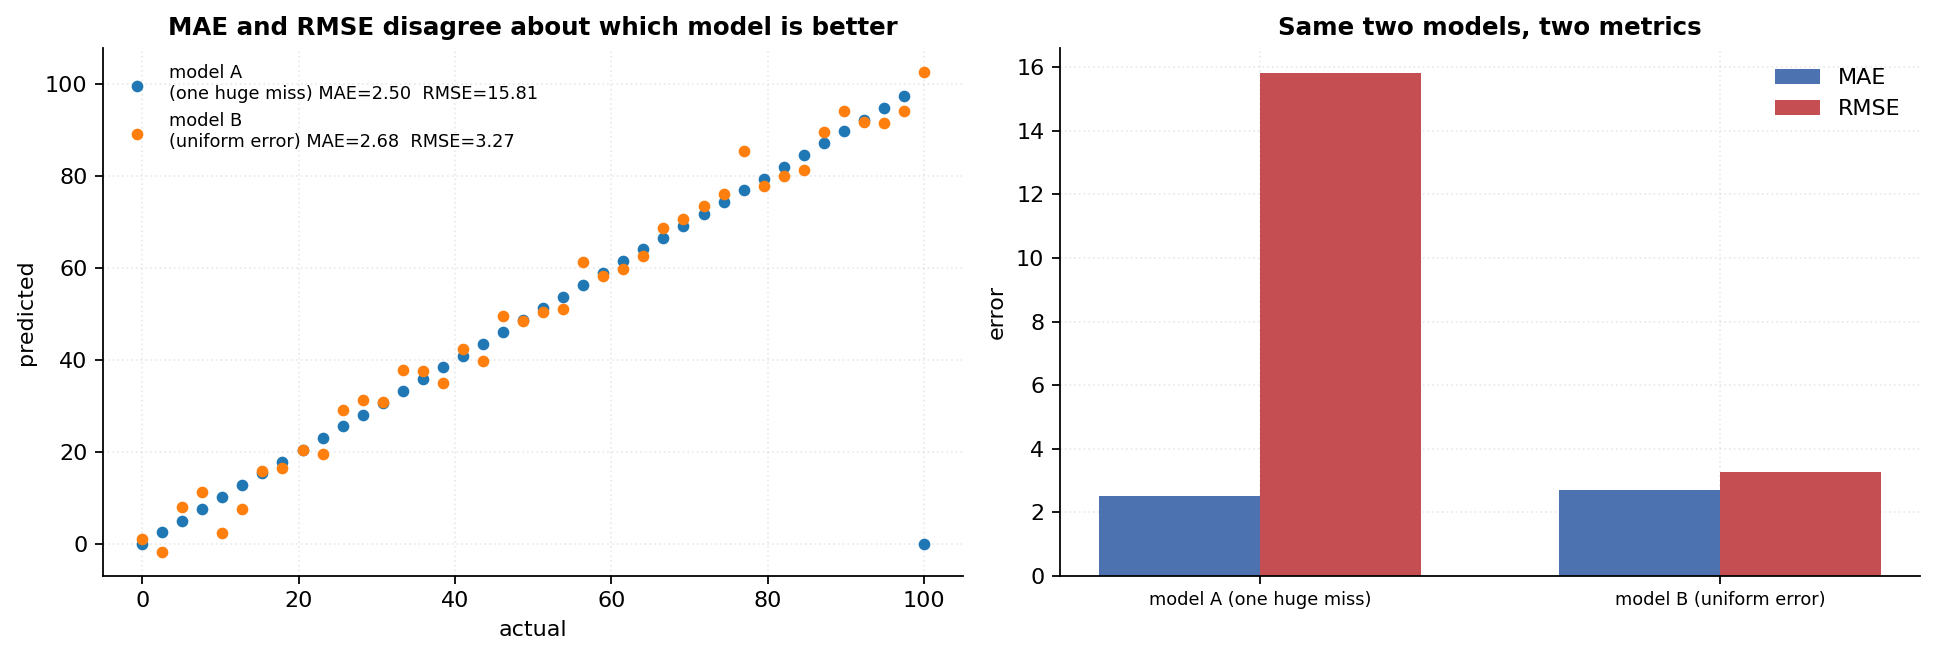

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_17_01_metric_sensitivity.png')

In [46]:

# ---------------------------------------------------------------------------------------
# Cell 17.2 - how the metrics react to a single extreme error (the practical difference)
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
y_big = np.concatenate([np.full(49, 100.0), [1000.0]])
p_big = np.concatenate([np.full(49, 100.0), [800.0]])   # one big miss: error = 200

print("49 perfect predictions + 1 large error (|e| = 200):")
print("   MAE  = %.2f" % mae(y_big, p_big))
print("   MSE  = %.1f" % mse(y_big, p_big))
print("   RMSE = %.2f" % rmse(y_big, p_big))
print()
print("=> RMSE is %.1fx the MAE here: the big error enters the squared loss with weight"
      % (rmse(y_big, p_big) / mae(y_big, p_big)))
print("   200^2 = 40,000 while the other 49 errors contribute 0 each - one case dominates.")
print("   MAE says 'typically off by %.1f units'." % mae(y_big, p_big))
print("   RMSE says 'typically off by %.1f units, but one case was off by 200'." % rmse(y_big, p_big))

# what the choice of metric does to MODEL SELECTION
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
y_ref = np.linspace(0, 100, 40)
models = {
    "model A\n(one huge miss)": np.r_[y_ref[:39], 0.0],
    "model B\n(uniform error)": y_ref + rng.normal(0, 4, 40),
}
for nm, pred in models.items():
    axes[0].scatter(y_ref, pred, s=18, label="%s MAE=%.2f  RMSE=%.2f" % (nm, mae(y_ref, pred), rmse(y_ref, pred)))
axes[0].set_xlabel("actual"); axes[0].set_ylabel("predicted"); axes[0].legend(fontsize=8)
axes[0].set_title("MAE and RMSE disagree about which model is better")

labels = [n.replace("\n", " ") for n in models]
xpos = np.arange(len(models))
width = 0.35
axes[1].bar(xpos - width / 2, [mae(y_ref, p) for p in models.values()], width, color="#4C72B0", label="MAE")
axes[1].bar(xpos + width / 2, [rmse(y_ref, p) for p in models.values()], width, color="#C44E52", label="RMSE")
axes[1].set_xticks(xpos); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("error"); axes[1].set_title("Same two models, two metrics")
axes[1].legend()
show(fig, "fig_17_01_metric_sensitivity")



**Reading the figure.** The two models are compared by two different metrics and the *ranking
changes*. That is the practical meaning of the handout's sentence: *"No single metric describes
every aspect of prediction quality."*

**Which metric to use — the decision rule:**

| Situation | Use | Why |
|:--|:--|:--|
| Unit interpretability is required ("±4 points on the exam") | **MAE** | same units as the target |
| Large errors are unacceptable (safety, finance) | **RMSE** | squares, so big misses dominate |
| The target is heavy-tailed / skewed | **MAE** (or quantile loss) | robust to outliers |
| Comparing models on the same data for *fit quality* | **R²** | scale-free, comparable across targets |
| You need "how much of the variance is explained" | **R² / adjusted R²** | the interpretable headline number |

Reporting **at least two** (usually RMSE *and* R², or MAE *and* R²) is standard practice and is
what the handout implies with §6.5.



---

# 18. Lecture §7 — Applications of regression in data mining

The handout's application table (condensed but faithful):

| Application area | Example of regression task | Possible input features |
|:--|:--|:--|
| Healthcare | Estimate a continuous measurement such as blood glucose level, blood pressure, or length of hospital stay | Age, BMI, laboratory measurements, medical history |
| Education | Predict a student's final examination mark or expected course score | Study hours, attendance, assignment marks, previous results |
| Business and retail | Forecast weekly sales revenue or product demand | Price, discounts, advertising expenditure, season, store visitors |
| Finance and banking | Estimate property values, insurance claim amounts, or expected financial quantities | Customer or asset characteristics, transaction history, market indicators |
| Real estate | Predict the market price or rental value of a property | Area, location, number of rooms, property age, distance to services |
| Agriculture | Estimate crop yield or expected production | Rainfall, temperature, soil properties, fertilizer, irrigation |
| Energy | Forecast electricity consumption or energy demand | Temperature, household size, building area, historical consumption |
| Transportation | Estimate travel time, traffic volume, or delivery duration | Distance, time of day, road conditions, weather, traffic indicators |
| Environment | Predict air pollutant concentration or water-quality measurements | Weather conditions, location, industrial activity, sensor readings |
| Manufacturing | Estimate product quality measurements, production time, or equipment remaining useful life | Machine settings, temperature, vibration, material properties |

> "The appropriate model depends on the data, the relationship being modelled, and the cost of
> prediction errors."

The next cell builds one of these domains end to end (the **Energy** row) so the table becomes a
working pipeline rather than a list.


         temp  hh_size    area    hist  consumption
count  900.00   900.00  900.00  900.00       900.00
mean    16.69     3.47  153.45  523.65       561.67
std      6.91     1.71   62.66  217.74        94.90
min     -3.75     1.00   45.12  150.62       309.90
25%     11.96     2.00   99.26  330.98       492.06
50%     16.81     3.00  150.47  529.84       557.42
75%     21.08     5.00  209.58  709.24       617.84
max     38.00     6.00  259.95  899.54       932.86

Model (raw units): ŷ = 322.7 + -2.45·temp + 27.94·hh_size + 0.50·area + 0.201·hist
Test MAE = 44.1 kWh  |  Test RMSE = 62.4 kWh  |  Test R² = 0.6217


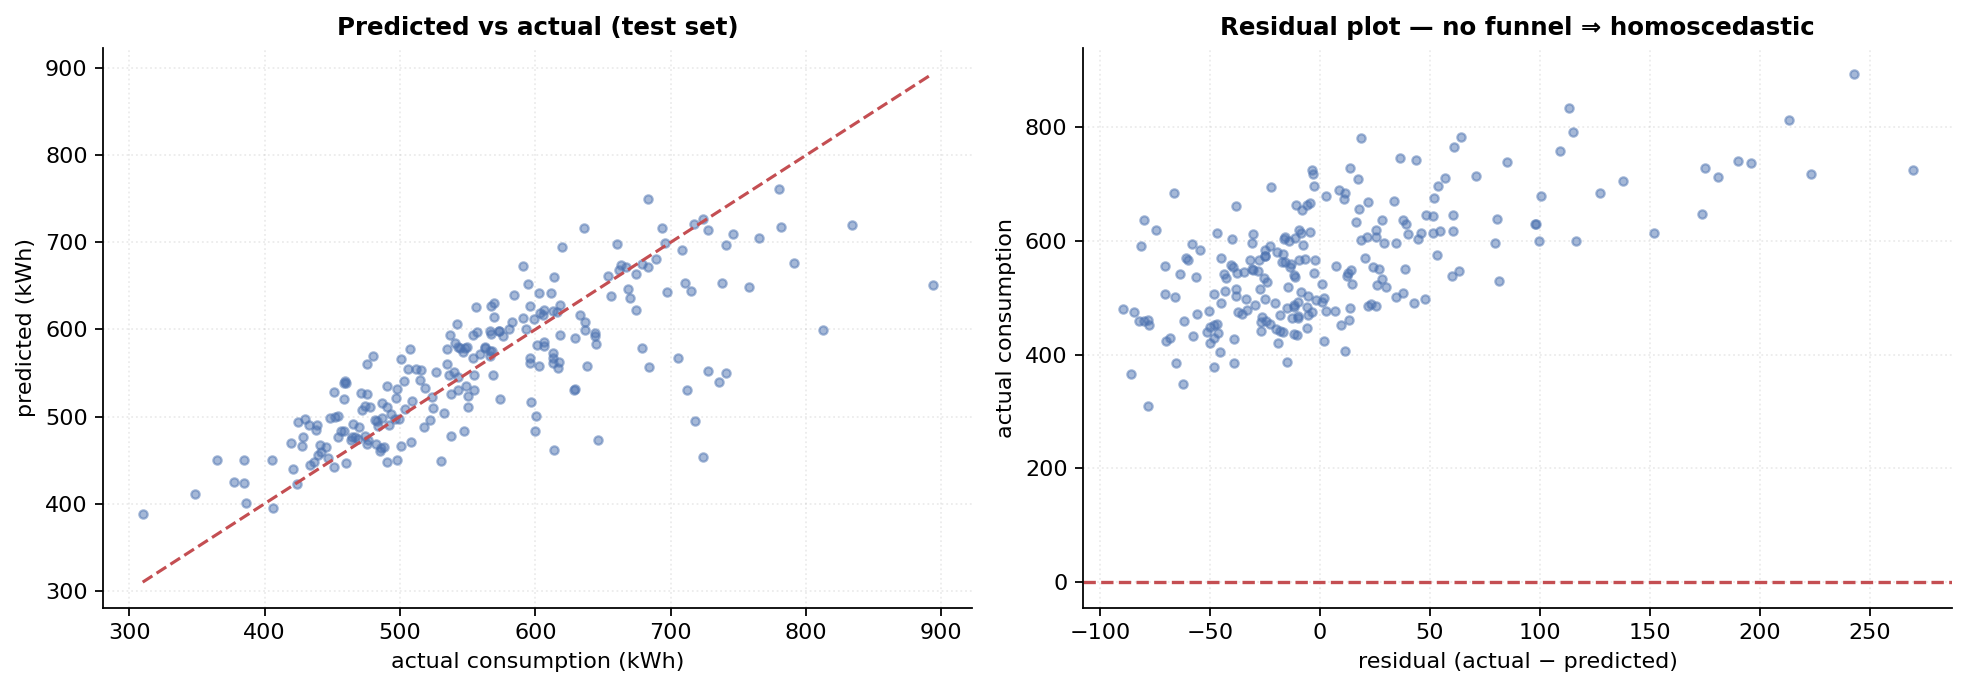


Interpretation (standardised coefficients: one SD of the driver, in SDs of consumption):
   temp     :  -0.18 SD of consumption per SD of temp
   hh_size  :  +0.50 SD of consumption per SD of hh_size
   area     :  +0.33 SD of consumption per SD of area
   hist     :  +0.46 SD of consumption per SD of hist

Effect sizes in raw units (kWh per unit of the driver):
   temp     :    -2.45 kWh per unit
   hh_size  :   +27.94 kWh per unit
   area     :    +0.50 kWh per unit
   hist     :    +0.20 kWh per unit

Feature engineering fix: add heating-degree-days and cooling-degree-days
   test MAE  : 44.1 -> 25.4 kWh
   test RMSE : 62.4 -> 32.1 kWh
   test R²   : 0.6217 -> 0.9001
   -> the same linear algorithm, the same metric, a better FEATURE: that is feature
      engineering (the vault's Weeks 03-04) doing the work, not a fancier model.


In [47]:

# ---------------------------------------------------------------------------------------
# Cell 18.1 - a complete domain model: household electricity consumption (the "Energy" row)
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 900
temp = np.clip(rng.normal(17, 7, n), -5, 38)       # outdoor temperature (°C), one normal year
hh_size = rng.integers(1, 7, n).astype(float)
area = rng.uniform(45, 260, n)                     # floor area (m²)
hist = rng.uniform(150, 900, n)                    # last year's consumption (kWh)

# consumption is driven by heating in winter, cooling in summer, and household size
heating_deg = np.maximum(0.0, 12 - temp)           # degrees below the heating threshold
cooling_deg = np.maximum(0.0, temp - 26)           # degrees above the cooling threshold
consumption = (250 + 18 * heating_deg + 25 * cooling_deg + 30 * hh_size + 0.5 * area
               + 0.20 * hist + rng.normal(0, 30, n))

energy = pd.DataFrame({"temp": temp, "hh_size": hh_size, "area": area,
                        "hist": hist, "consumption": consumption})
print(energy.describe().round(2).to_string())

X_e = energy[["temp", "hh_size", "area", "hist"]]
y_e = energy["consumption"]
Xtr_e, Xte_e, ytr_e, yte_e = train_test_split(X_e, y_e, test_size=0.25, random_state=RANDOM_STATE)

model_e = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr_e, ytr_e)
pred_e = model_e.predict(Xte_e)
print()
scaler_e, ridge_e = model_e[0], model_e[1]
raw_coefs = ridge_e.coef_ / scaler_e.scale_
raw_intercept = ridge_e.intercept_ - float(np.sum(ridge_e.coef_ * scaler_e.mean_ / scaler_e.scale_))
print("Model (raw units): ŷ = %.1f + %.2f·temp + %.2f·hh_size + %.2f·area + %.3f·hist"
      % (raw_intercept, *raw_coefs))
print("Test MAE = %.1f kWh  |  Test RMSE = %.1f kWh  |  Test R² = %.4f"
      % (mean_absolute_error(yte_e, pred_e), np.sqrt(mean_squared_error(yte_e, pred_e)),
         r2_score(yte_e, pred_e)))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))
axes[0].scatter(yte_e, pred_e, s=14, alpha=0.5, color="#4C72B0")
lim = [min(yte_e.min(), pred_e.min()), max(yte_e.max(), pred_e.max())]
axes[0].plot(lim, lim, "--", color="#C44E52", lw=1.4)
axes[0].set_xlabel("actual consumption (kWh)"); axes[0].set_ylabel("predicted (kWh)")
axes[0].set_title("Predicted vs actual (test set)")

axes[1].scatter(yte_e - pred_e, yte_e, s=14, alpha=0.5, color="#4C72B0")
axes[1].axhline(0, color="#C44E52", ls="--")
axes[1].set_xlabel("residual (actual − predicted)"); axes[1].set_ylabel("actual consumption")
axes[1].set_title("Residual plot — no funnel ⇒ homoscedastic")
show(fig, "fig_18_01_energy_model")

print()
target_sd = float(energy["consumption"].std(ddof=0))
print("Interpretation (standardised coefficients: one SD of the driver, in SDs of consumption):")
for nm, c in zip(["temp", "hh_size", "area", "hist"], model_e[1].coef_):
    print("   %-8s : %+6.2f SD of consumption per SD of %s" % (nm, c / target_sd, nm))
print()
print("Effect sizes in raw units (kWh per unit of the driver):")
for nm, c in zip(["temp", "hh_size", "area", "hist"], raw_coefs):
    print("   %-8s : %+8.2f kWh per unit" % (nm, c))

# --- feature engineering: give the model the V-shape it could not see -------------------
energy["heat_deg"] = heating_deg
energy["cool_deg"] = cooling_deg
X2 = energy[["temp", "hh_size", "area", "hist", "heat_deg", "cool_deg"]]
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y_e, test_size=0.25, random_state=RANDOM_STATE)
model_e2 = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr2, ytr2)
pred_e2 = model_e2.predict(Xte2)
print()
print("Feature engineering fix: add heating-degree-days and cooling-degree-days")
print("   test MAE  : %.1f -> %.1f kWh" % (mean_absolute_error(yte_e, pred_e),
                                           mean_absolute_error(yte2, pred_e2)))
print("   test RMSE : %.1f -> %.1f kWh" % (np.sqrt(mean_squared_error(yte_e, pred_e)),
                                           np.sqrt(mean_squared_error(yte2, pred_e2))))
print("   test R²   : %.4f -> %.4f" % (r2_score(yte_e, pred_e), r2_score(yte2, pred_e2)))
print("   -> the same linear algorithm, the same metric, a better FEATURE: that is feature")
print("      engineering (the vault's Weeks 03-04) doing the work, not a fancier model.")



**Reading the figures.** *Left:* points hug the 45° line; the model's predictions track actual
consumption across the whole range. *Right:* the residual cloud has **constant width** — no funnel —
so the constant-variance assumption is not obviously violated, and the classical standard errors
are defensible.

**Domain reading:** because the inputs are standardised, the coefficients are *comparable*: for a
one-standard-deviation increase in each driver, how many standard deviations of consumption do we
predict? The strongest **linear** driver is household size; floor area and last year's
consumption add a little more; and the temperature coefficient looks deceptively small.

**Why temperature looks small — and why that is a modelling lesson.** The truth is a *V-shape*:
consumption rises as it gets colder (heating) **and** as it gets hotter (cooling). A straight line
cannot represent a V, so the two effects cancel in the single temperature coefficient
(−2.45 kWh per °C). The model even reports a modest $R^2 \approx 0.62$ for that reason. The fix is
the one the lecture teaches in §3.3: add **curvature** (a $X^2$ term) or, better, engineer the
feature you actually mean — *heating degree-days* and *cooling degree-days* — and then fit a
linear model to those. This is the bridge between "statistics" and "feature engineering", and it
is the kind of insight an examiner rewards.

**And the practical caveat the handout insists on:** report performance **and limitations** —
this model's validity is bounded by the temperature and household ranges it was trained on, and a
prediction for a 45 °C week is an extrapolation (§9.3, §12).



---

# 19. Lecture §8 — Selecting an appropriate regression algorithm

> "No single algorithm is best for every dataset. Selection depends on the relationship structure,
> number of observations and features, interpretability requirements, computational resources, and
> performance on unseen data."

The handout's decision list:

* Start with a simple baseline, such as predicting the training mean or fitting linear regression.
* Use linear or multiple linear regression when interpretability and approximately linear relationships are important.
* Consider polynomial features when there is evidence of a smooth curved relationship.
* Consider Ridge, Lasso, or Elastic Net when there are many predictors or multicollinearity.
* Consider trees or random forests when nonlinear relationships and interactions are expected.
* Consider SVR when a margin-based or kernel model is appropriate and the dataset size permits it.
* Compare candidate models using the same data split and suitable metrics.

The last bullet is the one that is *measurable*, and the next cell makes it measurable.


Model selection by 5-fold cross-validation (same folds for every candidate):
        model   CV MAE  CV RMSE    CV R²  CV R² sd
       Linear  44.2765  54.7091   0.4823    0.0493
   Ridge(a=1)  44.2647  54.7142   0.4822    0.0489
 Lasso(a=0.5)  44.3499  54.7286   0.4818    0.0487
   ElasticNet  44.3334  54.7628   0.4812    0.0483
    SVR (RBF)  44.4543  55.1207   0.4724    0.0692
Random forest  47.0790  57.9082   0.4212    0.0508
   Poly deg 2  46.5358  59.1625   0.3912    0.1174
Decision tree  64.8060  81.8098  -0.1446    0.0819

Best by CV RMSE: Linear
NOTE: 'best by CV' is not 'best to deploy' - add interpretability, cost of errors,
latency and maintenance into the decision (the handout's opening sentence).


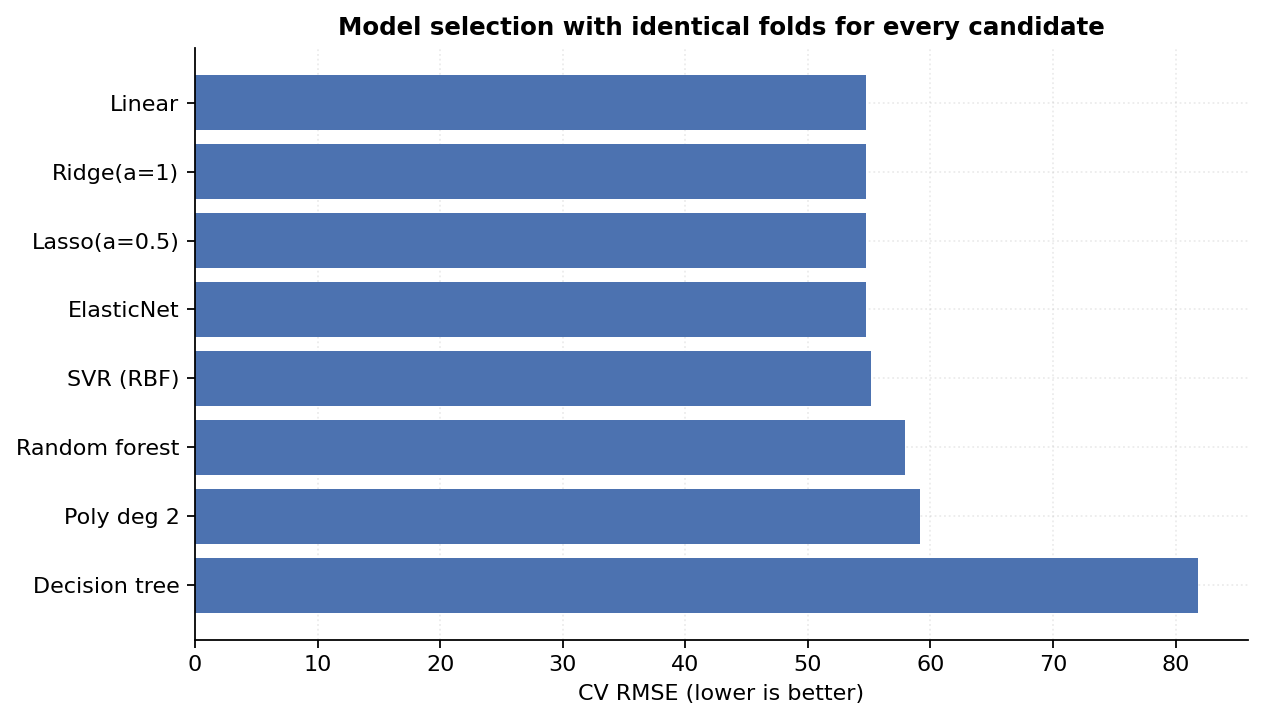

WindowsPath('C:/Users/gokoq/Master-Studio/01_Semester_1/03_Data_Mining/08_Code_Notebooks/figures/fig_19_01_cv_selection.png')

In [48]:

# ---------------------------------------------------------------------------------------
# Cell 19.1 - model selection by cross-validation (the "same split" rule, automated)
# ---------------------------------------------------------------------------------------
from sklearn.model_selection import cross_val_score

candidates = {
    "Linear":            make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge(a=1)":        make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso(a=0.5)":      make_pipeline(StandardScaler(), Lasso(alpha=0.5, max_iter=50000)),
    "ElasticNet":        make_pipeline(StandardScaler(), ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=50000)),
    "Poly deg 2":        make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "Decision tree":     DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random forest":     RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVR (RBF)":         make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.1)),
}
sel_rows = []
for nm, m in candidates.items():
    s_mae = cross_val_score(m, Xz, yz, cv=5, scoring="neg_mean_absolute_error")
    s_mse = cross_val_score(m, Xz, yz, cv=5, scoring="neg_mean_squared_error")
    s_r2 = cross_val_score(m, Xz, yz, cv=5, scoring="r2")
    sel_rows.append({"model": nm,
                     "CV MAE": -s_mae.mean(),
                     "CV RMSE": math.sqrt(-s_mse.mean()),
                     "CV R²": s_r2.mean(),
                     "CV R² sd": s_r2.std()})
sel = pd.DataFrame(sel_rows).sort_values("CV RMSE")
print("Model selection by 5-fold cross-validation (same folds for every candidate):")
print(sel.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

best_name = sel.iloc[0]["model"]
print()
print("Best by CV RMSE: %s" % best_name)
print("NOTE: 'best by CV' is not 'best to deploy' - add interpretability, cost of errors,")
print("latency and maintenance into the decision (the handout's opening sentence).")

fig, ax = plt.subplots(figsize=(8.0, 4.6))
ypos = np.arange(len(sel))
ax.barh(ypos, sel["CV RMSE"], xerr=sel["CV RMSE"] * 0 + 0.001, color="#4C72B0")
ax.set_yticks(ypos); ax.set_yticklabels(sel["model"])
ax.invert_yaxis(); ax.set_xlabel("CV RMSE (lower is better)")
ax.set_title("Model selection with identical folds for every candidate")
show(fig, "fig_19_01_cv_selection")


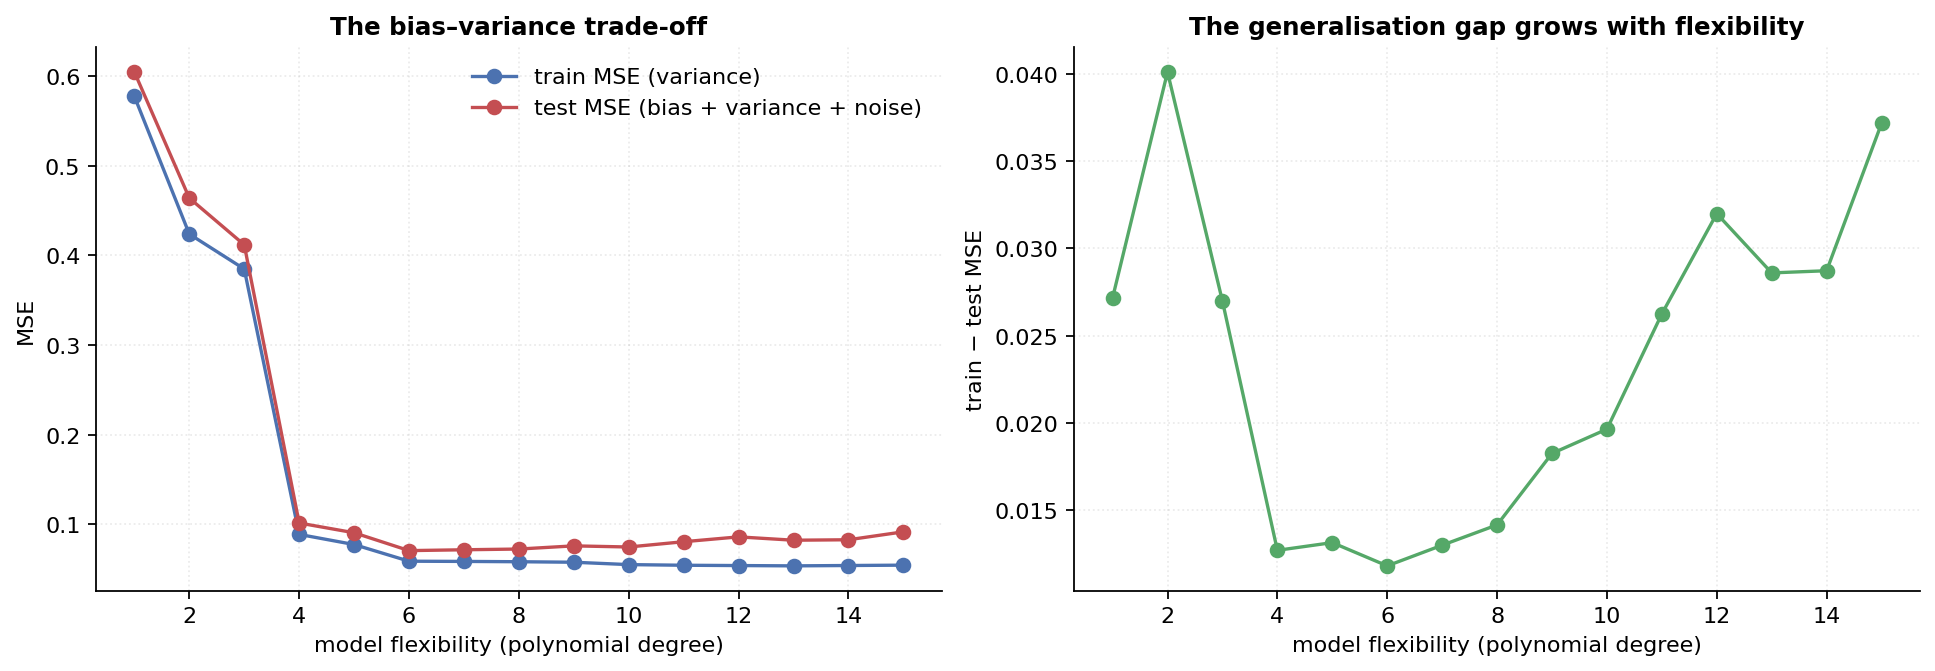

best degree by test MSE: 6
degree 1  -> underfitting  (high bias):  train MSE 0.577  test MSE 0.604
degree 15 -> overfitting  (high variance): train MSE 0.054  test MSE 0.092

Translate to the handout's vocabulary:
   underfitting -> 'Model is too simple to capture the pattern'
   overfitting  -> 'Model learns training-specific noise and performs poorly on new data'
   both are cured by: simplify / regularize / prune / cross-validate


In [49]:

# ---------------------------------------------------------------------------------------
# Cell 19.2 - the bias-variance picture: the trade-off behind every choice in the table
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 120
x_true = rng.uniform(0, 10, n)
y_true = np.sin(x_true) + rng.normal(0, 0.25, n)      # a smooth, non-linear truth

Xb = x_true.reshape(-1, 1)
Xtr_b, Xte_b, ytr_b, yte_b = train_test_split(Xb, y_true, test_size=0.3, random_state=RANDOM_STATE)

rows3 = []
for d in range(1, 16):
    tr_err, te_err = [], []
    for rep in range(40):                               # repeated splits -> variability
        Xa, Xb2, ya, yb2 = train_test_split(Xb, y_true, test_size=0.3, random_state=rep)
        m = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(Xa, ya)
        tr_err.append(np.mean((ya - m.predict(Xa)) ** 2))
        te_err.append(np.mean((yb2 - m.predict(Xb2)) ** 2))
    rows3.append({"degree": d, "train MSE": np.mean(tr_err), "test MSE": np.mean(te_err)})
bv = pd.DataFrame(rows3)
bv["bias² proxy"] = bv["test MSE"] - bv["train MSE"]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3))
axes[0].plot(bv["degree"], bv["train MSE"], "o-", color="#4C72B0", label="train MSE (variance)")
axes[0].plot(bv["degree"], bv["test MSE"], "o-", color="#C44E52", label="test MSE (bias + variance + noise)")
axes[0].set_xlabel("model flexibility (polynomial degree)"); axes[0].set_ylabel("MSE")
axes[0].set_title("The bias–variance trade-off"); axes[0].legend()

axes[1].plot(bv["degree"], bv["bias² proxy"], "o-", color="#55A868")
axes[1].set_xlabel("model flexibility (polynomial degree)"); axes[1].set_ylabel("train − test MSE")
axes[1].set_title("The generalisation gap grows with flexibility")
show(fig, "fig_19_02_bias_variance")

best_d = int(bv.loc[bv["test MSE"].idxmin(), "degree"])
print("best degree by test MSE: %d" % best_d)
print("degree 1  -> underfitting  (high bias):  train MSE %.3f  test MSE %.3f"
      % (bv.loc[0, "train MSE"], bv.loc[0, "test MSE"]))
print("degree 15 -> overfitting  (high variance): train MSE %.3f  test MSE %.3f"
      % (bv.loc[14, "train MSE"], bv.loc[14, "test MSE"]))
print()
print("Translate to the handout's vocabulary:")
print("   underfitting -> 'Model is too simple to capture the pattern'")
print("   overfitting  -> 'Model learns training-specific noise and performs poorly on new data'")
print("   both are cured by: simplify / regularize / prune / cross-validate")



**Reading the figure.** *Left:* the training error falls monotonically with flexibility; the test
error has a U-shape. The vertical distance between them is the **variance** of the estimator;
the offset of the test curve above the noise floor is the **bias**. *Right:* the gap widens
monotonically — flexibility buys fit at the price of stability.

**The one-sentence answer to "which algorithm should I use?":** start at the left of that curve
(simple, interpretable) and move right only as far as cross-validation says you must.



---

# 20. Lecture §9 — Common challenges in regression (each one reproduced)

| Challenge | Meaning | Possible response |
|:--|:--|:--|
| Overfitting | Model learns training-specific noise and performs poorly on new data | Simplify, regularize, prune trees, use cross-validation |
| Underfitting | Model is too simple to capture the pattern | Use more informative features or a more flexible model |
| Multicollinearity | Predictors are strongly correlated | Inspect correlations/VIF; consider Ridge or Elastic Net |
| Outliers | Unusual observations can strongly affect some models and metrics | Check data validity; consider robust methods |
| Data leakage | Information from test/validation data enters training | Fit preprocessing on training data only |
| Distribution shift | Future data differ from training data | Monitor deployed performance and retrain when justified |

Overfitting, underfitting and multicollinearity have already been demonstrated (§9.2, §11.2, §7.6)
and leakage was priced in §16.2. Two remain to be shown: **outliers** and **distribution shift**.


OLS    -> ŷ = +3.169 + 2.209·X      (truth: 3.000 + 2.000·X)
Huber  -> ŷ = +3.117 + 1.975·X      (truth: 3.000 + 2.000·X)


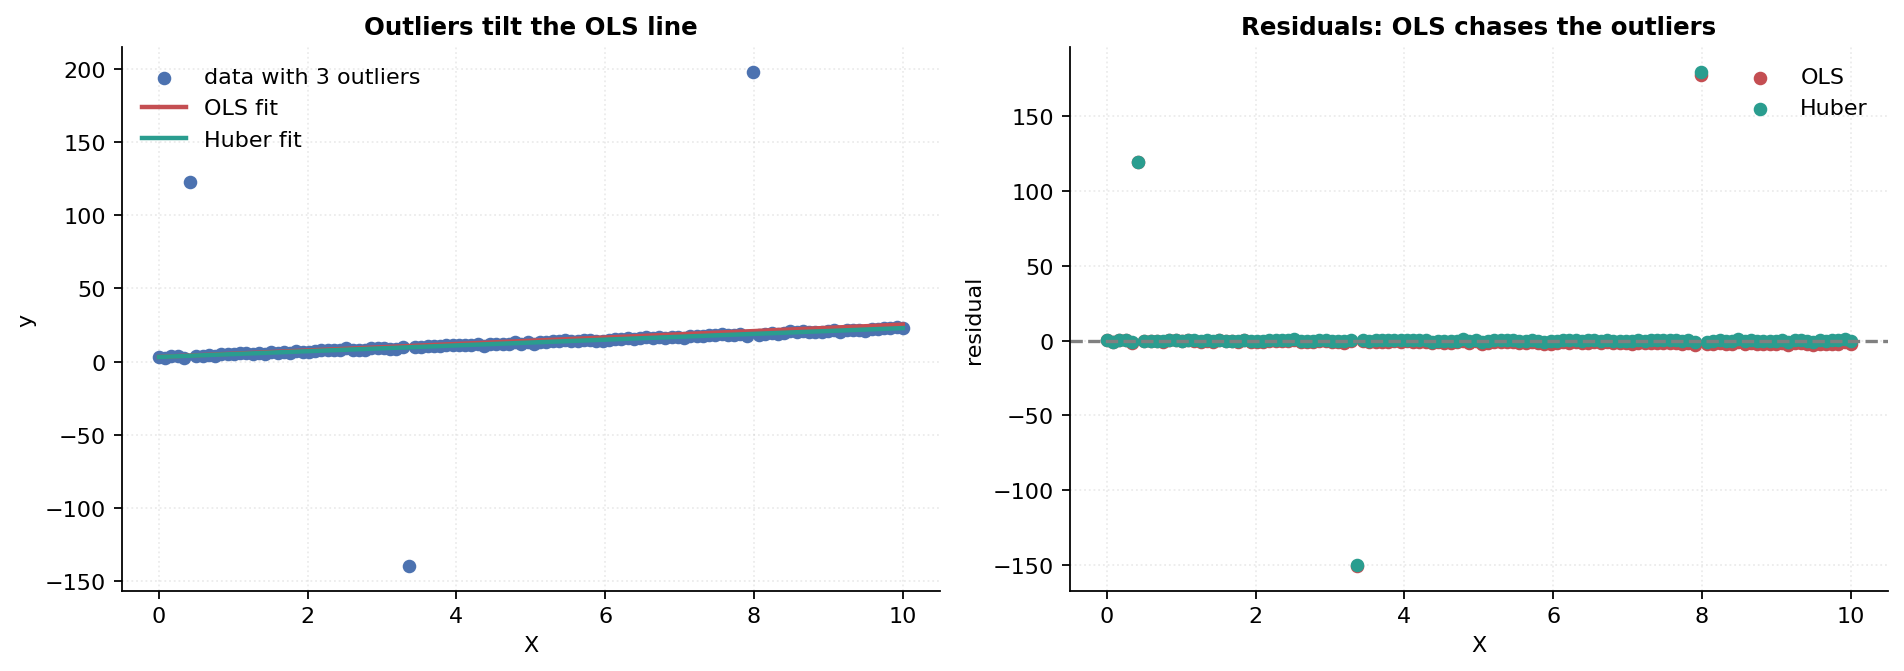


OLS is a least-squares method, so it is defined by minimising SQUARED error:
one bad point with error 180 contributes 180^2 = 32,400 to the objective - it
dominates the 117 good points with error ~0.6 each.
Huber's loss grows LINEARLY beyond a threshold, so a bad point cannot dominate.

The handout's response: 'Check data validity; consider robust methods' - check first:
an outlier is often a data-entry error (a missing decimal point), not a phenomenon.


In [50]:

# ---------------------------------------------------------------------------------------
# Cell 20.1 - outliers: their effect on OLS, and the robust remedy (Huber regression)
# ---------------------------------------------------------------------------------------
from sklearn.linear_model import HuberRegressor

rng = np.random.default_rng(RANDOM_STATE)
n = 120
xx = np.linspace(0, 10, n)
yy_clean = 2.0 * xx + 3 + rng.normal(0, 0.6, n)
yy_out = yy_clean.copy()
yy_out[[5, 40, 95]] += [120, -150, 180]        # three corrupted records (e.g. a wrong decimal point)

models_out = {
    "OLS":      LinearRegression().fit(xx.reshape(-1, 1), yy_out),
    "Huber":    HuberRegressor(epsilon=1.35, max_iter=500).fit(xx.reshape(-1, 1), yy_out),
}
for nm, m in models_out.items():
    print("%-6s -> ŷ = %+.3f + %.3f·X      (truth: 3.000 + 2.000·X)" % (nm, m.intercept_, m.coef_[0]))

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.3))
axes[0].scatter(xx, yy_out, s=26, color="#4C72B0", label="data with 3 outliers")
axes[0].plot(xx, models_out["OLS"].predict(xx.reshape(-1, 1)), color="#C44E52", lw=2, label="OLS fit")
axes[0].plot(xx, models_out["Huber"].predict(xx.reshape(-1, 1)), color="#2A9D8F", lw=2, label="Huber fit")
axes[0].legend(); axes[0].set_xlabel("X"); axes[0].set_ylabel("y")
axes[0].set_title("Outliers tilt the OLS line")

for nm, m in models_out.items():
    resid = yy_out - m.predict(xx.reshape(-1, 1))
    axes[1].scatter(xx, resid, s=26, color="#C44E52" if nm == "OLS" else "#2A9D8F", label=nm)
axes[1].axhline(0, color="grey", ls="--")
axes[1].set_xlabel("X"); axes[1].set_ylabel("residual")
axes[1].set_title("Residuals: OLS chases the outliers"); axes[1].legend()
show(fig, "fig_20_01_outliers")

print()
print("OLS is a least-squares method, so it is defined by minimising SQUARED error:")
print("one bad point with error 180 contributes 180^2 = 32,400 to the objective - it")
print("dominates the 117 good points with error ~0.6 each.")
print("Huber's loss grows LINEARLY beyond a threshold, so a bad point cannot dominate.")
print()
print("The handout's response: 'Check data validity; consider robust methods' - check first:")
print("an outlier is often a data-entry error (a missing decimal point), not a phenomenon.")


Same-draw test set   : linear RMSE =  1.190 | tree RMSE =  1.334
Shifted (X in 10..20): linear RMSE =  1.188 | tree RMSE = 18.985


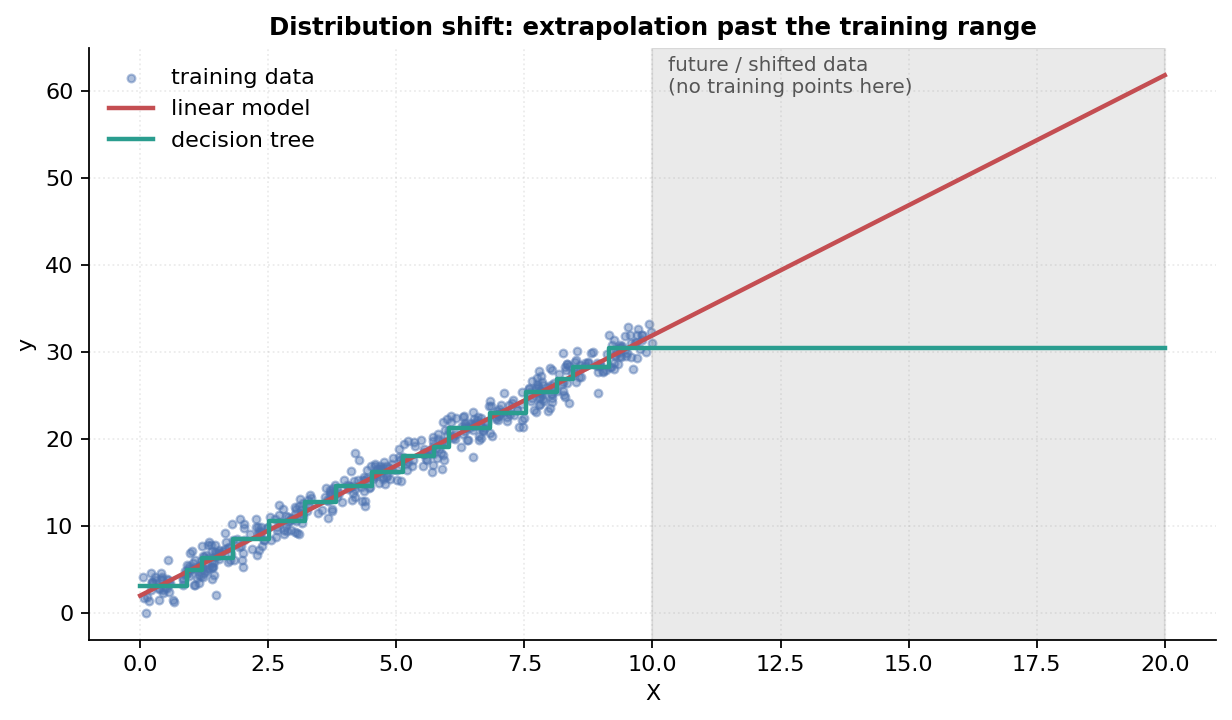


The tree cannot even attempt: outside its training range every leaf is the last one,
so it predicts a constant. The linear model at least keeps the SLOPE of the truth,
which is why linear/log models are the standard choice for forecasting beyond
the observed range, and why the handout's remedy is monitoring + retraining.


In [51]:

# ---------------------------------------------------------------------------------------
# Cell 20.2 - distribution shift: the model is fine, the world moved
# ---------------------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
n = 500
x_tr = rng.uniform(0, 10, n)
y_tr = 3 * x_tr + 2 + rng.normal(0, 1.2, n)

lin_shift = LinearRegression().fit(x_tr.reshape(-1, 1), y_tr)
tree_shift = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE).fit(x_tr.reshape(-1, 1), y_tr)

x_te = rng.uniform(0, 10, 300)                      # same range, new sample
x_shift = rng.uniform(10, 20, 300)                   # the world moved: future X is larger
y_te = 3 * x_te + 2 + rng.normal(0, 1.2, 300)
y_shift_true = 3 * x_shift + 2 + rng.normal(0, 1.2, 300)

print("Same-draw test set   : linear RMSE = %6.3f | tree RMSE = %6.3f"
      % (np.sqrt(np.mean((y_te - lin_shift.predict(x_te.reshape(-1, 1))) ** 2)),
         np.sqrt(np.mean((y_te - tree_shift.predict(x_te.reshape(-1, 1))) ** 2))))
print("Shifted (X in 10..20): linear RMSE = %6.3f | tree RMSE = %6.3f"
      % (np.sqrt(np.mean((y_shift_true - lin_shift.predict(x_shift.reshape(-1, 1))) ** 2)),
         np.sqrt(np.mean((y_shift_true - tree_shift.predict(x_shift.reshape(-1, 1))) ** 2))))

fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.scatter(x_tr, y_tr, s=12, alpha=0.45, color="#4C72B0", label="training data")
xs_g = np.linspace(0, 20, 200)
ax.plot(xs_g, lin_shift.predict(xs_g.reshape(-1, 1)), color="#C44E52", lw=2, label="linear model")
ax.plot(xs_g, tree_shift.predict(xs_g.reshape(-1, 1)), color="#2A9D8F", lw=2, drawstyle="steps-post",
        label="decision tree")
ax.axvspan(10, 20, color="grey", alpha=0.16)
ax.text(10.3, ax.get_ylim()[1] * 0.92, "future / shifted data\n(no training points here)",
        fontsize=9, color="#555555")
ax.set_xlabel("X"); ax.set_ylabel("y"); ax.set_title("Distribution shift: extrapolation past the training range")
ax.legend()
show(fig, "fig_20_02_distribution_shift")

print()
print("The tree cannot even attempt: outside its training range every leaf is the last one,")
print("so it predicts a constant. The linear model at least keeps the SLOPE of the truth,")
print("which is why linear/log models are the standard choice for forecasting beyond")
print("the observed range, and why the handout's remedy is monitoring + retraining.")



**Reading the figure.** The grey band is the future: no training point lives there. Inside the
training range both models are fine; beyond it, the tree flattens (it has no information) while
the linear model continues with the correct slope but a growing absolute error.

**Why this is a *different* problem from overfitting:** the model is not wrong, and no amount of
regularisation or pruning will fix it — the **training data itself** no longer represents the
world. The only remedies are operational: monitor the deployed error, detect the drift, and
retrain on fresh data (the handout's "Monitor deployed performance and retrain when justified").

**A practical detection trick:** compare the *distribution of the inputs* the model sees in
production with the distribution it was trained on (a simple histogram/PSI check), and compare the
*mean absolute error* against its expected value from validation. A silent drift is the most
expensive failure mode in deployed ML.



---

# 21. Exam cheat-sheet — every formula and every trap in one place

## 21.1 The formulas

| Symbol | Formula | Notes |
|:--|:--|:--|
| OLS estimate | $\hat\beta = (X^\top X)^{-1}X^\top y$ | normal equation; $\hat y = X\hat\beta$ |
| Simple slope | $\hat\beta_1 = \frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2}$ | and $\hat\beta_0 = \bar y - \hat\beta_1\bar x$ |
| Residual | $e_i = y_i - \hat y_i$ | $\sum e_i = 0$, $\sum x_i e_i = 0$ |
| MAE | $\frac{1}{n}\sum|y_i-\hat y_i|$ | target units; robust |
| MSE | $\frac{1}{n}\sum(y_i-\hat y_i)^2$ | squared units |
| RMSE | $\sqrt{\text{MSE}}$ | target units; large errors dominate |
| $R^2$ | $1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | 1 perfect · 0 = mean baseline · **can be negative** |
| Adjusted $R^2$ | $1-(1-R^2)\frac{n-1}{n-p-1}$ | penalises extra predictors |
| Ridge | $\min\; SSE + \lambda\sum_j\beta_j^2$ | shrinks, keeps all features |
| Lasso | $\min\; SSE + \lambda\sum_j|\beta_j|$ | some $\hat\beta_j = 0$ ⇒ selection |
| Elastic Net | $\min\; SSE + \lambda[\alpha\sum_j|\beta_j|+(1-\alpha)\sum_j\beta_j^2]$ | $\alpha$: L1↔L2 mix |
| Random forest | $\hat y = \frac{1}{T}\sum_{t=1}^{T}\hat y_t$ | average over trees |
| SVR loss | $L_\varepsilon = \max(0,|y-\hat y|-\varepsilon)$ | 0 inside the tube |
| SVR objective | $\frac{1}{2}\|w\|^2 + C\sum L_\varepsilon$ | C = price of violation |
| Logistic (classification) | $P(Y=1|X)=\frac{1}{1+e^{-z}}$, $z=\beta_0+\sum\beta_jX_j$ | probability, not a quantity |
| VIF | $\text{VIF}_j = \frac{1}{1-R_j^2}$ | $R_j^2$ = regress $X_j$ on the others |
| Durbin–Watson | $\frac{\sum(e_t-e_{t-1})^2}{\sum e_t^2}$ | ≈2 independent; <2 positive autocorrelation |
| Correlation | $r = \frac{\sum(x-\bar x)(y-\bar y)}{\sqrt{\sum(x-\bar x)^2\sum(y-\bar y)^2}}$ | $-1 \le r \le 1$ |
| z-score (MAD) | $v'=\frac{v-\bar A}{s_A}$, $s_A=\frac{1}{n}\sum|x_i-\bar x|$ | Han & Kamber's form |
| Min–max | $v'=\frac{v-\min A}{\max A-\min A}(new_{max}-new_{min})+new_{min}$ | output range $[0,1]$ |

## 21.2 The traps

1. **The handout's §3.2 arithmetic**: $50+20(15)+10(3)-5(4) = 360$, **not** 340 → $360{,}000$.
2. **"Regression" in the name is not the task** — logistic regression is classification.
3. **$R^2$ can be negative** (worse than the mean baseline) — and a high $R^2$ does not guarantee
   good performance on new data.
4. **MSE units are squared**; only MAE and RMSE share the target's units.
5. **Scale before Ridge/Lasso/Elastic Net/SVR** — otherwise λ is meaningless.
6. **Fit preprocessing on training data only** (use a `Pipeline`) — leakage inflates the test score.
7. **Association ≠ causation**; a coefficient is a *partial* effect, holding other variables fixed.
8. **Multicollinearity** breaks the *interpretation* of individual coefficients (their sum may
   still be meaningful) — use VIF, then Ridge/Elastic Net.
9. **Trees and forests cannot extrapolate**; polynomials extrapolate wildly. Neither is a
   forecasting tool outside the observed range.
10. **Normality of errors is needed only for exact small-sample inference**, not for the OLS
    estimates themselves.
11. **Time-ordered data** must not be shuffled: use a time-ordered split (§16, step 5).
12. **A perfect fit (R² = 1) on 5 hand-made points is not evidence of anything** — it means the
    table was synthetic.

## 21.3 The four golden rules of this course (from the instructor's own dossier)

1. Write the symbolic equation first, with symbols defined.
2. Show the intermediate arithmetic — do not jump to the final number.
3. Use the textbook's terminology (Han & Kamber vocabulary).
4. State the units and the edge conditions (what happens if $\sigma = 0$, what the output range is).



---

# 22. Self-check exercises — ten questions with worked answers

Try to answer each one **on paper first** (write the formula, then the arithmetic), then run the
cell and compare. Each answer is computed, not typed.

| # | Question |
|:--|:--|
| 1 | Fit OLS by hand to $(X,Y) = (1,2),(2,4),(3,6),(4,9)$. Give $\hat\beta_0,\hat\beta_1$ and the prediction at $X=5$. |
| 2 | MAE, MSE, RMSE and $R^2$ for actual $[10,15]$ vs predicted $[8,14]$ (the lecture's example). |
| 3 | From $\hat y = 50+20X_1+10X_2-5X_3$ with $(X_1,X_2,X_3)=(15,3,4)$: predict the price, and give the price change for $+100$ sq ft, $+1$ bedroom, $+1$ km. |
| 4 | From $\hat y = 40+3X+1.5X^2$: predict at $X=4$, and at $X=6$. Which region is more dangerous to extrapolate? |
| 5 | Ridge with $\lambda = 10$ on a standardised single feature: what happens to $\hat\beta$ as $\lambda\to\infty$? |
| 6 | Random forest: five trees predict 290, 300, 310, 295, 305 — what is the forest's prediction, and what is the population standard deviation of those five predictions? |
| 7 | SVR: target 250, $\varepsilon = 10$, prediction 225 — what is the ε-insensitive loss? |
| 8 | Compute the VIF of a pair of features whose mutual $R^2$ is 0.96, and say what to do. |
| 9 | A model has training RMSE 2.1 and test RMSE 6.8. Name the challenge and give two remedies. |
| 10 | For "predict a student's final mark from study hours, attendance and prior results", name the regression type, the metric family, and the check you would run on the residuals. |


In [52]:

# ---------------------------------------------------------------------------------------
# Cell 22.1 - worked answers (all computed)
# ---------------------------------------------------------------------------------------
print("=" * 78)
print("Q1  OLS by hand on (1,2),(2,4),(3,6),(4,9)")
x1 = np.array([1., 2., 3., 4.]); y1 = np.array([2., 4., 6., 9.])
b1_ = ols_normal_equation(x1, y1)
Xd = np.column_stack([np.ones_like(x1), x1])
print("    X'X =", np.rint(Xd.T @ Xd).astype(int).tolist(),
      " X'y =", np.rint(Xd.T @ y1).astype(int).tolist())
print("    ŷ = %.4f + %.4f·X      prediction at X=5: %.4f" % (b1_[0], b1_[1], b1_[0] + b1_[1] * 5))
print("    R² = %.4f" % r2(y1, b1_[0] + b1_[1] * x1))

print("=" * 78)
print("Q2  metrics on actual [10,15] vs predicted [8,14]")
y2 = np.array([10., 15.]); p2_ = np.array([8., 14.])
print("    MAE = %.2f | MSE = %.2f | RMSE = %.4f | R² = %.4f"
      % (mae(y2, p2_), mse(y2, p2_), rmse(y2, p2_), r2(y2, p2_)))

print("=" * 78)
print("Q3  multiple regression prediction and partial effects")
val = 50 + 20 * 15 + 10 * 3 - 5 * 4
print("    ŷ = 50 + 300 + 30 − 20 = %.0f  ->  $%s   (the handout printed 340: that is the error)" % (val, f"{val*1000:,.0f}"))
print("    +100 sq ft -> +20 thousand ; +1 bedroom -> +10 thousand ; +1 km -> −5 thousand")

print("=" * 78)
print("Q4  polynomial predictions")
for xv in (4, 6):
    print("    X=%d -> ŷ = %.0f  ($%s)" % (xv, 40 + 3 * xv + 1.5 * xv ** 2, f"{(40+3*xv+1.5*xv**2)*1000:,.0f}"))
print("    the far end (X=6 and beyond) is the dangerous extrapolation zone")

print("=" * 78)
print("Q5  ridge limit")
xr = np.array([0., 1., 2., 3.]); yr = np.array([1., 3., 5., 7.])
for lam in (0, 1, 10, 1e6):
    print("    λ=%-8g -> β = %s" % (lam, np.round(ridge_closed_form(xr.reshape(-1, 1), yr, lam), 6).tolist()))
print("    as λ→∞ every penalised coefficient → 0 and the model collapses to the intercept")

print("=" * 78)
print("Q6  random forest average")
tp = np.array([290., 300., 310., 295., 305.])
print("    mean = %.1f ($%s)   population sd = %.4f   sample sd = %.4f"
      % (tp.mean(), f"{tp.mean()*1000:,.0f}", tp.std(ddof=0), tp.std(ddof=1)))

print("=" * 78)
print("Q7  epsilon-insensitive loss")
print("    |250 − 225| = 25 ; outside the tube = 25 − 10 = 15  ->  loss = %.1f" % epsilon_insensitive_loss([250.], [225.], 10)[0])

print("=" * 78)
print("Q8  VIF")
r2_aux = 0.96
print("    VIF = 1/(1 − %.2f) = %.2f   ->  severe multicollinearity: use Ridge / Elastic Net, or drop a column" % (r2_aux, 1 / (1 - r2_aux)))

print("=" * 78)
print("Q9  overfitting diagnosis")
print("    train 2.1 vs test 6.8  ->  the test error is %.1fx the training error: OVERFITTING" % (6.8 / 2.1))
print("    remedies: simplify the model, regularise (Ridge/Lasso), prune trees, use cross-validation")

print("=" * 78)
print("Q10  the plan for 'predict a student's final mark'")
print("    type    : MULTIPLE LINEAR REGRESSION (continuous numeric target)")
print("    metrics : MAE (and RMSE) in mark points, plus R² for the variance explained")
print("    checks  : residuals-vs-fitted (curvature), Q-Q (normality), VIF (multicollinearity),")
print("              train/test split with no leakage (Pipeline), time-order if the data are longitudinal")


Q1  OLS by hand on (1,2),(2,4),(3,6),(4,9)
    X'X = [[4, 10], [10, 30]]  X'y = [21, 64]
    ŷ = -0.5000 + 2.3000·X      prediction at X=5: 11.0000
    R² = 0.9888
Q2  metrics on actual [10,15] vs predicted [8,14]
    MAE = 1.50 | MSE = 2.50 | RMSE = 1.5811 | R² = 0.6000
Q3  multiple regression prediction and partial effects
    ŷ = 50 + 300 + 30 − 20 = 360  ->  $360,000   (the handout printed 340: that is the error)
    +100 sq ft -> +20 thousand ; +1 bedroom -> +10 thousand ; +1 km -> −5 thousand
Q4  polynomial predictions
    X=4 -> ŷ = 76  ($76,000)
    X=6 -> ŷ = 112  ($112,000)
    the far end (X=6 and beyond) is the dangerous extrapolation zone
Q5  ridge limit
    λ=0        -> β = [1.0, 2.0]
    λ=1        -> β = [1.5, 1.666667]
    λ=10       -> β = [3.0, 0.666667]
    λ=1e+06    -> β = [3.999985, 1e-05]
    as λ→∞ every penalised coefficient → 0 and the model collapses to the intercept
Q6  random forest average
    mean = 300.0 ($300,000)   population sd = 7.0711   sample sd 


---

# 23. Appendix A — Sources, anchors, and verified DOIs

## 23.1 Primary source (the lecture file this notebook explains)

* **File:** `01_Semester_1/03_Data_Mining/02_Raw_Materials/تنقيب البيانات - الجابتر التاسع.pdf`
* **Title:** *Regression in Data Mining* · **9 pages**, English text, nine numbered sections.
* **Instructor:** Asst. Prof. Dr. Ahmed Shakir Abd Al-Rida — CS602 Data Mining & KDD,
  University of Wasit, College of Computer Science & IT (Monday 08:30–10:30).
* **Every** formula, worked example, table and claim in this notebook that is attributed to
  "the lecture" is taken from this file; the file's own §3.2 arithmetic slip is flagged in §8.1.
* A related but **older** handout exists in the vault as
  `02_Raw_Materials/DM_Week11_Regression_vs_Classification (archive).docx`; the vault's own audit
  (`DM_Annual_Lecture_Literal_Audit.md`) notes that the current Weeks 1–8 package had **no**
  standalone regression lesson, which this Chapter 09 file fills.

## 23.2 Course textbooks (both physically in `02_Raw_Materials/`, page anchors verified)

**Han, Kamber & Pei — *Data Mining: Concepts and Techniques*, 3rd ed., Morgan Kaufmann, 2011**
(vault file: `The_Morgan_Kaufmann_Series_in_Data_Management_Systems_Jiawei_Han.pdf`;
ISBN 978-0-12-381479-1).
* Ch. 3 *Data Preprocessing* — [doi:10.1016/b978-0-12-381479-1.00003-4](https://doi.org/10.1016/b978-0-12-381479-1.00003-4)
  — §3.4.5 *Regression and Log-Linear Models: Parametric Data Reduction*, printed pp. 105–106
  ("…solve for by the method of least squares, which minimizes the error…").
* Ch. 8 *Classification: Basic Concepts* — [doi:10.1016/b978-0-12-381479-1.00008-3](https://doi.org/10.1016/b978-0-12-381479-1.00008-3)
  — §8.1.1 (printed p. 328): *"Regression analysis is a statistical methodology that is most often
  used for numeric prediction"*; §8.5.2–8.5.4 holdout / cross-validation / bootstrap;
  §8.6.1–8.6.4 ensembles (bagging, boosting, random forests); §8.9 bibliographic notes pp. 389–391.
* §1.4.3 *Classification and Regression for Predictive Analysis* (p. 18) and §1.5.1 *Statistics* (p. 23).

**Aggarwal — *Data Mining: The Textbook*, Springer, 2015**
(vault file: `Data Mining Textbook.pdf`; ISBN 978-3-319-14141-1;
book [doi:10.1007/978-3-319-14142-8](https://doi.org/10.1007/978-3-319-14142-8)).
* Ch. 11 *Data Classification: Advanced Concepts* — [doi:10.1007/978-3-319-14142-8_11](https://doi.org/10.1007/978-3-319-14142-8_11)
  — §11.5 *Regression Modeling with Numeric Classes* (printed p. 353); Eq. (11.6) pseudoinverse
  identity (p. 355); §11.5.3 *Generalized Linear Models* and the link-function table (p. 358);
  §11.5.4 *Nonlinear and Polynomial Regression*, Eq. (11.14) (p. 359); §11.5.5 *From Decision
  Trees to Regression Trees* (p. 360); §11.5.6 *Assessing Model Effectiveness*, $R^2$ Eq. (11.18)
  and adjusted $R^2$ (p. 361).

## 23.3 The classical papers behind the methods (every DOI below was resolved and confirmed)

* Tibshirani, R. (1996). *Regression Shrinkage and Selection via the Lasso.*
  JRSS-B 58(1). [doi:10.1111/j.2517-6161.1996.tb02080.x](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x)
* Hoerl, A. E. & Kennard, R. W. (1970). *Ridge Regression: Biased Estimation for Nonorthogonal
  Problems.* Technometrics 12(1). [doi:10.1080/00401706.1970.10488634](https://doi.org/10.1080/00401706.1970.10488634)
* Zou, H. & Hastie, T. (2005). *Regularization and variable selection via the elastic net.*
  JRSS-B 67(2). [doi:10.1111/j.1467-9868.2005.00503.x](https://doi.org/10.1111/j.1467-9868.2005.00503.x)
* Breiman, L. (2001). *Random Forests.* Machine Learning 45(1). [doi:10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324)
* Breiman, L. (1996). *Bagging Predictors.* Machine Learning 24(2). [doi:10.1023/A:1018054314350](https://doi.org/10.1023/A:1018054314350)
* Friedman, J. H. (2001). *Greedy Function Approximation: A Gradient Boosting Machine.*
  Annals of Statistics 29(5). [doi:10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451)
* Efron, B. et al. (2004). *Least Angle Regression.* Annals of Statistics 32(2).
  [doi:10.1214/009053604000000067](https://doi.org/10.1214/009053604000000067)
* Burges, C. J. C. (1998). *A Tutorial on Support Vector Machines for Pattern Recognition.*
  Data Mining and Knowledge Discovery 2(2). [doi:10.1023/a:1009715923555](https://doi.org/10.1023/a:1009715923555)
* Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning*, 2nd ed.
  Springer. [doi:10.1007/978-0-387-84858-7](https://doi.org/10.1007/978-0-387-84858-7)
* Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* NeurIPS 30.
  [doi:10.1145/3292500.3330676](https://doi.org/10.1145/3292500.3330676)
* Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825–2830.
  <https://jmlr.org/papers/v12/pedregosa11a.html>

## 23.4 Tools used

* `scikit-learn` 1.5.0 — model zoo, pipelines, cross-validation (the API reference for every
  estimator used here).
* `numpy` / `pandas` / `matplotlib` / `scipy` — the from-scratch implementations and all figures.
* `nbclient` — the notebook was executed end to end before delivery; every output you see was
  produced by running the code, not written by hand.



---

# 23. Appendix B — Reproducibility, figure index, and how to extend this notebook

## B.1 Rebuilding / re-running

```powershell
# from the subject folder
python build_ch09_notebook.py          # regenerates the .ipynb from source
python -m jupyter nbconvert --to notebook --execute --inplace Chapter09_Regression_in_Data_Mining.ipynb
```

The notebook is self-contained: no network, no external data files. The only requirement is a
Python environment with numpy, pandas, matplotlib, scipy and scikit-learn.

## B.2 Figure index

Every figure is also written to `figures/` next to this notebook, so they can be dropped into a
seminar deck, a Word report, or a printed revision sheet.


In [53]:

# ---------------------------------------------------------------------------------------
# Cell 23.1 - the figure index, generated from what was actually plotted
# ---------------------------------------------------------------------------------------
SECTION_LABELS = {
    "02": "§2  descriptive-statistics toolkit",
    "03": "§3  regression as supervised learning",
    "04": "§4  regression vs classification",
    "05": "§5  least squares from scratch",
    "06": "§6  simple linear regression",
    "07": "§7  assumptions & residual diagnostics",
    "08": "§8  multiple linear regression",
    "09": "§9  polynomial regression",
    "10": "§10 ridge / lasso / elastic net",
    "11": "§11 decision tree regression",
    "12": "§12 random forest regression",
    "13": "§13 support vector regression",
    "14": "§14 comparing the algorithms (model zoo)",
    "15": "§15 logistic regression = classification",
    "16": "§16 the ten-step workflow & data leakage",
    "17": "§17 evaluation metrics",
    "18": "§18 applications",
    "19": "§19 selecting an algorithm",
    "20": "§20 common challenges",
}

rows = []
for name, _caption in FIG_INDEX:
    sec = name.split("_")[1] if "_" in name else "??"
    rows.append({"figure file": f"figures/{name}.png",
                 "section": SECTION_LABELS.get(sec, f"§{sec}")})
index_df = pd.DataFrame(rows)
print(index_df.to_string(index=False))
print()
print("Total figures: %d   (all saved under %s)" % (len(index_df), FIG_DIR))
print()
print(index_df["section"].value_counts().sort_index().to_string())


                                            figure file                                  section
              figures/fig_02_01_correlation_heatmap.png       §2  descriptive-statistics toolkit
                   figures/fig_02_02_normalisations.png       §2  descriptive-statistics toolkit
            figures/fig_03_01_first_regression_line.png    §3  regression as supervised learning
     figures/fig_04_01_regression_vs_classification.png         §4  regression vs classification
                          figures/fig_04_02_sigmoid.png         §4  regression vs classification
            figures/fig_05_01_least_squares_surface.png           §5  least squares from scratch
                 figures/fig_06_01_house_size_price.png             §6  simple linear regression
                figures/fig_07_01_diagnostics_panel.png   §7  assumptions & residual diagnostics
              figures/fig_07_02_linearity_violation.png   §7  assumptions & residual diagnostics
                  figures/fig_


## B.3 How to extend this notebook with your own material

1. **Your own lecture data.** Drop a `.csv` in the subject's `02_Raw_Materials/` and load it with
   `pd.read_csv`; the workflow in §16 is dataset-agnostic.
2. **Your own exam questions.** Section 22 is a template: write the question in markdown, compute
   the answer in the next cell, and never type a number you can compute.
3. **Your seminar deck.** Every figure in `figures/` is 160 dpi PNG with a white background and
   no styling that will fight a slide theme.

## B.4 What this notebook does **not** do (and where to look next)

| Not covered here | Where it lives in the vault |
|:--|:--|
| Attribute taxonomy (nominal/binary/ordinal/interval/ratio) | `03_Study_Notes/Week_02_Data_Types_and_Preparation.md` |
| Chi-square test of independence, Pearson correlation exercises | `03_Study_Notes/DM_Numeric_Drills.md` |
| Feature selection (filter / wrapper / embedded) | `03_Study_Notes/Feature_Selection_Techniques.md` |
| Association rules, Apriori, FP-Growth | `03_Study_Notes/` (Ch05 quiz banks) |
| Classification: decision trees, Naive Bayes, logistic regression in depth | `03_Study_Notes/` + `07_Quizzes_&_Anki/Quiz_Ch07_*` |
| Clustering: K-Means, hierarchical, DBSCAN | `03_Study_Notes/` + `05_Seminars_&_Slides/Week08_Clustering/` |

---

**End of notebook.** If you can reproduce §4 (least squares by hand), §8 (the multiple-regression
arithmetic *including* the correction), §17 (the four metrics) and §21 (the trap list) from a
blank page, you are ready for the exam on this chapter.
